# Proyecto Final — Prediccion de sobrecostos en inversion publica del Peru (MEF)
**Curso:** IN5306 - Applied Machine Learning — Ciclo 9 | **Docente:** Villavicencio Antunez, Jorge

Business Understanding → Data Understanding → Data Preparation → **Modeling → Evaluation** → Deployment

- **Hito 1:** secciones 1 a 5 (entendimiento del negocio y de los datos, EDA y preparación).
- **Hito 2:** sección 6 (modelamiento, evaluación y comparación de modelos).
- **Hito 3:** levantamiento de las observaciones del Hito 2 (dentro de la sección 6) y visualización y comunicación de resultados (sección 7).

**Plataforma web del proyecto:** [https://sobrecostos-mef-peru.streamlit.app/](https://sobrecostos-mef-peru.streamlit.app/)

## 1. Business Understanding (Entendimiento del negocio)

### 1.1 Problematica

El Estado peruano no cuenta con herramientas preventivas para anticipar, al momento de aprobar una obra publica, cuanto podria desviarse su costo final respecto al presupuesto inicial aprobado. Esta brecha entre lo planificado y lo ejecutado genera ineficiencia en el gasto estatal, obras paralizadas y sobrecostos que afectan directamente a la poblacion. Un modelo que estime el porcentaje de sobrecosto esperado a partir de las caracteristicas iniciales de la obra permite priorizar la supervision y mejorar la asignacion de recursos.

### 1.2 Contexto

El Ministerio de Economia y Finanzas (MEF) publica en su Portal de Datos Abiertos el dataset 'Detalle de Inversiones' con informacion de todas las inversiones registradas en el sistema Invierte.pe: montos, ubicacion geografica, funcion, modalidad de ejecucion, avances y fechas. Es una fuente de datos real, publica y actualizada que cubre todo el Peru.

### 1.3 Objetivos del proyecto

**1.3.1 Objetivo general:**
Desarrollar y comparar modelos de Machine Learning que predigan el porcentaje de desviacion presupuestal (sobrecosto) de un proyecto de inversion publica a partir de sus caracteristicas iniciales.

**1.3.2 Objetivos especificos:**
- Adquirir los datos del MEF mediante su API de Datos Abiertos y documentar su estructura.
- Realizar un analisis exploratorio para identificar patrones de sobrecosto por sector, region, modalidad y tipologia.
- Preparar los datos (limpieza, outliers, encoding, escalado) evitando fuga de informacion.
- Comparar al menos 4 modelos de regresion y justificar el mejor usando metricas apropiadas.
- Comunicar hallazgos accionables para la prevencion de sobrecostos en obras publicas.

### 1.4 Que se predice (variable objetivo Y)

**Porcentaje de desviacion presupuestal:** (COSTO_ACTUALIZADO - MONTO_VIABLE) / MONTO_VIABLE * 100

Se elige la desviacion y no el costo actualizado porque predecir el costo final desde el monto inicial seria casi trivial (ambos estan altamente correlacionados). La desviacion captura exactamente el sobrecosto que queremos prevenir.

### 1.5 Tipo de problema de Machine Learning

**Regresion supervisada.** Se predice un valor numerico continuo (porcentaje de sobrecosto) a partir de caracteristicas iniciales de la obra.

> **Advertencia de fuga de informacion (data leakage):** variables como AVANCE_FISICO, AVANCE_EJECUCION, DEV_ANIO_ACTUAL o SALDO_EJECUTAR solo se conocen durante o despues de la ejecucion de la obra. Incluirlas como predictores destruiria el objetivo preventivo del modelo.

## 2. Carga de datos y librerias

In [ ]:
#Importar librerias
import pandas as pd


In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import time
import os

pd.set_option('display.max_columns', None)

# Estilo visual consistente para todos los graficos del notebook
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

def etiqueta_corta(texto, ancho=30):
    # Recorta etiquetas largas para que no desborden los graficos en grilla
    texto = str(texto)
    return texto if len(texto) <= ancho else texto[:ancho - 1] + '...'

### 2.1 Adquisicion de datos

**2.1.1 Descripcion clara de la fuente de datos utilizada**

Los datos fueron obtenidos del Portal de Datos Abiertos del Ministerio de Economia y Finanzas del Peru (datosabiertos.mef.gob.pe), dataset 'Detalle de Inversiones' del sistema Invierte.pe, disponible bajo licencia abierta. Se accede a traves de la API publica `datastore_search` que permite descarga paginada sin autenticacion.

**2.1.2 Cantidad de datasets involucrados**

Se trabaja con un unico dataset principal: `inversiones_mef.csv`, que consolida todos los proyectos de inversion publica del Peru registrados en el sistema Invierte.pe.

**2.1.3 Diccionario de datos (variables principales)**

| Codigo | Nombre propuesto | Descripcion | Rol |
|---|---|---|---|
| CODIGO_UNICO | id_proyecto | Identificador unico del proyecto (CUI) | Llave |
| NOMBRE_INVERSION | nombre | Nombre del proyecto | Descriptivo |
| NIVEL | nivel_gobierno | Nivel jerarquico: GN/GR/GL | Predictor |
| SECTOR | sector | Ministerio o rubro | Predictor |
| FUNCION | funcion | Funcion publica (Saneamiento, Transporte...) | Predictor |
| DES_TIPOLOGIA | tipologia | Tipo especifico de obra | Predictor |
| TIPO_INVERSION | tipo_inversion | Tipo de inversion | Predictor |
| DES_MODALIDAD | modalidad | Contrata / Administracion directa | Predictor |
| DEPARTAMENTO | departamento | Region politica | Predictor |
| PROVINCIA | provincia | Provincia | Predictor |
| MONTO_VIABLE | monto_viable | Presupuesto inicial aprobado (S/.) | Predictor |
| COSTO_ACTUALIZADO | costo_actual | Costo final o actual (S/.) | Base del objetivo Y |
| FEC_INI_EJECUCION | fecha_ini | Fecha de inicio de ejecucion | Feature engineering |
| FEC_FIN_EJECUCION | fecha_fin | Fecha estimada de fin | Feature engineering |
| FECHA_VIABILIDAD | fecha_viab | Fecha de viabilidad del proyecto | Feature engineering |
| LATITUD / LONGITUD | lat / lon | Coordenadas geograficas | Analisis espacial |
| EXPEDIENTE_TECNICO | exp_tecnico | Cuenta con expediente tecnico | Predictor |
| AVANCE_FISICO | avance_fis | Avance fisico de la obra | **Excluir (fuga)** |
| AVANCE_EJECUCION | avance_eje | Porcentaje de dinero pagado | **Excluir (fuga)** |

In [ ]:
RID = 'f9cc4ba0-931a-4b70-86c9-eacbd8c68596'
BASE = 'https://api.datosabiertos.mef.gob.pe/DatosAbiertos/v1/datastore_search'

def descargar_mef(resource_id=RID, limite=10000, max_reintentos=4, pausa=3):
    registros, offset, total = [], 0, None
    while True:
        params = {'resource_id': resource_id, 'limit': limite, 'offset': offset}
        data = None
        for intento in range(max_reintentos):
            try:
                r = requests.get(BASE, params=params, timeout=90)
                r.raise_for_status()
                data = r.json()
                break
            except Exception as e:
                print('  reintento', intento + 1, '->', e)
                time.sleep(pausa)
        if data is None:
            raise RuntimeError('Fallo en offset ' + str(offset))
        recs = data.get('records', [])
        if total is None:
            total = int(data['result'].get('include_total', 0))
            print('Total registros:', format(total, ','))
        if not recs:
            break
        registros.extend(recs)
        print('  descargados', format(len(registros), ','), '/', format(total, ','))
        offset += limite
        if len(registros) >= total:
            break
    return pd.DataFrame(registros)

In [ ]:
# ============================================================
# Snapshot FIJO de los datos del MEF (version congelada).
# Este notebook YA NO llama a la API del MEF. Siempre descarga
# el MISMO archivo desde un enlace publico y estable de Drive
# que nosotros controlamos. Asi, cualquier persona que corra
# este notebook -en cualquier computadora, en cualquier momento-
# obtiene exactamente los mismos datos, aunque el MEF actualice
# su base despues. La funcion descargar_mef() de arriba queda
# solo como documentacion de como se obtuvo el snapshot original;
# ya NO se invoca automaticamente en este pipeline.
# ============================================================

import os

FILE_ID = '19xYE2ppcFlMoX6g6Ni6BXBqV7hIL5EiG'
ARCHIVO = 'inversiones_mef_snapshot.csv'

if not os.path.exists(ARCHIVO):
    !pip install -q gdown
    import gdown
    gdown.download(id=FILE_ID, output=ARCHIVO, quiet=False)

df = pd.read_csv(ARCHIVO, dtype=str)
print('Snapshot fijo cargado (mismo archivo siempre, sin llamadas al MEF):', df.shape)
df.head()

Snapshot fijo cargado (mismo archivo siempre, sin llamadas al MEF): (150020, 68)


,ULTIMO_DEVENGADO,PRIMER_DEVENGADO,PROVINCIA,NOMBRE_UEI,TIENE_F9,PMI_ANIO_3,MONTO_LAUDO,NOMBRE_INVERSION,MONTO_FIANZA,ETAPA_F8,LATITUD,AVANCE_EJECUCION,PMI_ANIO_2,UBIGEO,NOMBRE_OPMI,FUNCION,TIPO_INVERSION,PIA_ANIO_ACTUAL,DISTRITO,AVANCE_FISICO,SECTOR,DEV_ANIO_ACTUAL,DES_TIPOLOGIA,MONTO_ET_F8,PMI_ANIO_4,SEC_EJEC,SUBPROGRAMA,SITUACION,COMPROM_ANUAL_ANIO_ACTUAL,ENTIDAD,TIENE_AVAN_FISICO,NUM_HABITANTES_BENEF,REGISTRADO_PMI,PROGRAMA,CODIGO_SNIP,DEVEN_ACUMUL_ANIO_ANT,NOMBRE_UEP,EXPEDIENTE_TECNICO,FEC_REG_F9,NIVEL,MONTO_VIABLE,PMI_ANIO_1,COSTO_ACTUALIZADO,FECHA_VIABILIDAD,FEC_INI_EJECUCION,INFORME_CIERRE,SALDO_EJECUTAR,DEPARTAMENTO,FEC_FIN_EJEC_FISICA,NOMBRE_UF,FECHA_REGISTRO,CODIGO_UNICO,LONGITUD,ALTERNATIVA,ULT_FEC_DECLA_ESTIM,FEC_INI_EJEC_FISICA,TIENE_F12B,ANIO_PROCESO,FEC_FIN_EJECUCION,TIENE_F8,CERTIF_ANIO_ACTUAL,DES_MODALIDAD,ETAPA_F9,ESTADO,CTRL_CONCURR,PIM_ANIO_ACTUAL,MARCO,IND_IOARR_EMERG
0,202607,202602,URUBAMBA,UEI DE LA MUNICIPALIDAD DISTRITAL DE OLLANTAYT...,NO,0.0,0.0,MEJORAMIENTO DEL SERVICIO DE PROVISIÓN DE AGUA...,0.0,NaN,-13.233869415294627,0.0,0.0,081306,OPMI DE LA MUNICIPALIDAD DISTRITAL DE OLLANTAY...,AGROPECUARIA,PROYECTO DE INVERSION,0.0,OLLANTAYTAMBO,NaN,GOBIERNOS LOCALES,60911.14,RIEGO TECNIFICADO,NaN,0.0,300790,RIEGO TECNIFICADO,VIABLE,60911.14,MUNICIPALIDAD DISTRITAL DE OLLANTAYTAMBO,NO,2035,SI,RIEGO,2716769,0.0,MUNICIPALIDAD DISTRITAL DE OLLANTAYTAMBO,NO,NaN,GL,1853953.5,59928.0,1853953.5,2026-01-09 00:00:00,2026-03-01 00:00:00,NO,1793041.5,CUSCO,NaN,UF DE LA MUNICIPALIDAD DISTRITAL DE OLLANTAYTAMBO,2025-12-29 00:00:00,2716769,-72.22036089385871,El recurso hídrico se captará de los rios de ...,NaN,NaN,SI,2026,2026-09-01 00:00:00,NO,60911.14,ADMINISTRACIÓN DIRECTA,NaN,ACTIVO,0.0,60912,INVIERTE,NO
1,202609,202310,HUARI,UEI DE LA MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA,NO,0.0,0.0,MEJORAMIENTO DEL SERVICIO DE TRANSITABILIDAD V...,0.0,Ejecución física (C),-9.65149380947185,52.01,0.0,021004,OPMI DE LA MUNICIPALIDAD DISTRITAL DE SAN MARCOS,TRANSPORTE,PROYECTO DE INVERSION,0.0,CHAVIN DE HUANTAR,50.9,GOBIERNOS LOCALES,359855.69,CARRETERAS VECINALES,12861187.23,0.0,350070,VÍAS VECINALES,VIABLE,370879.42,MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA,SI,931,SI,TRANSPORTE TERRESTRE,2565175,11518774.28,MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA - MMCDM,SI,NaN,GL,11950887.0,2962094.0,14365540.91,2022-10-25 00:00:00,2022-03-06 00:00:00,NO,359973.05,ANCASH,2024-06-11 00:00:00,UF DE LA MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA,2022-10-23 00:00:00,2565175,-77.19092433890556,PRODUCTO N 01 ADECUADA INFRAESTRUCTURA PARA EL...,2026-05-22 16:20:37,2023-10-16 00:00:00,SI,2026,2026-12-31 00:00:00,SI,2357221.63,"ADMINISTRACIÓN INDIRECTA - POR CONTRATA,ADMINI...",NaN,ACTIVO,115327.42,2602121,INVIERTE,NO
2,NaN,NaN,LA CONVENCION,UEI DE LA MUNICIPALIDAD DISTRITAL DE PICHARI,NO,NaN,0.0,RENOVACION DE PUENTE PEATONAL EN EL(LA) REY DE...,0.0,NaN,-12.538953,0.0,NaN,080910,OPMI DE LA MUNICIPALIDAD DISTRITAL DE PICHARI,TRANSPORTE,INVERSIONES IOARR,NaN,PICHARI,NaN,GOBIERNOS LOCALES,0.0,CAMINOS DE HERRADURA,NaN,NaN,300757,CAMINOS DE HERRADURA,APROBADO,NaN,MUNICIPALIDAD DISTRITAL DE PICHARI,NO,NaN,NO,TRANSPORTE TERRESTRE,2721653,0.0,MUNICIPALIDAD DISTRITAL DE PICHARI,NO,NaN,GL,1101000.0,NaN,1101000.0,2026-02-19 00:00:00,2026-04-01 00:00:00,NO,1101000.0,CUSCO,NaN,UF DE LA MUNICIPALIDAD DISTRITAL DE PICHARI,2026-02-19 00:00:00,2721653,-73.780939,NaN,NaN,NaN,SI,2026,2026-09-30 00:00:00,NO,NaN,ADMINISTRACIÓN DIRECTA,NaN,ACTIVO,0.0,0,INVIERTE,NO
3,NaN,NaN,PACHITEA,UEI GERENCIA REGIONAL DE DESARROLLO SOCIAL,NO,NaN,0.0,"ADQUISICION DE UNIDAD MOVIL, ANALIZADOR BIOQUI...",0.0,NaN,-9.896793840843099,NaN,NaN,100801,OPMI DEL GOBIERNO REGIONAL HUANUCO,SALUD,INVERSIONES IOARR,NaN,PANAO,NaN,GOBIERNOS REGIONALES,0.0,ESTABLECIMIENTOS DE SALUD DEL PRIMER NIVEL DE ...,NaN,NaN,804,ATENCIÓN MÉDICA BÁSICA,APROBADO,NaN,GOBIERNO REGIONAL HUANUCO,NO,NaN,NO,SALUD INDIVIDUAL,2708661,0.0,REGION HUANUCO-SEDE CENTRAL,NO,NaN,GR,1843733.33,NaN,1843733.33,2026-01-08 00:00:00,2025-11-01 00:0

## 3. Data Understanding (Entendimiento de los datos)

### 3.1 Dimension

In [ ]:
df.shape

(150020, 68)

### 3.2 Tipos de datos

In [ ]:
df.dtypes

ULTIMO_DEVENGADO    str
PRIMER_DEVENGADO    str
PROVINCIA           str
NOMBRE_UEI          str
TIENE_F9            str
                   ... 
ESTADO              str
CTRL_CONCURR        str
PIM_ANIO_ACTUAL     str
MARCO               str
IND_IOARR_EMERG     str
Length: 68, dtype: object

### 3.3 Informacion general

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150020 entries, 0 to 150019
Data columns (total 68 columns):
 #   Column                     Non-Null Count   Dtype
---  ------                     --------------   -----
 0   ULTIMO_DEVENGADO           95037 non-null   str  
 1   PRIMER_DEVENGADO           95037 non-null   str  
 2   PROVINCIA                  149938 non-null  str  
 3   NOMBRE_UEI                 146879 non-null  str  
 4   TIENE_F9                   150020 non-null  str  
 5   PMI_ANIO_3                 57317 non-null   str  
 6   MONTO_LAUDO                150020 non-null  str  
 7   NOMBRE_INVERSION           150018 non-null  str  
 8   MONTO_FIANZA               150020 non-null  str  
 9   ETAPA_F8                   118692 non-null  str  
 10  LATITUD                    149526 non-null  str  
 11  AVANCE_EJECUCION           109959 non-null  str  
 12  PMI_ANIO_2                 57316 non-null   str  
 13  UBIGEO                     149791 non-null  str  
 14  NOMBRE_OPMI    

### 3.4 Conversion de columnas numericas

La API entrega todos los campos como texto. Convertimos las columnas numericas para habilitar el analisis estadistico.

In [ ]:
cols_numericas = ['MONTO_VIABLE', 'COSTO_ACTUALIZADO', 'AVANCE_FISICO', 'AVANCE_EJECUCION',
                  'PIA_ANIO_ACTUAL', 'PIM_ANIO_ACTUAL', 'DEV_ANIO_ACTUAL', 'SALDO_EJECUTAR',
                  'LATITUD', 'LONGITUD']
for c in cols_numericas:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print('Tipos tras conversion:')
df[cols_numericas].dtypes

Tipos tras conversion:


MONTO_VIABLE         float64
COSTO_ACTUALIZADO    float64
AVANCE_FISICO        float64
AVANCE_EJECUCION     float64
PIA_ANIO_ACTUAL      float64
PIM_ANIO_ACTUAL        int64
DEV_ANIO_ACTUAL      float64
SALDO_EJECUTAR       float64
LATITUD              float64
LONGITUD             float64
dtype: object

### 3.5 Revision de valores faltantes

In [ ]:
print('Valores faltantes por columna (top 20):')
df.isna().sum().sort_values(ascending=False).head(68)

Valores faltantes por columna (top 20):


FEC_REG_F9                   133918
ETAPA_F9                     133918
COMPROM_ANUAL_ANIO_ACTUAL    102651
PIA_ANIO_ACTUAL              102651
CERTIF_ANIO_ACTUAL           102651
                              ...  
ESTADO                            0
CTRL_CONCURR                      0
PIM_ANIO_ACTUAL                   0
MARCO                             0
IND_IOARR_EMERG                   0
Length: 68, dtype: int64

In [ ]:
print('Porcentaje de faltantes (%):')
(df.isna().mean() * 100).sort_values(ascending=False).head(20)

Porcentaje de faltantes (%):


FEC_REG_F9                   89.266764
ETAPA_F9                     89.266764
COMPROM_ANUAL_ANIO_ACTUAL    68.424877
PIA_ANIO_ACTUAL              68.424877
CERTIF_ANIO_ACTUAL           68.424877
PMI_ANIO_1                   62.893614
PMI_ANIO_4                   61.795094
PMI_ANIO_2                   61.794427
PMI_ANIO_3                   61.793761
AVANCE_FISICO                58.297560
ULT_FEC_DECLA_ESTIM          46.981069
ULTIMO_DEVENGADO             36.650447
PRIMER_DEVENGADO             36.650447
ALTERNATIVA                  30.913212
NUM_HABITANTES_BENEF         30.859885
FEC_FIN_EJEC_FISICA          28.702840
FEC_INI_EJEC_FISICA          28.702840
AVANCE_EJECUCION             26.703773
MONTO_ET_F8                  25.455939
ETAPA_F8                     20.882549
dtype: float64

### 3.6 Estadistica descriptiva

In [ ]:
df.describe(include='all')

,ULTIMO_DEVENGADO,PRIMER_DEVENGADO,PROVINCIA,NOMBRE_UEI,TIENE_F9,PMI_ANIO_3,MONTO_LAUDO,NOMBRE_INVERSION,MONTO_FIANZA,ETAPA_F8,LATITUD,AVANCE_EJECUCION,PMI_ANIO_2,UBIGEO,NOMBRE_OPMI,FUNCION,TIPO_INVERSION,PIA_ANIO_ACTUAL,DISTRITO,AVANCE_FISICO,SECTOR,DEV_ANIO_ACTUAL,DES_TIPOLOGIA,MONTO_ET_F8,PMI_ANIO_4,SEC_EJEC,SUBPROGRAMA,SITUACION,COMPROM_ANUAL_ANIO_ACTUAL,ENTIDAD,TIENE_AVAN_FISICO,NUM_HABITANTES_BENEF,REGISTRADO_PMI,PROGRAMA,CODIGO_SNIP,DEVEN_ACUMUL_ANIO_ANT,NOMBRE_UEP,EXPEDIENTE_TECNICO,FEC_REG_F9,NIVEL,MONTO_VIABLE,PMI_ANIO_1,COSTO_ACTUALIZADO,FECHA_VIABILIDAD,FEC_INI_EJECUCION,INFORME_CIERRE,SALDO_EJECUTAR,DEPARTAMENTO,FEC_FIN_EJEC_FISICA,NOMBRE_UF,FECHA_REGISTRO,CODIGO_UNICO,LONGITUD,ALTERNATIVA,ULT_FEC_DECLA_ESTIM,FEC_INI_EJEC_FISICA,TIENE_F12B,ANIO_PROCESO,FEC_FIN_EJECUCION,TIENE_F8,CERTIF_ANIO_ACTUAL,DES_MODALIDAD,ETAPA_F9,ESTADO,CTRL_CONCURR,PIM_ANIO_ACTUAL,MARCO,IND_IOARR_EMERG
count,95037,95037,149938,146879,150020,57317,150020,150018,150020,118692,1.495260e+05,1.099590e+05,57316,149791,143354,150009,150020,4.736900e+04,149927,6.256200e+04,150020,1.500200e+05,121930,111831,57315,150015,150009,150020,47369,150020,150020,103724,150020,150009,150020,150020,149980,150020,16102,150020,1.497790e+05,55667,1.500200e+05,149785,138364,150018,1.500200e+05,149941,106960,145566,150020,149953,1.495260e+05,103644,79539,106960,150020,150020,138367,150020,47369,145211,16102,150020,150020,1.500200e+05,150020,150020
unique,255,272,197,3070,2,7637,1221,150013,139,4,NaN,NaN,15771,2029,1862,31,15,NaN,1738,NaN,35,NaN,224,96336,5081,2590,200,3,26007,2018,2,16165,2,79,150019,73484,2545,2,16092,3,NaN,35369,NaN,6511,5915,1,NaN,26,6868,3308,7025,149952,NaN,100635,79101,5697,2,1,6618,2,29721,128,2,1,11164,NaN,2,2
top,202608,202312,LIMA,GERENCIA REGIONAL DE INFRAESTRUCTURA,NO,0.0,0.0,PROGRAMA DE CAMINOS DEPARTAMENTALES - PCD,0.0,Ejecución física (C),NaN,NaN,0.0,021014,OPMI DEL MINISTERIO DE EDUCACION,TRANSPORTE,PROYECTO DE INVERSION,NaN,SAN MARCOS,NaN,GOBIERNOS LOCALES,NaN,CARRETERAS VECINALES,0.0,0.0,300163,VÍAS URBANAS,VIABLE,0.0,"MINISTERIO DE VIVIENDA, CONSTRUCCION Y SANEAMI...",NO,0,NO,SANEAMIENTO,17669,0.0,MUNICIPALIDAD DISTRITAL DE SAN MARCOS,SI,2026-06-26 17:29:47,GL,NaN,0.0,NaN,2020-01-20 00:00:00,2026-07-01 00:00:00,NO,NaN,LIMA,2026-12-31 00:00:00,UF DE LA MUNICIPALIDAD DISTRITAL DE SAN MARCOS,2020-01-15 00:00:00,2022788,NaN,PROGRAMA DE INVERSIÓN,2026-09-03 14:56:50,2026-06-01 00:00:00,SI,2026,2026-12-31 00:00:00,SI,0.0,ADMINISTRACIÓN INDIRECTA - POR CONTRATA,Pendiente de liquidación,ACTIVO,0.0,NaN,INVIERTE,NO
freq,10937,3305,8072,1631,133918,41039,148524,2,149862,89523,NaN,NaN,30731,1340,1888,36125,82468,NaN,1340,NaN,123767,NaN,14007,2592,45153,1327,16666,103948,11666,1853,93703,769,92703,19712,2,63601,1327,100053,2,123767,NaN,8240,NaN,356,2313,150018,NaN,15757,2200,1329,343,2,NaN,166,3,1027,111757,150020,4947,118692,8521,80956,15963,150020,138687,NaN,128604,147143
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-5.147553e+05,8.865514e+03,NaN,NaN,NaN,NaN,NaN,8.430029e+05,NaN,5.215872e+03,NaN,2.232486e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.198354e+06,NaN,8.954132e+06,NaN,NaN,NaN,6.445960e+06,NaN,NaN,NaN,NaN,NaN,-2.535065e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.270030e+05,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.057712e+07,2.251047e+06,NaN,NaN,NaN,NaN,NaN,8.958470e+06,NaN,9.138969e+05,NaN,3.587299e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.695725e+08,NaN,1.781401e+08,NaN,NaN,NaN,1.692467e+08,NaN,NaN,NaN,NaN,NaN,1.358866e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.174695e+06,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-7.839681e+09,0.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,0.000000e+00,NaN,-6.454200e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,0.000000e+00,NaN,NaN,NaN,-4.780462e+07,NaN,NaN,NaN,NaN,NaN,-8.077525e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00

### 3.7 Verificación de Calidad de Datos (Coherencia y Consistencia)

In [ ]:
# Verificamos que los valores PRESENTES sean logicamente coherentes, no solo que
# no falten. A diferencia de la seccion 3.5 (valores faltantes), aqui buscamos
# valores que existen pero no tienen sentido segun el dominio del problema.

import numpy as np

# A) Fechas invertidas: la obra "termina" antes de "empezar"
fechas_invertidas = df[(df['FEC_FIN_EJECUCION'].notna()) & (df['FEC_INI_EJECUCION'].notna()) &
                       (pd.to_datetime(df['FEC_FIN_EJECUCION'], errors='coerce') <
                        pd.to_datetime(df['FEC_INI_EJECUCION'], errors='coerce'))]
print('A) Fechas invertidas (FEC_FIN < FEC_INI):', len(fechas_invertidas),
      f'({len(fechas_invertidas)/len(df)*100:.2f}%)')

# B) Viabilidad declarada DESPUES de iniciar ejecucion (revisar si es error o patron del sistema)
viab_tardia = df[(pd.to_datetime(df['FECHA_VIABILIDAD'], errors='coerce') >
                  pd.to_datetime(df['FEC_INI_EJECUCION'], errors='coerce'))]
print('B) Viabilidad despues de iniciar ejecucion:', len(viab_tardia),
      f'({len(viab_tardia)/len(df)*100:.2f}%)')

# C y D) Montos implausibles: extremadamente pequenos o extremadamente grandes
log_monto = np.log1p(df['MONTO_VIABLE'])
q1, q3 = log_monto.quantile(0.25), log_monto.quantile(0.75)
lim_sup = q3 + 3 * (q3 - q1)  # 3xIQR (mas conservador que el 1.5x de outliers normales)
monto_extremo = df[log_monto > lim_sup]
print('D) MONTO_VIABLE outlier extremo (> S/', f'{np.expm1(lim_sup):,.0f}):', len(monto_extremo),
      f'({len(monto_extremo)/len(df)*100:.3f}%)')

# E) Duplicados de identificador unico
dup_codigo = df['CODIGO_UNICO'].duplicated().sum()
print('E) CODIGO_UNICO duplicado:', dup_codigo)

# F) Coordenadas geograficas fuera del territorio peruano
coord_fuera = df[(df['LATITUD'].notna()) & (df['LONGITUD'].notna()) &
                 ~((df['LATITUD'].between(-18.5, 0)) & (df['LONGITUD'].between(-82, -68)))]
print('F) Coordenadas fuera de Peru:', len(coord_fuera),
      f'({len(coord_fuera)/df["LATITUD"].notna().sum()*100:.2f}% de los que tienen coordenadas)')

A) Fechas invertidas (FEC_FIN < FEC_INI): 108 (0.07%)
B) Viabilidad despues de iniciar ejecucion: 17755 (11.84%)


D) MONTO_VIABLE outlier extremo (> S/ 2,958,084,303): 16 (0.011%)
E) CODIGO_UNICO duplicado: 67
F) Coordenadas fuera de Peru: 23120 (15.46% de los que tienen coordenadas)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Construccion y estadisticas descriptivas de la variable objetivo

Metricas vistas en clase: media, mediana, moda, asimetria (skewness), varianza, desviacion estandar, rango, percentiles, IQR.

In [ ]:
df_valido = df[(df['MONTO_VIABLE'] > 0) & (df['COSTO_ACTUALIZADO'].notna())].copy()
df_valido['desviacion_pct'] = ((df_valido['COSTO_ACTUALIZADO'] - df_valido['MONTO_VIABLE'])
                               / df_valido['MONTO_VIABLE'] * 100)

s = df_valido['desviacion_pct']
Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
IQR = Q3 - Q1

tabla = pd.DataFrame({
    'Metrica': ['Media', 'Mediana', 'Moda', 'Asimetria (skewness)',
                'Varianza', 'Desv. Estandar', 'Rango', 'Min', 'Max',
                'Percentil 25%', 'Percentil 50%', 'Percentil 75%', 'IQR'],
    'Valor': [round(s.mean(), 2), round(s.median(), 2), round(s.mode().iloc[0], 2),
              round(s.skew(), 2), round(s.var(), 2), round(s.std(), 2),
              round(s.max() - s.min(), 2), round(s.min(), 2), round(s.max(), 2),
              round(Q1, 2), round(s.quantile(0.50), 2), round(Q3, 2), round(IQR, 2)]
})
print('Proyectos validos para modelar:', format(len(df_valido), ','))
print('Con sobrecosto (desviacion > 0):', round((s > 0).mean() * 100, 1), '%')
print()
tabla

Proyectos validos para modelar: 149,778
Con sobrecosto (desviacion > 0): 46.0 %



,Metrica,Valor
0,Media,38.85
1,Mediana,0.00
2,Moda,0.00
3,Asimetria (skewness),189.57
4,Varianza,390680.47
5,Desv. Estandar,625.04
6,Rango,171933.14
7,Min,-100.00
8,Max,171833.14
9,Percentil 25%,0.00


### 4.2 Análisis univariado: distribución de las variables

Primero examinamos cada variable por separado: histogramas y boxplots para las numéricas, y frecuencias para las categóricas. Esto permite detectar asimetrías, valores extremos y categorías dominantes antes de relacionarlas con la variable objetivo.

#### Variables numéricas

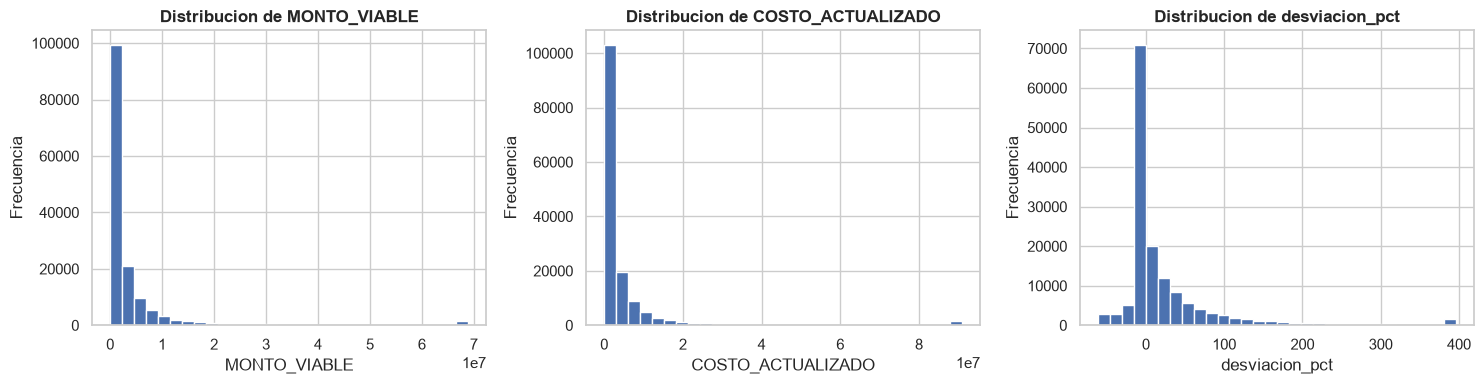

In [ ]:
import matplotlib.pyplot as plt

numeric_cols = ['MONTO_VIABLE', 'COSTO_ACTUALIZADO', 'desviacion_pct']

n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 5, n_rows * 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    clip_lo = df_valido[col].quantile(0.01)
    clip_hi = df_valido[col].quantile(0.99)
    df_valido[col].clip(clip_lo, clip_hi).hist(bins=30)
    plt.title(f'Distribucion de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

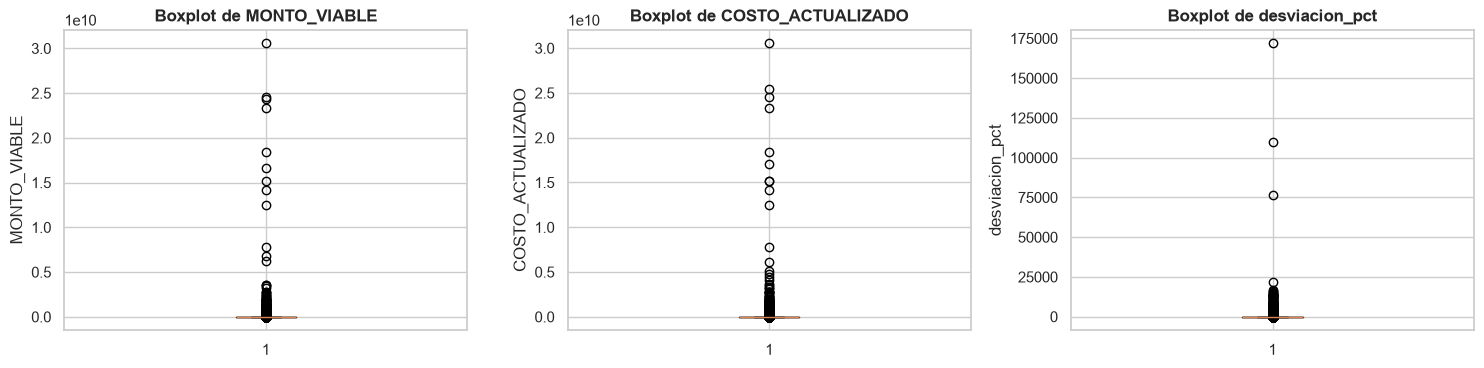

In [ ]:
plt.figure(figsize=(n_cols * 5, n_rows * 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.boxplot(df_valido[col].dropna())
    plt.title(f'Boxplot de {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

#### Variables categóricas

In [ ]:
categorical_cols = ['NIVEL', 'SECTOR', 'FUNCION', 'DES_MODALIDAD', 'TIPO_INVERSION', 'DEPARTAMENTO']
categorical_cols = [c for c in categorical_cols if c in df_valido.columns]

for col in categorical_cols:
    print(f'\n{col}')
    print(df_valido[col].value_counts().head(10))


NIVEL
NIVEL
GL    123617
GR     13500
GN     12661
Name: count, dtype: int64

SECTOR
SECTOR
GOBIERNOS LOCALES                       123617
GOBIERNOS REGIONALES                     13500
EDUCACION                                 2335
VIVIENDA, CONSTRUCCION Y SANEAMIENTO      1939
AGRICULTURA Y RIEGO                       1409
SALUD                                     1254
TRANSPORTES Y COMUNICACIONES              1215
FONAFE                                    1117
ESSALUD                                    818
INTERIOR                                   629
Name: count, dtype: int64

FUNCION
FUNCION
TRANSPORTE                                         36073
EDUCACIÓN                                          19488
SANEAMIENTO                                        19295
CULTURA Y DEPORTE                                  13280
PLANEAMIENTO, GESTIÓN Y RESERVA DE CONTINGENCIA    13172
AGROPECUARIA                                       11274
VIVIENDA Y DESARROLLO URBANO                        

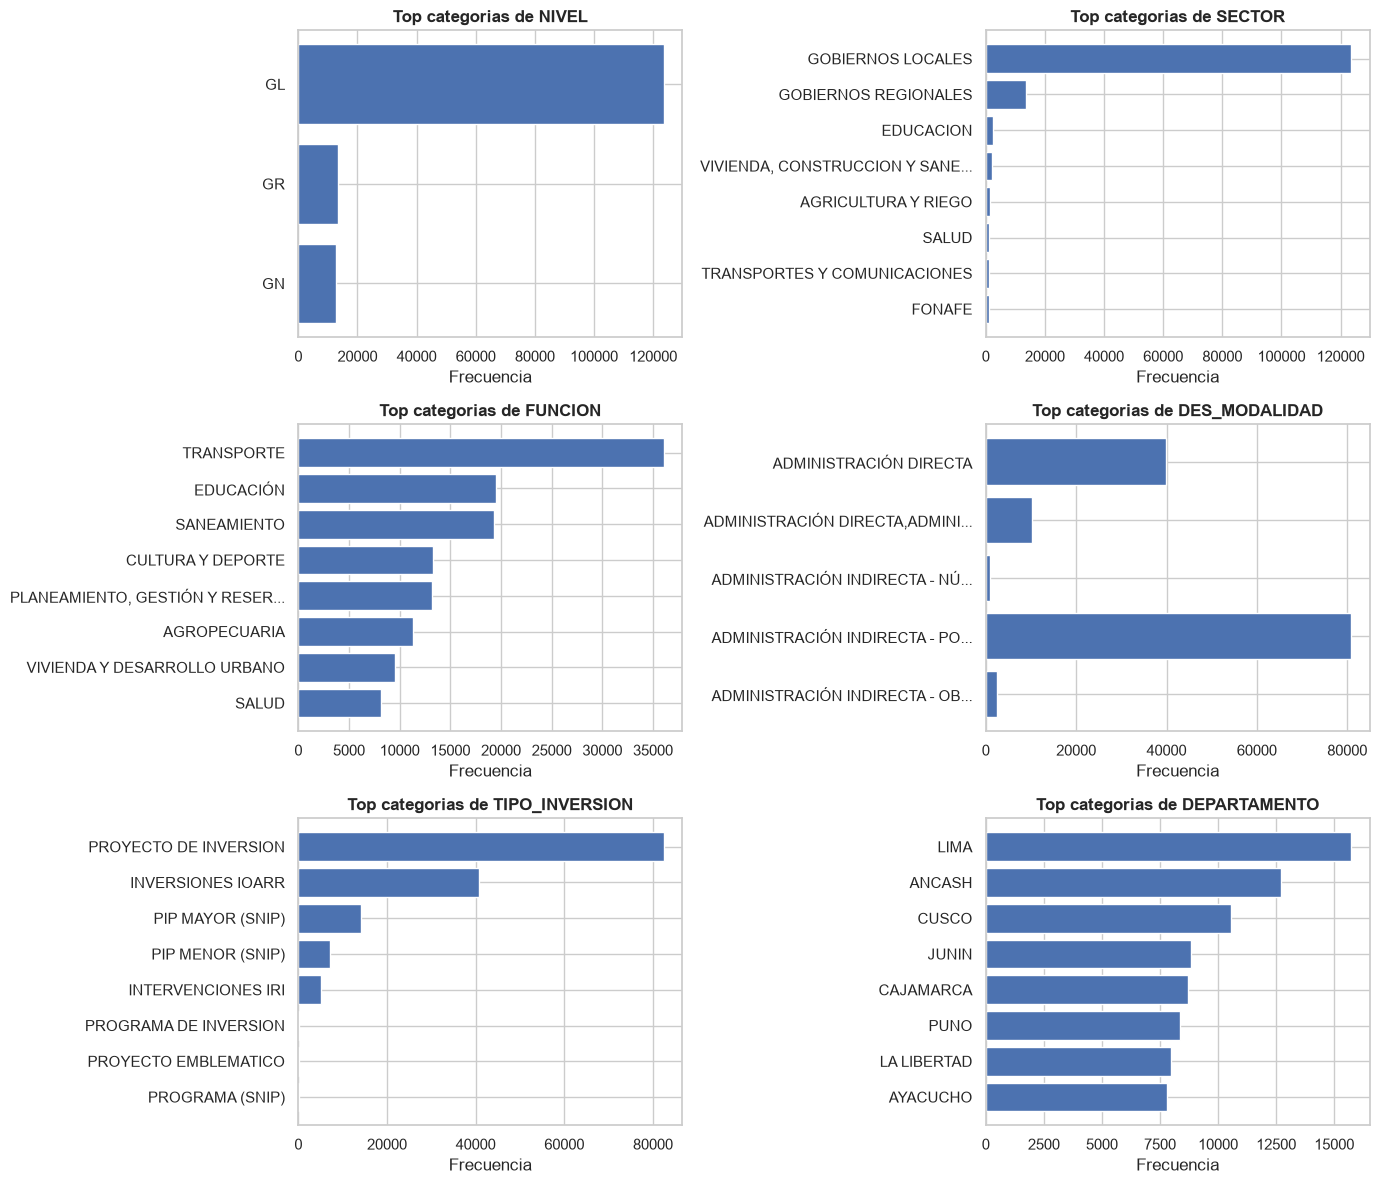

In [ ]:
def etiqueta_corta(texto, ancho=30):
    # Recorta etiquetas largas para que no desborden los graficos en grilla
    texto = str(texto)
    return texto if len(texto) <= ancho else texto[:ancho - 1] + '...'

n_cols_cat = 2
n_rows_cat = (len(categorical_cols) + n_cols_cat - 1) // n_cols_cat

fig, axes = plt.subplots(n_rows_cat, n_cols_cat, figsize=(n_cols_cat * 7, n_rows_cat * 4))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    top = df_valido[col].value_counts().head(8).sort_values()
    etiquetas = [etiqueta_corta(v) for v in top.index]
    axes[i].barh(etiquetas, top.values)
    axes[i].set_title(f'Top categorias de {col}')
    axes[i].set_xlabel('Frecuencia')

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 4.3 Análisis bivariado: relación con la variable objetivo

Ahora cruzamos cada predictora con desviacion_pct: desviación mediana por categoría y matriz de correlación entre numéricas. El objetivo es identificar qué variables tienen mayor poder discriminante antes del modelado.

#### Desviación mediana por categoría

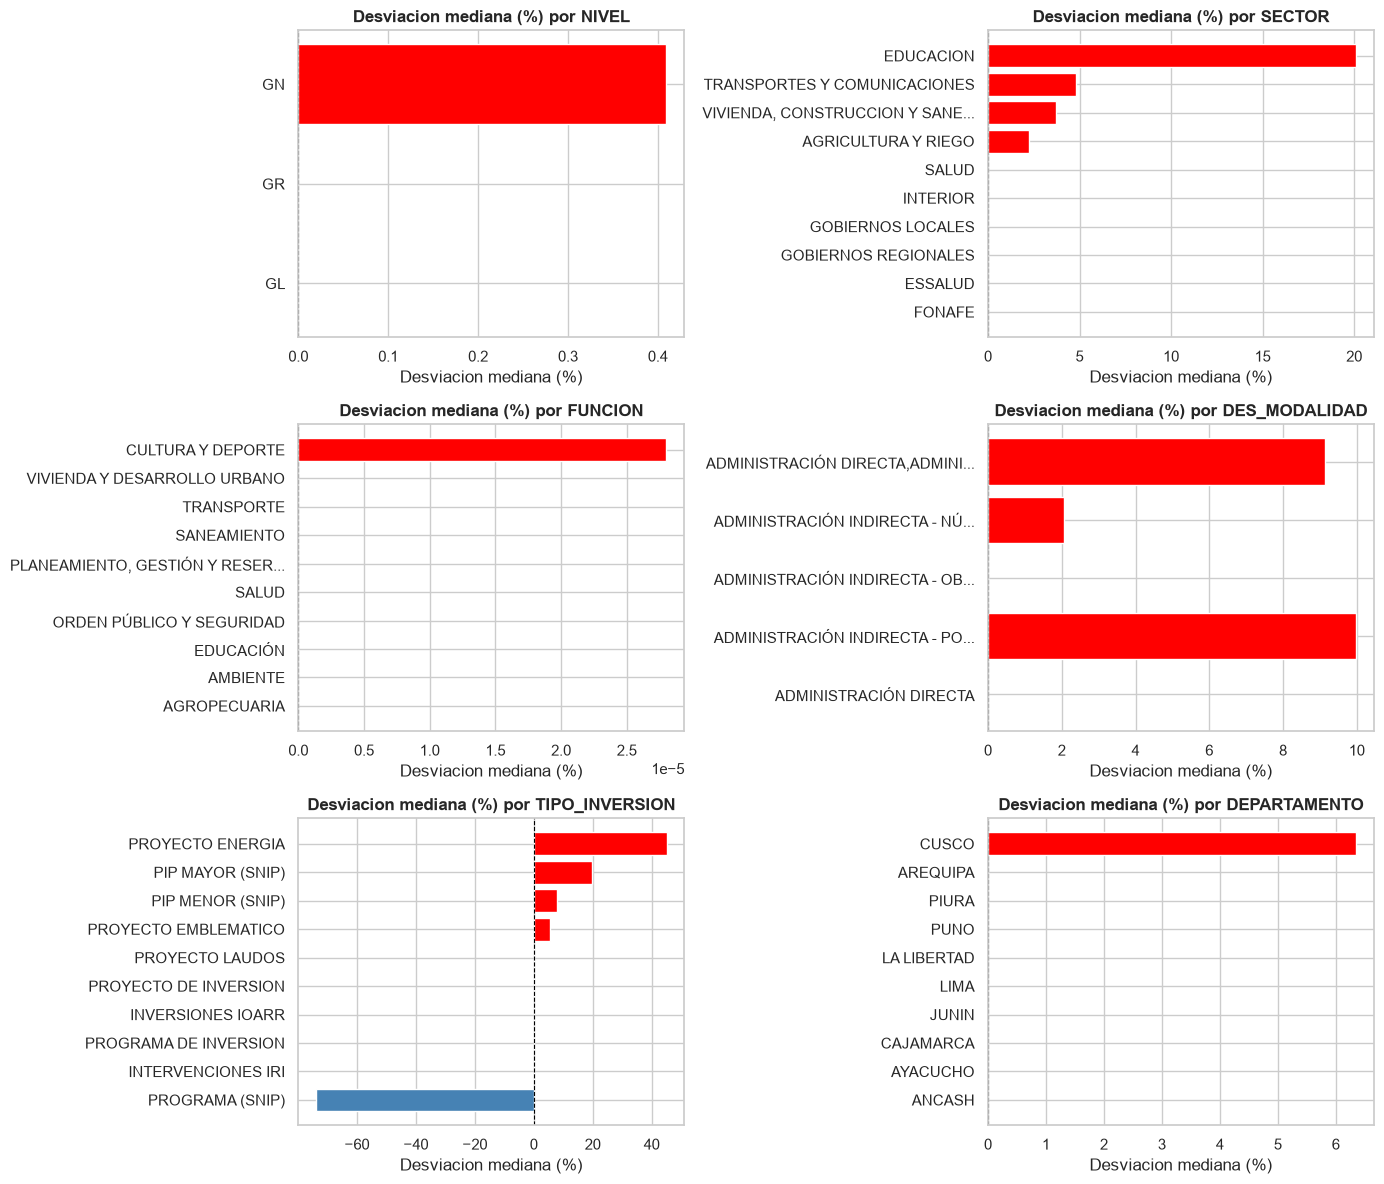

In [ ]:
n_cols_biv = 2
n_rows_biv = (len(categorical_cols) + n_cols_biv - 1) // n_cols_biv

fig, axes = plt.subplots(n_rows_biv, n_cols_biv, figsize=(n_cols_biv * 7, n_rows_biv * 4))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    top_cats = df_valido[col].value_counts().head(10).index
    resumen = (df_valido[df_valido[col].isin(top_cats)]
               .groupby(col)['desviacion_pct'].median().sort_values())
    etiquetas = [etiqueta_corta(v) for v in resumen.index]
    colores = ['red' if v > 0 else 'steelblue' for v in resumen.values]
    axes[i].barh(etiquetas, resumen.values, color=colores)
    axes[i].axvline(0, color='black', linewidth=0.8, linestyle='--')
    axes[i].set_title(f'Desviacion mediana (%) por {col}')
    axes[i].set_xlabel('Desviacion mediana (%)')

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Correlación entre variables numéricas

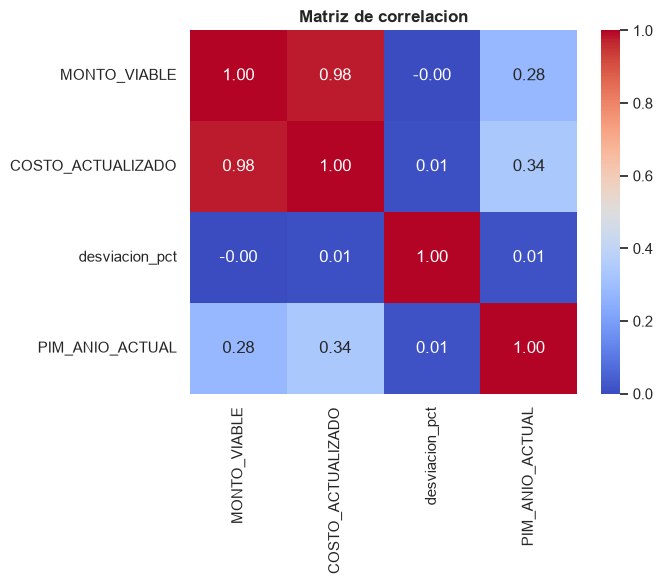

In [ ]:
cols_corr = ['MONTO_VIABLE', 'COSTO_ACTUALIZADO', 'desviacion_pct', 'PIM_ANIO_ACTUAL']
cols_corr = [c for c in cols_corr if c in df_valido.columns]
corr = df_valido[cols_corr].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlacion')
plt.tight_layout()
plt.show()

### 4.4 Deteccion de outliers con IQR
El rango intercuartílico (IQR)

In [ ]:
def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return (series < lower) | (series > upper)

df_valido['outlier_flag'] = detect_outliers_iqr(df_valido['desviacion_pct'])
print('Outliers en desviacion_pct:', int(df_valido['outlier_flag'].sum()),
      '(', round(df_valido['outlier_flag'].mean() * 100, 1), '% )')

Outliers en desviacion_pct: 22349 ( 14.9 % )


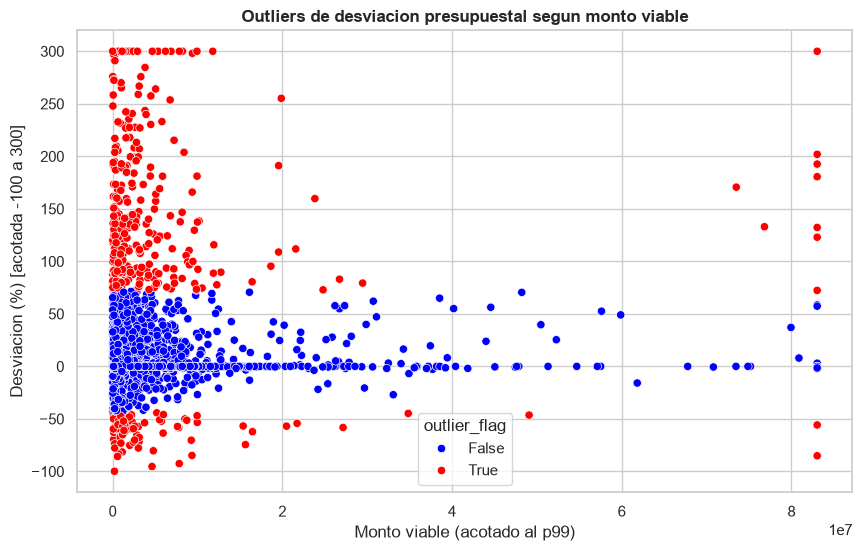

In [ ]:
muestra = df_valido.sample(min(3000, len(df_valido)), random_state=3791)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=muestra['MONTO_VIABLE'].clip(upper=muestra['MONTO_VIABLE'].quantile(0.99)),
                y=muestra['desviacion_pct'].clip(-100, 300),
                hue=muestra['outlier_flag'],
                palette={True: 'red', False: 'blue'})
plt.title('Outliers de desviacion presupuestal segun monto viable')
plt.xlabel('Monto viable (acotado al p99)')
plt.ylabel('Desviacion (%) [acotada -100 a 300]')
plt.show()

### 4.5 Extra: mapa de proyectos con folium

El dataset incluye LATITUD y LONGITUD. Ubicamos los 200 proyectos de mayor monto y coloreamos segun si tuvieron sobrecosto (rojo) o ahorro (azul).

In [ ]:
import folium

geo = df_valido.dropna(subset=['LATITUD', 'LONGITUD'])
geo = geo[(geo['LATITUD'].between(-18.5, 0)) & (geo['LONGITUD'].between(-82, -68))]
subdata = geo.sort_values('MONTO_VIABLE', ascending=False).head(200)

mapa = folium.Map(
    location=[-9.19, -75.02],
    zoom_start=5,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri'
)

for _, r in subdata.iterrows():
    color = 'red' if r['desviacion_pct'] > 0 else 'blue'
    popup_txt = str(r['NOMBRE_INVERSION'])[:45] + ' | ' + str(round(r['desviacion_pct'], 0)) + '%'
    folium.CircleMarker(location=[r['LATITUD'], r['LONGITUD']],
                         radius=4, color=color, fill=True,
                         popup=popup_txt).add_to(mapa)

mapa

### 4.6 Tendencia temporal + sesgo sin actualización


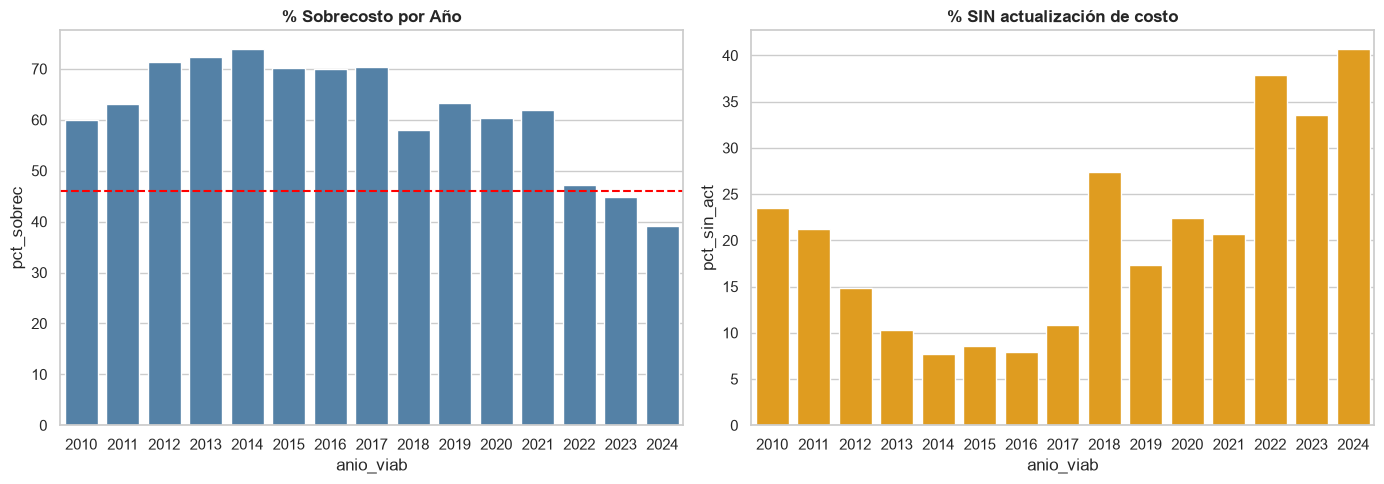

 anio_viab     n  mediana  pct_sobrec  pct_sin_act
      2010   893      9.2        59.9         23.5
      2011  1018     13.5        63.2         21.2
      2012  2077     20.2        71.4         14.8
      2013  2471     18.7        72.3         10.3
      2014  2027     23.5        73.9          7.7
      2015  3403     15.4        70.2          8.6
      2016  3906     16.5        70.0          7.9
      2017  3419     23.0        70.4         10.8
      2018  4978      7.3        58.0         27.4
      2019  9842      7.9        63.3         17.4
      2020  9899      8.4        60.4         22.4
      2021  9398      9.5        61.9         20.6
      2022 12135      0.0        47.2         37.9
      2023 21764      0.0        44.9         33.6
      2024 20640      0.0        39.2         40.7

⚠ Los años 2022-2024 muestran sesgo por falta de actualización (mediana≈0).


In [ ]:
# Extraer año de viabilidad (FECHA_VIABILIDAD todavía es string en esta sección)
# 1. Variables y Agregación (Todo en un solo bloque)
df_valido['anio_viab'] = pd.to_datetime(df_valido['FECHA_VIABILIDAD'], errors='coerce').dt.year
df_valido['sin_act'] = (df_valido['COSTO_ACTUALIZADO'] - df_valido['MONTO_VIABLE']).abs() < 1

temporal = df_valido.query('2010 <= anio_viab <= 2024').groupby('anio_viab').agg(
    n=('desviacion_pct', 'count'),
    mediana=('desviacion_pct', 'median'),
    pct_sobrec=('desviacion_pct', lambda x: (x > 0).mean() * 100),
    pct_sin_act=('sin_act', lambda x: x.mean() * 100)
).reset_index()

# 2. Visualización (Seaborn reduce 10 líneas a 4)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=temporal, x='anio_viab', y='pct_sobrec', ax=axes[0], color='steelblue').set_title('% Sobrecosto por Año')
axes[0].axhline(46, color='red', linestyle='--', label='Promedio 46%')

sns.barplot(data=temporal, x='anio_viab', y='pct_sin_act', ax=axes[1], color='orange').set_title('% SIN actualización de costo')

plt.tight_layout(); plt.show()

# 3. Resultado original impreso
print(temporal.round(1).to_string(index=False))
print("\n⚠ Los años 2022-2024 muestran sesgo por falta de actualización (mediana≈0).")


### 4.7 Análisis profundo (costo actualizado)


Proyectos con costo actualizado: 94,470 (63.1% del total)

FUNCION:
                                  n  mediana  pct_sobrec
FUNCION                                                 
ENERGIA Y RECURSOS MINERALES     85     46.2        90.6
AGRARIA                         166     42.5        89.2
SALUD Y SANEAMIENTO             402     39.9        85.3
PESCA                           107     36.1        76.6
EDUCACION Y CULTURA             397     23.5        80.6
EDUCACIÓN                     12444     22.4        76.2
COMERCIO                        580     22.2        76.0
ENERGÍA                        1991     20.9        76.0
TURISMO                         435     19.6        74.7
CULTURA Y DEPORTE              8800     18.8        75.4

DEPARTAMENTO:
                  n  mediana  pct_sobrec
DEPARTAMENTO                            
TACNA          1500     38.2        81.3
MOQUEGUA       1155     34.9        80.1
CUSCO          7313     31.4        79.5
AMAZONAS       2222     24.8

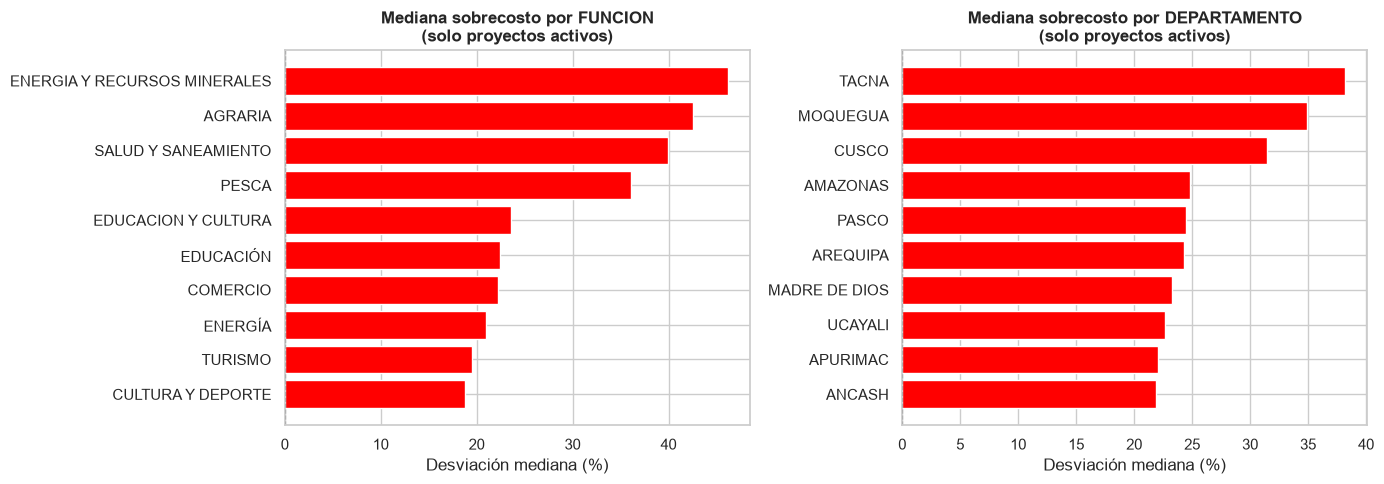

In [ ]:
# 1. Filtro de data activa
df_act = df_valido[~df_valido['sin_act']].copy()
print(f"Proyectos con costo actualizado: {len(df_act):,} ({len(df_act)/len(df_valido):.1%} del total)\n")

# 2. Configuración: {Columna: Mínimo de proyectos para el filtro}
config_analisis = {'FUNCION': 50, 'DEPARTAMENTO': 100}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (col, min_n) in enumerate(config_analisis.items()):
    # Agregación y filtrado encadenado
    res = (df_act.groupby(col)['desviacion_pct']
           .agg(n='count', mediana='median', pct_sobrec=lambda x: (x>0).mean()*100)
           .query(f'n >= {min_n}')
           .sort_values('mediana', ascending=False).head(10))

    # Renderizado del gráfico
    colors = ['red' if v > 0 else 'steelblue' for v in res['mediana']]
    axes[i].barh([etiqueta_corta(v) for v in res.index], res['mediana'], color=colors)
    axes[i].axvline(0, color='black', lw=0.8, ls='--')
    axes[i].set(title=f'Mediana sobrecosto por {col}\n(solo proyectos activos)', xlabel='Desviación mediana (%)')
    axes[i].invert_yaxis() # Pone el valor más alto arriba

    # Imprimir tablas resumen
    print(f"{col}:\n{res.round(1).to_string(index=True)}\n")

plt.tight_layout()
plt.show()

### 4.8 Efecto del tamaño

In [ ]:
import scipy.stats as stats

df_valido['tam_obra'] = pd.cut(
    df_valido['MONTO_VIABLE'],
    bins=[0, 5e5, 5e6, float('inf')],
    labels=['Pequeña (<S/0.5M)', 'Mediana (S/0.5–5M)', 'Grande (>S/5M)']
)

tam = (df_valido.groupby('tam_obra', observed=True)
    .agg(n=('desviacion_pct','count'),
         mediana=('desviacion_pct','median'),
         pct_sobrec=('desviacion_pct', lambda x: (x>0).mean()*100))
    .reset_index())
print(tam.round(1).to_string(index=False))

datos = df_valido[['MONTO_VIABLE','desviacion_pct']].dropna()
r, p = stats.spearmanr(np.log1p(datos['MONTO_VIABLE']), datos['desviacion_pct'])
print(f"\nSpearman log(monto) vs desviación_pct: r = {r:.3f}  (p = {p:.4f})")
print("→ Correlación prácticamente nula: el tamaño no predice el sobrecosto.")
print("  Las variables categóricas (FUNCION, DEPARTAMENTO, NIVEL) son más relevantes.")

          tam_obra     n  mediana  pct_sobrec
 Pequeña (<S/0.5M) 47092      0.0        47.4
Mediana (S/0.5–5M) 75711      0.0        45.6
    Grande (>S/5M) 26975      0.0        44.7

Spearman log(monto) vs desviación_pct: r = -0.010  (p = 0.0001)
→ Correlación prácticamente nula: el tamaño no predice el sobrecosto.
  Las variables categóricas (FUNCION, DEPARTAMENTO, NIVEL) son más relevantes.


### 4.9 Análisis de influencia de variables con pocos o ningún valor faltante

Variables sin valores faltantes (o con pocos) pero sin influencia en la variable objetivo también deben eliminarse. Aquí se evalúan todas las variables con ≤5% de faltantes que no son identificadores ni variables de fuga.

Las columnas de fecha se excluyen porque se transforman en la sección 5.2 (plazo_dias, anio_viabilidad). MONTO_VIABLE se analizó por separado en la sección 4.11.

In [ ]:
import scipy.stats as stats
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

##Variables de fuga (ya excluidas del modelo):
#Hemos identificado y aislado 18 variables de 'fuga de información'. Estas variables contienen datos de la ejecución de la obra
# que no están disponibles al inicio del proyecto. Al excluirlas, aseguramos que nuestro modelo sea un verdadero sistema
#preventivo y no una obviedad estadística."
FUGA = {
    'COSTO_ACTUALIZADO','AVANCE_FISICO','AVANCE_EJECUCION','DEV_ANIO_ACTUAL',
    'SALDO_EJECUTAR','DEVEN_ACUMUL_ANIO_ANT','ULTIMO_DEVENGADO','PRIMER_DEVENGADO',
    'CERTIF_ANIO_ACTUAL','COMPROM_ANUAL_ANIO_ACTUAL','SITUACION','ESTADO',
    'ETAPA_F8','ETAPA_F9','FEC_REG_F9','FEC_FIN_EJEC_FISICA','FEC_INI_EJEC_FISICA',
    'ULT_FEC_DECLA_ESTIM'
}

In [ ]:
# Identificadores y descriptivos (sin valor predictivo por definición):
#Separamos códigos únicos, nombres y ubicaciones específicas que solo sirven para etiquetar cada proyecto de forma individual.
#Estas columnas se eliminan porque su alta variedad impide que el modelo generalice patrones aplicables a obras nuevas.
#Su exclusión evita que el algoritmo memorice casos particulares (overfitting) en lugar de aprender tendencias estadísticas reales.
IDENTIFICADORES = {
    'CODIGO_UNICO','NOMBRE_INVERSION','UBIGEO','SEC_EJEC','CODIGO_SNIP',
    'NOMBRE_UEI','NOMBRE_OPMI','NOMBRE_UEP','NOMBRE_UF','ENTIDAD'
}

# Columnas derivadas creadas en este notebook (no son variables originales)
#Agrupamos la variable objetivo ( Y Y ) y los cálculos propios realizados durante la exploración y limpieza de la base de datos.
#Se aíslan para que el análisis de importancia se realice exclusivamente sobre los datos originales y puros del MEF. Esto permite
#evaluar con total objetividad cómo influyen los factores iniciales del proyecto sobre el porcentaje de sobrecosto.
DERIVADAS = {
    'desviacion_pct','desviacion_pct_cap','outlier_flag',
    'anio_viab','sin_actualizar','tam_obra'
}


In [ ]:

# MONTO_VIABLE ya se analizó en 4.11; las fechas se transforman en 5.2
YA_CUBIERTAS = {'MONTO_VIABLE'}

# ── 1. Variables candidatas: ≤5% faltantes ──────────────────
#Calculamos el porcentaje de valores nulos por columna para conservar únicamente aquellas con alta integridad de información (umbral menor al 5%),
# filtrando el dataset al excluir sistemáticamente las variables marcadas como fugas, identificadores únicos y columnas derivadas. De esta manera,
# obtenemos el listado definitivo de "Variables Candidatas" que están estadísticamente aptas para ser evaluadas mediante las pruebas de importancia y
#correlación necesarias para el modelo predictivo.
miss_pct = df.isnull().mean() * 100
candidatas = miss_pct[
    (miss_pct <= 5) &
    (~miss_pct.index.isin(FUGA)) &
    (~miss_pct.index.isin(IDENTIFICADORES)) &
    (~miss_pct.index.isin(DERIVADAS)) &
    (~miss_pct.index.isin(YA_CUBIERTAS))
].sort_values()

print(f"Variables a analizar (≤5% faltantes): {len(candidatas)}\n")


Variables a analizar (≤5% faltantes): 28



In [ ]:


# ── 2. Clasificar por tipo ──────────────────────────────────
#Este bloque de código actúa como un filtro inteligente que clasifica las variables del proyecto en dos categorías: numéricas y categóricas.
# Mediante una prueba de conversión, el algoritmo identifica qué columnas contienen principalmente datos cuantitativos y cuáles contienen etiquetas o texto,
# permitiendo organizar el flujo de trabajo para aplicar el análisis estadístico correcto a cada tipo de dato en las etapas siguientes.
numericas, categoricas = [], []
for col in candidatas.index:
    if pd.to_numeric(df[col], errors='coerce').notna().mean() > 0.3:
        numericas.append(col)
    else:
        categoricas.append(col)

# ── 3. Numéricas: Spearman con desviacion_pct ───────────────
#Evaluamos la relación entre cada variable numérica y el porcentaje de sobrecosto mediante el coeficiente de correlación de Spearman,
#una métrica estadística que mide la fuerza de asociación entre dos variables. El proceso filtra columnas con muestras insuficientes (menos de 200 registros)
# y calcula el impacto real de cada predictor sobre la desviación presupuestal; finalmente, se aplica un criterio técnico para conservar únicamente las variables
#con un efecto significativo (correlación ≥ 0.05  ), eliminando aquellas que no poseen valor predictivo para el modelo.
resultados = []
for col in numericas:
    datos = df_valido[[col, 'desviacion_pct']].copy()
    datos[col] = pd.to_numeric(datos[col], errors='coerce')
    datos = datos.dropna()
    if len(datos) < 200: continue
    r, _ = stats.spearmanr(datos[col], datos['desviacion_pct'])
    resultados.append({
        'Variable': col, 'Tipo': 'Numérica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'Spearman |r|',
        'Efecto': round(abs(r), 4),
        'Decisión': 'MANTENER' if abs(r) >= 0.05 else 'ELIMINAR'
    })

In [ ]:
# ── 4. Categóricas: Kruskal-Wallis + eta² ──────────────────
#Este bloque evalúa el impacto de las variables categóricas sobre el sobrecosto mediante el test no paramétrico de Kruskal-Wallis,
# el cual determina si existen diferencias estadísticamente significativas entre los distintos grupos de una categoría (ej. diferentes sectores o regiones).
# Para cuantificar la magnitud de esta influencia, calculamos el efecto de tamaño mediante la métrica Eta cuadrado ( η 2 η 2 ), lo que permite identificar qué
# variables explican mejor la varianza del sobrecosto; finalmente, aplicamos un criterio de selección para conservar únicamente los predictores con significancia
# estadística ( p<0.05 ) y un tamaño de efecto relevante ( η 2 ≥ 0.001 ), descartando el ruido y las columnas de fechas detectadas automáticamente.
fechas_detectadas = []
for col in categoricas:
    # Detectar si es una fecha disfrazada de categórica
    if pd.to_datetime(df[col], errors='coerce').notna().mean() > 0.5:
        fechas_detectadas.append(col)
        continue
    datos = df_valido[[col, 'desviacion_pct']].dropna()
    if len(datos) < 200 or datos[col].nunique() < 2: continue
    grupos = [g['desviacion_pct'].values for _, g in datos.groupby(col) if len(g) >= 30]
    if len(grupos) < 2: continue
    stat, p = stats.kruskal(*grupos)
    n, k = len(datos), len(grupos)
    eta2 = round(max(0.0, (stat - k + 1) / (n - k)), 4)
    resultados.append({
        'Variable': col, 'Tipo': 'Categórica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'eta²',
        'Efecto': eta2,
        'Decisión': 'MANTENER' if (p < 0.05 and eta2 >= 0.001) else 'ELIMINAR'
    })

if fechas_detectadas:
    print(f"Fechas detectadas (no se evaluaron con Kruskal-Wallis): {fechas_detectadas}\n")
    for fecha_col in fechas_detectadas:
        if fecha_col == 'FECHA_VIABILIDAD':
            print(f"- {fecha_col}: SE USA via anio_viabilidad (feature engineering, seccion 5.3).\n")
            continue

        # Verificamos si esta fecha aporta informacion MAS ALLA de FECHA_VIABILIDAD,
        # o si es simplemente una copia casi identica (redundante).
        anio_col  = pd.to_datetime(df[fecha_col], errors='coerce').dt.year
        anio_viab = pd.to_datetime(df['FECHA_VIABILIDAD'], errors='coerce').dt.year
        y_target  = df_valido['desviacion_pct'].reindex(df.index)

        datos_f = pd.DataFrame({'anio': anio_col, 'anio_viab': anio_viab, 'y': y_target}).dropna()

        r_bruto, _   = stats.spearmanr(datos_f['anio'], datos_f['y'])
        r_vs_viab, _ = stats.spearmanr(datos_f['anio'], datos_f['anio_viab'])

        r_parciales = []
        for _, g in datos_f.groupby('anio_viab'):
            if len(g) >= 100:
                rg, _ = stats.spearmanr(g['anio'], g['y'])
                r_parciales.append(rg)
        r_parcial_prom = np.nanmean(r_parciales)

        print(f"- {fecha_col}:")
        print(f"    Spearman bruto vs desviacion_pct: {r_bruto:.4f}")
        print(f"    Correlacion con anio_viabilidad:   {r_vs_viab:.4f}")
        print(f"    Spearman parcial (controlando anio_viabilidad): {r_parcial_prom:.4f}")

        if abs(r_vs_viab) > 0.9 and abs(r_parcial_prom) < 0.05:
            print(f"    -> ELIMINAR: {fecha_col} esta casi perfectamente correlacionada con "
                  f"FECHA_VIABILIDAD; su correlacion bruta con el target es redundante "
                  f"(desaparece al controlar por anio_viabilidad), no aporta informacion nueva.\n")
        else:
            print(f"    -> Revisar manualmente: la correlacion no se explica solo por redundancia.\n")

df_res = pd.DataFrame(resultados).sort_values('Efecto', ascending=False)

Fechas detectadas (no se evaluaron con Kruskal-Wallis): ['FECHA_REGISTRO', 'FECHA_VIABILIDAD']



- FECHA_REGISTRO:
    Spearman bruto vs desviacion_pct: -0.2346
    Correlacion con anio_viabilidad:   0.9963
    Spearman parcial (controlando anio_viabilidad): -0.0822
    -> Revisar manualmente: la correlacion no se explica solo por redundancia.

- FECHA_VIABILIDAD: SE USA via anio_viabilidad (feature engineering, seccion 5.3).



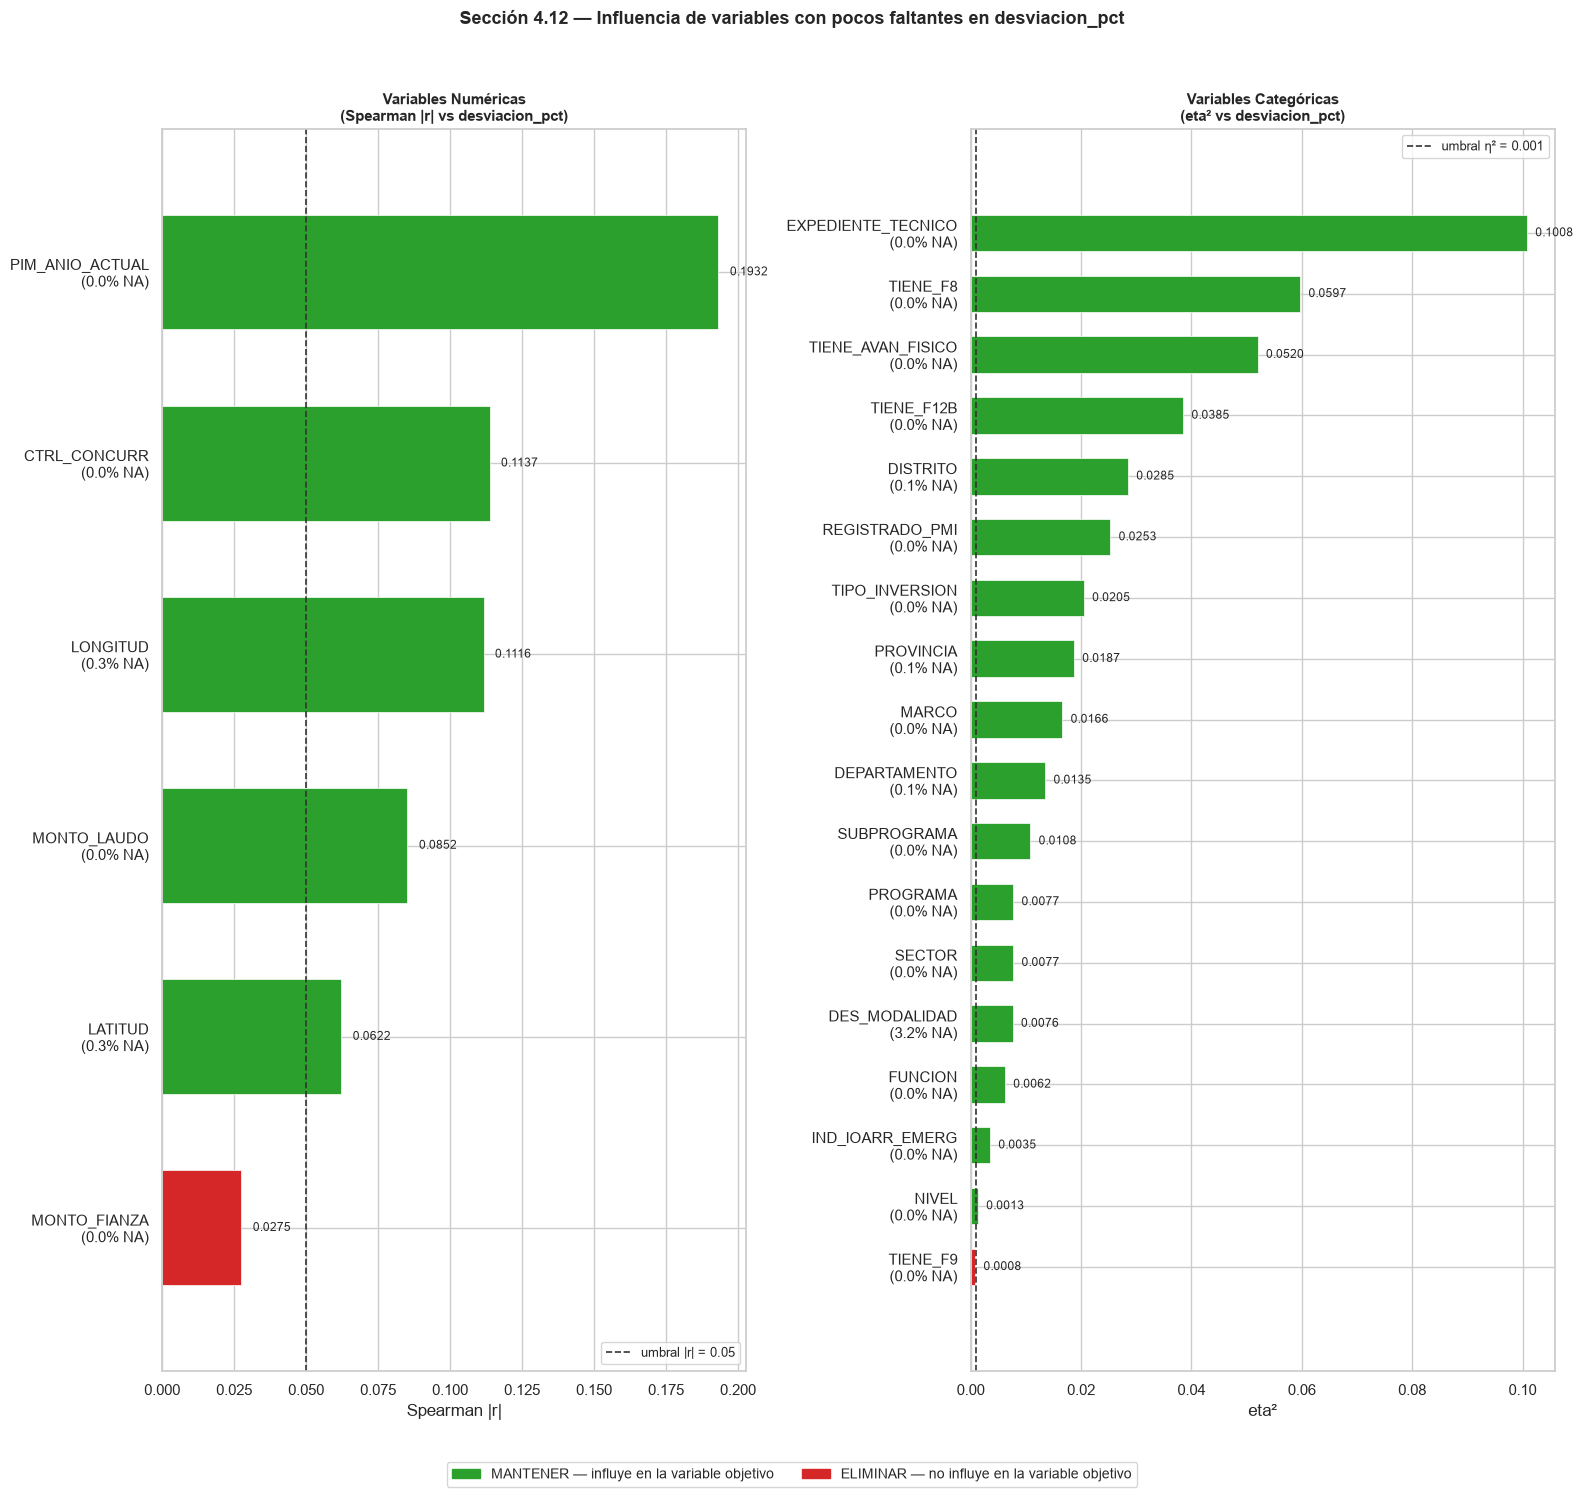

In [ ]:



# ── 5. Gráfico de barras (2 paneles) ────────────────────────
VERDE, ROJO = '#2ca02c', '#d62728'
col_map = {'MANTENER': VERDE, 'ELIMINAR': ROJO}

tipos  = [('Numérica',   'Spearman |r|', 0.05,  'umbral |r| = 0.05'),
          ('Categórica', 'eta²',         0.001, 'umbral η² = 0.001')]
n_rows = max(4, len(df_res) // 2 + 2)
fig, axes = plt.subplots(1, 2, figsize=(16, n_rows))

for ax, (tipo, metrica_label, umbral, umbral_label) in zip(axes, tipos):
    sub = df_res[df_res['Tipo'] == tipo].sort_values('Efecto')
    if sub.empty:
        ax.text(0.5, 0.5, f'Sin variables {tipo}s\nen este grupo',
                ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.axis('off')
        continue
    etiquetas = sub['Variable'] + '\n(' + sub['Missing %'].astype(str) + '% NA)'
    colores   = sub['Decisión'].map(col_map)
    bars      = ax.barh(etiquetas, sub['Efecto'], color=colores,
                        edgecolor='white', linewidth=0.5, height=0.6)
    ax.axvline(umbral, color='#333', linestyle='--', linewidth=1.2, label=umbral_label)
    for bar, val in zip(bars, sub['Efecto']):
        offset = max(sub['Efecto'].max() * 0.015, umbral * 0.08)
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8.5)
    ax.set_title(f'Variables {tipo}s\n({metrica_label} vs desviacion_pct)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel(metrica_label)
    ax.legend(fontsize=9)
    ax.margins(y=0.08)

leyenda = [Patch(color=VERDE, label='MANTENER — influye en la variable objetivo'),
           Patch(color=ROJO,  label='ELIMINAR — no influye en la variable objetivo')]
fig.legend(handles=leyenda, loc='lower center', ncol=2, fontsize=10,
           bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Sección 4.12 — Influencia de variables con pocos faltantes en desviacion_pct',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()



In [ ]:
# ── 6. Tabla estilizada ─────────────────────────────────────
def _color_fila(row):
    bg = '#d5f5e3' if row['Decisión'] == 'MANTENER' else '#fadbd8'
    return [f'background-color: {bg}'] * len(row)

display(df_res.style
    .apply(_color_fila, axis=1)
    .format({'Missing %': '{:.1f}%', 'Efecto': '{:.4f}'})
    .set_caption('Tabla 4.12 — Variables con pocos faltantes: ¿mantener o eliminar?')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size','13px'), ('font-weight','bold'), ('margin-bottom','8px')]},
        {'selector': 'th',
         'props': [('background-color','#2c3e50'), ('color','white'), ('font-size','11px')]}
    ])
    .hide(axis='index'))



Variable,Tipo,Missing %,Métrica,Efecto,Decisión
PIM_ANIO_ACTUAL,Numérica,0.0%,Spearman |r|,0.1932,MANTENER
CTRL_CONCURR,Numérica,0.0%,Spearman |r|,0.1137,MANTENER
LONGITUD,Numérica,0.3%,Spearman |r|,0.1116,MANTENER
EXPEDIENTE_TECNICO,Categórica,0.0%,eta²,0.1008,MANTENER
MONTO_LAUDO,Numérica,0.0%,Spearman |r|,0.0852,MANTENER
LATITUD,Numérica,0.3%,Spearman |r|,0.0622,MANTENER
TIENE_F8,Categórica,0.0%,eta²,0.0597,MANTENER
TIENE_AVAN_FISICO,Categórica,0.0%,eta²,0.0520,MANTENER
TIENE_F12B,Categórica,0.0%,eta²,0.0385,MANTENER
DISTRITO,Categórica,0.1%,eta²,0.0285,MANTENER


In [ ]:
# ── 7. Resumen final ────────────────────────────────────────
mantener = df_res[df_res['Decisión'] == 'MANTENER']['Variable'].tolist()
eliminar = df_res[df_res['Decisión'] == 'ELIMINAR']['Variable'].tolist()
print(f"\nMANTENER ({len(mantener)} vars): {mantener}")
print(f"ELIMINAR ({len(eliminar)} vars): {eliminar}")
print("\nNota: MONTO_VIABLE se analizó en 4.11 (Spearman r ≈ -0.01, sin efecto")
print("monotónico). Se mantiene porque se usa para crear monto_viable_log en 5.2")
print("y puede tener efectos no lineales que capturan Random Forest y Gradient Boosting.")


MANTENER (22 vars): ['PIM_ANIO_ACTUAL', 'CTRL_CONCURR', 'LONGITUD', 'EXPEDIENTE_TECNICO', 'MONTO_LAUDO', 'LATITUD', 'TIENE_F8', 'TIENE_AVAN_FISICO', 'TIENE_F12B', 'DISTRITO', 'REGISTRADO_PMI', 'TIPO_INVERSION', 'PROVINCIA', 'MARCO', 'DEPARTAMENTO', 'SUBPROGRAMA', 'SECTOR', 'PROGRAMA', 'DES_MODALIDAD', 'FUNCION', 'IND_IOARR_EMERG', 'NIVEL']
ELIMINAR (3 vars): ['MONTO_FIANZA', 'TIENE_F9', 'ANIO_PROCESO']

Nota: MONTO_VIABLE se analizó en 4.11 (Spearman r ≈ -0.01, sin efecto
monotónico). Se mantiene porque se usa para crear monto_viable_log en 5.2
y puede tener efectos no lineales que capturan Random Forest y Gradient Boosting.


### 4.10 Muchos faltantes: imputar/eliminar
Las variables con muchos NAs se clasifican en dos grupos:
- **Sin influencia en desviacion_pct** → se eliminan del pipeline
- **Con influencia en desviacion_pct** → se imputan (mediana para numéricas, moda para categóricas)

El análisis se separa por tipo de variable porque los tests estadísticos difieren.

In [ ]:
import scipy.stats as stats
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')
#solo estamos definiendo que hacer cuando se presente con uno de esos "enfermos" detectados por el inspector.
# Variables de fuga (excluir del análisis)
#Este bloque establece los criterios técnicos y de negocio para el tratamiento de variables con alta proporción de datos faltantes, diferenciando entre la eliminación de
#predictores irrelevantes y la imputación de aquellos con valor predictivo. Mediante una función lógica personalizada, el algoritmo determina el método de limpieza más adecuado
#según la naturaleza del dato: asigna valores constantes de cero a variables presupuestales (PMI/PIA/PIM) basándose en el contexto del sistema Invierte.pe, utiliza la moda para
# etiquetas categóricas y la mediana para variables numéricas y fechas. Este enfoque garantiza que la reconstrucción de la información faltante sea estadísticamente robusta y
#coherente con la realidad operativa de los proyectos de inversión pública.
FUGA = {
    'COSTO_ACTUALIZADO','AVANCE_FISICO','AVANCE_EJECUCION','DEV_ANIO_ACTUAL',
    'SALDO_EJECUTAR','DEVEN_ACUMUL_ANIO_ANT','ULTIMO_DEVENGADO','PRIMER_DEVENGADO',
    'CERTIF_ANIO_ACTUAL','COMPROM_ANUAL_ANIO_ACTUAL','SITUACION','ESTADO',
    'ETAPA_F8','ETAPA_F9','FEC_REG_F9','FEC_FIN_EJEC_FISICA','FEC_INI_EJEC_FISICA',
    'ULT_FEC_DECLA_ESTIM'
}

def elegir_metodo_imputacion(variable, tipo, decision):
    # Solo tiene sentido un metodo si la variable se va a IMPUTAR
    if decision == 'ELIMINAR':
        return '— (se elimina)'
    var_upper = variable.upper()
    if tipo == 'Categórica':
        # Algunas columnas de fecha quedan mal clasificadas como categoricas
        # (pd.to_numeric falla en fechas); las detectamos aqui.
        es_fecha = pd.to_datetime(df[variable], errors='coerce').notna().mean() > 0.5
        return 'Mediana (fecha)' if es_fecha else 'Moda (mas frecuente)'
    else:
        # PMI/PIA/PIM: el NaN suele significar "no incluido en ese ciclo
        # presupuestal", no un valor desconocido -> 0 es mas correcto que la mediana
        if any(p in var_upper for p in ['PMI_ANIO', 'PIA_ANIO', 'PIM_ANIO']):
            return 'Constante = 0'
        return 'Mediana'

In [ ]:
# ── 1. Variables candidatas (>5% faltantes, sin fuga) ─────────
#Este bloque de código filtra el conjunto de datos para identificar variables que presentan una proporción de datos faltantes superior al 5%, excluyendo
#simultáneamente aquellas identificadas previamente como variables de fuga. El objetivo es aislar los predictores que requieren un tratamiento especial de
#limpieza o imputación debido a su nivel de incompletitud, ordenándolos de mayor a menor impacto de nulidad para priorizar el análisis de su relevancia estadística frente al sobrecosto presupuestal.
miss_pct  = df.isnull().mean() * 100
candidatas = miss_pct[(miss_pct > 5) & (~miss_pct.index.isin(FUGA))].sort_values(ascending=False)

In [ ]:

# ── 2. Clasificar por tipo ────────────────────────────────────
#Este bloque realiza una clasificación técnica de las variables que presentan más de un 5% de datos faltantes, dividiéndolas en grupos numéricos y categóricos. Mediante
#un test de conversión de datos, el algoritmo identifica la naturaleza de cada predictor para determinar la estrategia de imputación más adecuada; esto asegura que, en el
# siguiente paso, se aplique correctamente la mediana para reconstruir valores cuantitativos y la moda para etiquetas de texto, preservando así la coherencia estadística del dataset de inversiones antes de entrar al modelo.
numericas_miss, categoricas_miss = [], []
for col in candidatas.index:
    if pd.to_numeric(df[col], errors='coerce').notna().mean() > 0.3:
        numericas_miss.append(col)
    else:
        categoricas_miss.append(col)

In [ ]:
# ── 3. Numéricas: Spearman con desviacion_pct ─────────────────
#Este bloque de código ejecuta un análisis de correlación de Spearman sobre las variables numéricas que presentan más del 5% de datos faltantes para determinar su utilidad predictiva.
#El algoritmo evalúa la fuerza de asociación de cada predictor con el sobrecosto presupuestal; si la variable supera el umbral de significancia ( ∣ r ∣ ≥ 0.05 ), se marca para ser
# "imputada" (reparada) mediante la lógica de negocio previamente definida, de lo contrario, se elimina del dataset. Este proceso de triaje asegura que solo se apliquen técnicas de
#reconstrucción de datos sobre variables que aportan valor real al modelo, evitando la introducción de ruido estadístico innecesario.
resultados = []
for col in numericas_miss:
    datos = df_valido[[col, 'desviacion_pct']].copy()
    datos[col] = pd.to_numeric(datos[col], errors='coerce')
    datos = datos.dropna()
    if len(datos) < 200: continue
    r, _ = stats.spearmanr(datos[col], datos['desviacion_pct'])
    decision = 'IMPUTAR' if abs(r) >= 0.05 else 'ELIMINAR'
    resultados.append({
        'Variable': col, 'Tipo': 'Numérica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'Spearman |r|',
        'Efecto': round(abs(r), 4),
        'Decisión': decision,
        'Método imputación': elegir_metodo_imputacion(col, 'Numérica', decision)
    })

In [ ]:

# ── 4. Categóricas: Kruskal-Wallis + eta² ────────────────────
#En este bloque, se realiza un análisis de importancia sobre las variables categóricas que presentan más del 5% de datos faltantes, utilizando el test
#de Kruskal-Wallis y la métrica de efecto Eta cuadrado ( η 2 ). El objetivo es determinar si una variable, a pesar de estar incompleta, posee un impacto estadísticamente
# significativo y material sobre el sobrecosto presupuestal; aquellas que superan los umbrales de significancia ( p < 0.05 ) y de tamaño de efecto ( η 2 ≥ 0.001  )
 #son marcadas para ser reconstruidas mediante técnicas de imputación, mientras que las variables irrelevantes son eliminadas. Este procedimiento asegura una selección rigurosa de
 #predictores, optimizando la calidad de la información que alimentará el modelo final de Machine Learning.
for col in categoricas_miss:
    datos = df_valido[[col, 'desviacion_pct']].dropna()
    if len(datos) < 200 or datos[col].nunique() < 2: continue
    grupos = [g['desviacion_pct'].values for _, g in datos.groupby(col) if len(g) >= 30]
    if len(grupos) < 2: continue
    stat, p = stats.kruskal(*grupos)
    n, k  = len(datos), len(grupos)
    eta2  = round(max(0.0, (stat - k + 1) / (n - k)), 4)
    decision = 'IMPUTAR' if (p < 0.05 and eta2 >= 0.001) else 'ELIMINAR'
    resultados.append({
        'Variable': col, 'Tipo': 'Categórica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'eta²',
        'Efecto': eta2,
        'Decisión': decision,
        'Método imputación': elegir_metodo_imputacion(col, 'Categórica', decision)
    })

df_res = pd.DataFrame(resultados).sort_values('Missing %', ascending=False)

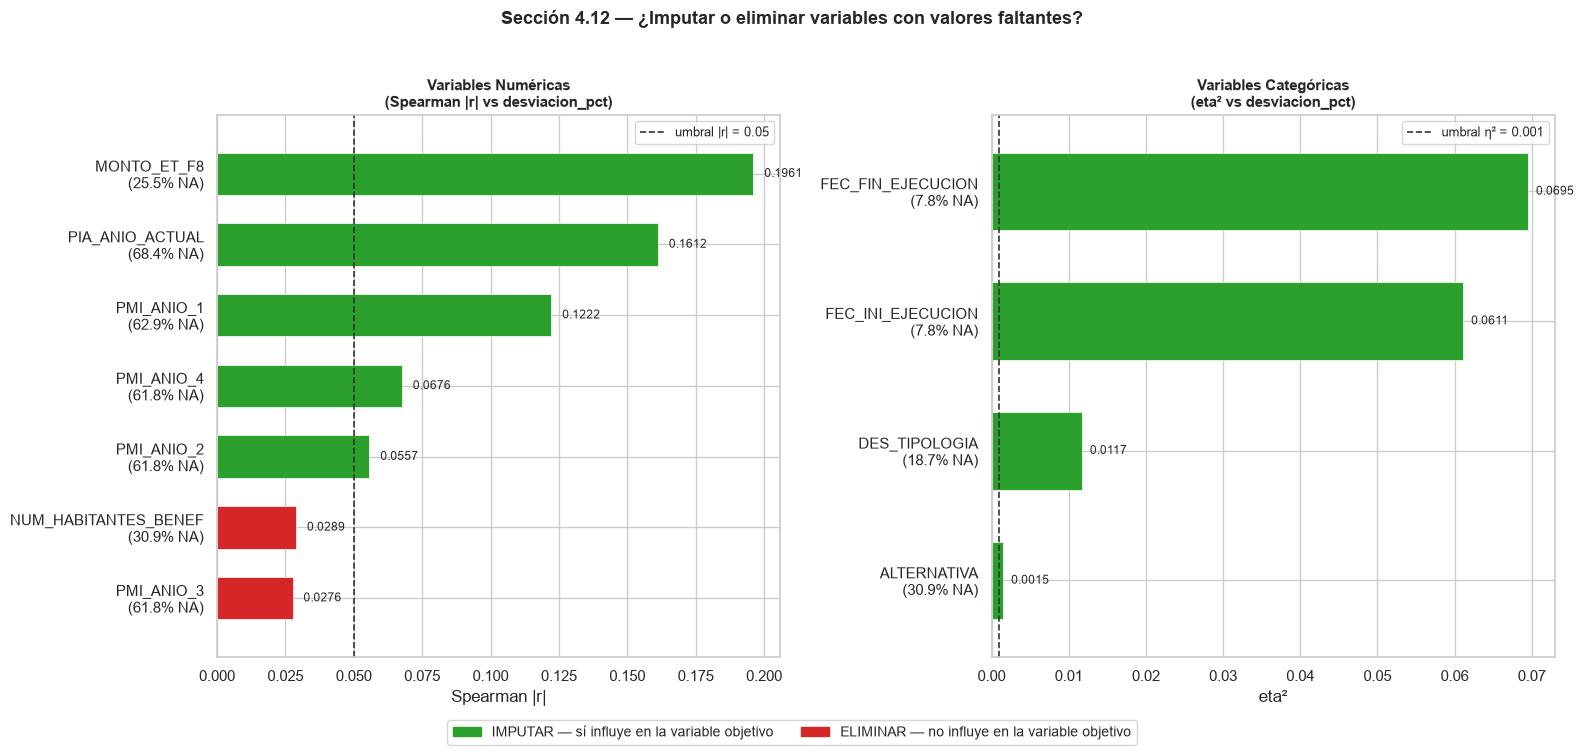

In [ ]:


# ── 5. Gráfico de barras (2 paneles) ─────────────────────────
VERDE, ROJO = '#2ca02c', '#d62728'
col_map = {'IMPUTAR': VERDE, 'ELIMINAR': ROJO}

tipos   = [('Numérica',   'Spearman |r|', 0.05,  'umbral |r| = 0.05'),
           ('Categórica', 'eta²',         0.001, 'umbral η² = 0.001')]
n_rows  = max(4, len(df_res) // 2 + 2)
fig, axes = plt.subplots(1, 2, figsize=(16, n_rows))

for ax, (tipo, metrica_label, umbral, umbral_label) in zip(axes, tipos):
    sub = df_res[df_res['Tipo'] == tipo].sort_values('Efecto')
    if sub.empty:
        ax.text(0.5, 0.5, f'Sin variables {tipo}s\ncon >5% faltantes',
                ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.axis('off')
        continue

    etiquetas = sub['Variable'] + '\n(' + sub['Missing %'].astype(str) + '% NA)'
    colores   = sub['Decisión'].map(col_map)
    bars      = ax.barh(etiquetas, sub['Efecto'], color=colores,
                        edgecolor='white', linewidth=0.5, height=0.6)
    ax.axvline(umbral, color='#333', linestyle='--', linewidth=1.2, label=umbral_label)

    for bar, val in zip(bars, sub['Efecto']):
        offset = max(sub['Efecto'].max() * 0.015, umbral * 0.08)
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8.5)

    ax.set_title(f'Variables {tipo}s\n({metrica_label} vs desviacion_pct)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel(metrica_label)
    ax.legend(fontsize=9)
    ax.margins(y=0.08)

leyenda_items = [Patch(color=VERDE, label='IMPUTAR — sí influye en la variable objetivo'),
                 Patch(color=ROJO,  label='ELIMINAR — no influye en la variable objetivo')]
fig.legend(handles=leyenda_items, loc='lower center', ncol=2,
           fontsize=10, bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Sección 4.12 — ¿Imputar o eliminar variables con valores faltantes?',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
# ── 6. Tabla estilizada ───────────────────────────────────────
def _color_fila(row):
    bg = '#d5f5e3' if row['Decisión'] == 'IMPUTAR' else '#fadbd8'
    return [f'background-color: {bg}'] * len(row)

def _color_miss(val):
    if val > 60:   return 'color: #c0392b; font-weight: bold'
    elif val > 30: return 'color: #e67e22; font-weight: bold'
    return 'color: #27ae60'

display(df_res.style
    .apply(_color_fila, axis=1)
    .map(_color_miss, subset=['Missing %'])
    .format({'Missing %': '{:.1f}%', 'Efecto': '{:.4f}'})
    .set_caption('Tabla 4.12 — Decisión: imputar o eliminar variables con valores faltantes')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size','13px'), ('font-weight','bold'), ('margin-bottom','8px')]},
        {'selector': 'th',
         'props': [('background-color','#2c3e50'), ('color','white'), ('font-size','11px')]}
    ])
    .hide(axis='index'))

# ── 7. Resumen final ──────────────────────────────────────────
imputar  = df_res[df_res['Decisión'] == 'IMPUTAR']['Variable'].tolist()
eliminar = df_res[df_res['Decisión'] == 'ELIMINAR']['Variable'].tolist()
print(f"\nIMPUTAR  ({len(imputar)} vars): {imputar}")
print(f"ELIMINAR ({len(eliminar)} vars): {eliminar}")

Variable,Tipo,Missing %,Métrica,Efecto,Decisión,Método imputación
PIA_ANIO_ACTUAL,Numérica,68.4%,Spearman |r|,0.1612,IMPUTAR,Constante = 0
PMI_ANIO_1,Numérica,62.9%,Spearman |r|,0.1222,IMPUTAR,Constante = 0
PMI_ANIO_4,Numérica,61.8%,Spearman |r|,0.0676,IMPUTAR,Constante = 0
PMI_ANIO_2,Numérica,61.8%,Spearman |r|,0.0557,IMPUTAR,Constante = 0
PMI_ANIO_3,Numérica,61.8%,Spearman |r|,0.0276,ELIMINAR,— (se elimina)
NUM_HABITANTES_BENEF,Numérica,30.9%,Spearman |r|,0.0289,ELIMINAR,— (se elimina)
ALTERNATIVA,Categórica,30.9%,eta²,0.0015,IMPUTAR,Moda (mas frecuente)
MONTO_ET_F8,Numérica,25.5%,Spearman |r|,0.1961,IMPUTAR,Mediana
DES_TIPOLOGIA,Categórica,18.7%,eta²,0.0117,IMPUTAR,Moda (mas frecuente)
FEC_INI_EJECUCION,Categórica,7.8%,eta²,0.0611,IMPUTAR,Mediana (fecha)



IMPUTAR  (9 vars): ['PIA_ANIO_ACTUAL', 'PMI_ANIO_1', 'PMI_ANIO_4', 'PMI_ANIO_2', 'ALTERNATIVA', 'MONTO_ET_F8', 'DES_TIPOLOGIA', 'FEC_INI_EJECUCION', 'FEC_FIN_EJECUCION']
ELIMINAR (2 vars): ['PMI_ANIO_3', 'NUM_HABITANTES_BENEF']


### 4.11 Resumen consolidado de hallazgos (Insights)

Síntesis de todo el análisis exploratorio y de calidad de datos, siguiendo el flujo de las secciones 3.7 y 4.1 a 4.12:

**A. Variable objetivo y datos (4.1)**

1. **Volumen y completitud:** 150,020 registros × 68 columnas; 149,778 proyectos válidos (MONTO_VIABLE > 0 y COSTO_ACTUALIZADO disponible). Las predictoras seleccionadas tienen menos de 0.5% de faltantes.

2. **Distribución de la variable objetivo:** desviacion_pct presenta asimetría extrema (skewness = 189.57): media 38.85% vs. mediana 0.00%. El 46.0% de los proyectos válidos tiene sobrecosto positivo; el rango va de -100% a 171,833%.

**B. Calidad de datos: coherencia y consistencia (3.7)**

3. **Fechas invertidas:** 108 registros (0.07%) tienen FEC_FIN_EJECUCION anterior a FEC_INI_EJECUCION — un error claro de la fuente, no un desfase administrativo menor. Se corrige en 5.3 marcando ambas fechas como faltantes, para que la imputación por mediana (5.6) las resuelva.

4. **Viabilidad declarada después de iniciar ejecución:** 17,755 casos (11.84%). El volumen es demasiado alto para tratarse solo de errores de digitación individuales; probablemente refleja un patrón administrativo del propio sistema del MEF (ej. registro retroactivo de obras). Se documenta sin corrección automática — queda para consulta con el docente antes de decidir un tratamiento.

5. **Montos viables outlier extremos:** 16 proyectos (0.011%) superan los S/2,958 millones en MONTO_VIABLE, llegando hasta S/30,552 millones — implausible para una obra individual. Se corrige en 5.3 con capping (Winsorización) al 3×IQR en escala logarítmica.

6. **Identificador único (CODIGO_UNICO):** el conteo estándar de "duplicados" da 67, pero esta cifra mezcla dos fenómenos distintos: solo **1** es una duplicación real (67 de 68 columnas idénticas), y los otros 66 son proyectos diferentes que simplemente no tienen CODIGO_UNICO asignado. Se corrige en 5.1 eliminando únicamente el duplicado genuino y conservando los 66 proyectos legítimos sin código.

7. **Coordenadas fuera de Perú:** 23,120 casos (15.46% de los que tienen coordenadas) — relevante porque LATITUD/LONGITUD son predictores directos del modelo. Se corrige en 5.3 marcando como faltante para su imputación posterior.

**C. Relaciones con la variable objetivo (4.2–4.5)**

8. **Poder discriminante de las categóricas:** el análisis bivariado muestra diferencias claras en la desviación mediana entre categorías de FUNCION, NIVEL y DES_MODALIDAD, confirmando su valor predictivo.

9. **Correlación:** la alta correlación MONTO_VIABLE–COSTO_ACTUALIZADO confirma que modelar la desviación porcentual es más informativo que modelar el costo final directamente.

10. **Outliers de la variable objetivo (método IQR):** Q1 = 0.00, Q3 = 28.68 → límites de Winsorización [-43.01%, 71.69%]; el 14.9% de los registros son outliers. Se aplica capping y no eliminación, para conservar los sobrecostos extremos reales que el modelo debe anticipar.

11. **Geografía:** el mapa de los 200 proyectos de mayor monto muestra dispersión nacional, con sobrecostos (rojo) y ahorros (azul) presentes en todas las regiones — el riesgo no es exclusivo de una zona.

**D. Análisis profundos (4.6–4.8)**

12. **Sesgo temporal:** la mediana de sobrecosto fue alta en 2014–2017 (15–23%; hasta 74% de proyectos con sobrecosto) y cae a 0% desde 2022 — pero el 34–41% de los proyectos 2022–2024 aún no tienen su costo actualizado (COSTO_ACTUALIZADO = MONTO_VIABLE), por lo que su desviación es artificialmente cero y son poco informativos para entrenar.

13. **Sobrecosto por función y región (solo proyectos con costo actualizado):** ENERGÍA Y RECURSOS MINERALES (mediana 46.2%; 90.6% con sobrecosto), AGRARIA (42.5%; 89.2%) y EDUCACIÓN (22.4%; 76.2%) concentran el mayor riesgo. Por región destacan TACNA (9.3%) y CUSCO (6.3%).

14. **El tamaño no predice el sobrecosto:** Spearman log(MONTO_VIABLE) vs. desviacion_pct: r = -0.01. Proyectos pequeños, medianos y grandes tienen tasas de sobrecosto casi idénticas (~45–47%).

**E. Selección de variables (4.9–4.10)**

15. **Variables con pocos faltantes (≤5% NA):** de 28 candidatas, 22 se mantienen por su influencia (destacan PIM_ANIO_ACTUAL, CTRL_CONCURR, LONGITUD, EXPEDIENTE_TECNICO y MONTO_LAUDO) y 3 se eliminan (MONTO_FIANZA, TIENE_F9, ANIO_PROCESO) por efecto prácticamente nulo. Las otras 3 candidatas no aparecen en la tabla de resultados por razones distintas: **INFORME_CIERRE** se descarta por ser prácticamente constante; **FECHA_VIABILIDAD** se excluye de la tabla por ser fecha, pero sí se aprovecha después vía anio_viabilidad (sección 5.3); y **FECHA_REGISTRO** se descarta explícitamente — está correlacionada en r = 0.996 con FECHA_VIABILIDAD (79.8% de los registros difieren en menos de 30 días), y su correlación aparente con desviacion_pct (r = -0.23) se explica enteramente por esa redundancia: al controlar por anio_viabilidad, la correlación parcial cae a ≈-0.08 y es prácticamente nula en 2019-2024 (55% de los datos).

16. **Variables con muchos faltantes (>5% NA):** 9 se imputan por tener influencia — PIA_ANIO_ACTUAL, PMI_ANIO_1/2/4 y MONTO_ET_F8 (numéricas), ALTERNATIVA y DES_TIPOLOGIA (categóricas), FEC_INI/FIN_EJECUCION (fechas) — y 2 se eliminan (PMI_ANIO_3, NUM_HABITANTES_BENEF). Métodos: constante = 0 para montos de programación presupuestal (PIA/PMI, donde el faltante significa "no programado"), mediana para MONTO_ET_F8, moda para categóricas y mediana de fecha para las fechas.

17. **Cobertura total:** las 68 variables quedan contabilizadas — 28 + 11 evaluadas por influencia, 18 de fuga excluidas a priori (solo se conocen durante/después de la obra; pasarlas por el test de influencia las mostraría artificialmente "perfectas"), 10 identificadores sin valor predictivo y MONTO_VIABLE (analizada en 4.8).

**Balance final:** de las 68 variables originales, **33 sobreviven los filtros y quedan disponibles para el modelado** 22 con pocos faltantes que se mantienen directamente, 9 con muchos faltantes que se imputan (incluye FEC_INI_EJECUCION y FEC_FIN_EJECUCION, usadas para crear plazo_dias en 5.3), FECHA_VIABILIDAD (usada para crear anio_viabilidad) y MONTO_VIABLE (transformada a monto_viable_log). Las otras **35 se eliminan**: 18 por fuga de información, 10 por ser identificadores, 5 por no influir en la variable objetivo (3 en la sección 4.9 + 2 en la 4.10), 1 por ser constante (INFORME_CIERRE) y 1 por ser redundante con una variable ya utilizada (FECHA_REGISTRO, ver punto 15).

**F. Correcciones aplicadas en Preparación de Datos (5.1–5.3)**

18. Con base en los hallazgos de la sección B, se aplicaron las siguientes correcciones: se eliminó **1 registro duplicado real** (los 66 proyectos sin CODIGO_UNICO se conservaron intactos); se marcaron como faltantes las **108 fechas invertidas** y las **coordenadas fuera de Perú**; se acotaron (capping) los **16 montos extremos**. El efecto es verificable directamente en las estadísticas descriptivas: plazo_dias pasó de un mínimo de -21,292 días a **0 días**, y monto_viable_log de un máximo de 24.14 (~S/30,470 millones) a **21.81 (~S/2,960 millones)**.

**G. Implicaciones para el modelado (Hito 2)**

19. **Alta cardinalidad:** DES_TIPOLOGIA y PROVINCIA se agrupan con min_frequency = 50 en OneHotEncoder (Rare Label Encoding).

20. **Fuga de información:** AVANCE_FISICO, AVANCE_EJECUCION, DEV_ANIO_ACTUAL, SALDO_EJECUTAR, SITUACION y afines quedan excluidas del modelo.

21. **Conclusión:** el modelo se entrenará con variables conocidas al momento de aprobar la obra que superaron el filtro de influencia y calidad de datos, con el target Winsorizado; se recomienda evaluar el impacto de excluir los proyectos 2022–2024 sin actualización de costo.

## 5. Data Preparation (Preparacion de datos)

### 5.1 Limpieza de Datos: Verificación y Eliminación de Duplicados

Antes de aplicar cualquier transformación, se verifica que cada proyecto de inversión esté representado una sola vez en el dataset, usando CODIGO_UNICO como identificador. Es importante distinguir dos situaciones distintas: registros verdaderamente duplicados (mismo CODIGO_UNICO, mismo proyecto registrado dos veces) y registros que simplemente no tienen CODIGO_UNICO asignado, estos ultimos son obras diferentes y no deben tratarse como si fueran una sola obra repetida, solo porque comparten la ausencia del identificador.

In [ ]:
codigo_valido = df_valido['CODIGO_UNICO'].notna()
es_duplicado = df_valido[codigo_valido].duplicated(subset='CODIGO_UNICO', keep='first')

n_dup_reales = es_duplicado.sum()
n_sin_codigo = (~codigo_valido).sum()
print('Duplicados reales (mismo CODIGO_UNICO, no nulo):', n_dup_reales)
print('Proyectos sin CODIGO_UNICO (no se tocan, son obras distintas):', n_sin_codigo)

indices_a_eliminar = df_valido[codigo_valido][es_duplicado].index
df_valido = df_valido.drop(index=indices_a_eliminar)
print('Registros duplicados eliminados:', len(indices_a_eliminar))

Duplicados reales (mismo CODIGO_UNICO, no nulo): 1
Proyectos sin CODIGO_UNICO (no se tocan, son obras distintas): 67


Registros duplicados eliminados: 1


### 5.2 Tratamiento de outliers (Winzorizacion)

Se aplica Winzorizacion (capping con IQR) a la variable objetivo. Se opta por este metodo sobre la eliminacion porque eliminar outliers significaria perder proyectos con sobrecostos reales que son exactamente los que queremos detectar — analogo a la razon del proyecto de fraude donde no se puede eliminar los fraudes para balancear clases.

In [ ]:
#En este bloque, aplicamos la técnica de Winzorización a la variable objetivo para mitigar el impacto de valores extremos sin eliminar registros esenciales del dataset.
#Utilizando el método del Rango Intercuartílico (IQR), definimos límites estadísticos (umbral superior de 71.69% e inferior de -43.01%) y procedemos a ajustar cualquier
#valor fuera de este rango a dichos topes. Esta decisión es fundamental para la integridad del proyecto, ya que permite conservar la información de obras con sobrecostos
#reales críticos —que son el foco principal de la predicción— mientras se protege la estabilidad matemática del modelo, evitando sesgos causados por datos atípicos extremos.

#Método de Tukey (o regla del 1.5xIQR)
s = df_valido['desviacion_pct']
Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
IQR_val = Q3 - Q1
lower_cap = Q1 - 1.5 * IQR_val
upper_cap = Q3 + 1.5 * IQR_val

df_valido['desviacion_pct_cap'] = df_valido['desviacion_pct'].clip(lower_cap, upper_cap)

print('Limites de Winzorizacion:')
print('  Lower:', round(lower_cap, 2))
print('  Upper:', round(upper_cap, 2))
print('Registros modificados:', int((df_valido['desviacion_pct'] != df_valido['desviacion_pct_cap']).sum()))

Limites de Winzorizacion:
  Lower: -43.01
  Upper: 71.69
Registros modificados: 22349


### 5.3 Ingenieria de caracteristicas (Feature Engineering)

In [ ]:
# En este bloque se construyen tres variables nuevas a partir de las fechas y montos
# originales del proyecto, todas conocidas al momento de aprobar la obra (antes de
# su ejecucion), para evitar fuga de informacion hacia el modelo.
# Primero convertimos las columnas de fecha (que llegan como texto desde la API del
# MEF) a un formato de fecha real, lo que permite hacer operaciones aritmeticas con ellas.
# plazo_dias mide la duracion planificada de la obra;
# anio_viabilidad captura el año de aprobacion, relevante porque el analisis exploratorio (seccion 4.6) mostro una
# tendencia temporal marcada en el sobrecosto; y monto_viable_log aplica una
# transformacion logaritmica al presupuesto inicial para reducir su fuerte asimetria
# (muchos proyectos pequeños y una cola larga de proyectos muy grandes), facilitando
# que el modelo capture su relacion con el sobrecosto.
for c in ['FEC_INI_EJECUCION', 'FEC_FIN_EJECUCION', 'FECHA_VIABILIDAD']:
    if c in df_valido.columns:
        df_valido[c] = pd.to_datetime(df_valido[c], errors='coerce')

# Fechas invertidas: si FEC_FIN < FEC_INI, el dato es incoherente -> se marca como
# faltante para que la imputacion por mediana (seccion 5.6) lo resuelva, en vez de
# dejar un plazo_dias negativo sin sentido en el modelo.
mask_fecha_invalida = df_valido['FEC_FIN_EJECUCION'] < df_valido['FEC_INI_EJECUCION']
df_valido.loc[mask_fecha_invalida, ['FEC_INI_EJECUCION', 'FEC_FIN_EJECUCION']] = pd.NaT
print('Fechas invertidas corregidas (marcadas como faltantes):', mask_fecha_invalida.sum())

# Coordenadas fuera de Peru: si LATITUD/LONGITUD no caen dentro del territorio,
# el valor es un error de registro (probable intercambio de columnas o digito mal
# escrito) -> se marca como faltante para que la imputacion por mediana las resuelva,
# en vez de usar una coordenada geograficamente imposible como predictor.
mask_coord_invalida = ~((df_valido['LATITUD'].between(-18.5, 0)) &
                        (df_valido['LONGITUD'].between(-82, -68)))
df_valido.loc[mask_coord_invalida, ['LATITUD', 'LONGITUD']] = np.nan
print('Coordenadas invalidas corregidas (marcadas como faltantes):', mask_coord_invalida.sum())

# Plazo proyectado en dias
df_valido['plazo_dias'] = (df_valido['FEC_FIN_EJECUCION'] - df_valido['FEC_INI_EJECUCION']).dt.days

# Anio de viabilidad (obras mas antiguas suelen tener mas sobrecosto)
df_valido['anio_viabilidad'] = df_valido['FECHA_VIABILIDAD'].dt.year

# Log del monto viable (reduce la asimetria fuerte de la variable)
df_valido['monto_viable_log'] = np.log1p(df_valido['MONTO_VIABLE'])

# Montos outlier extremos: se aplica capping (Winsorizacion) al 3xIQR en escala log,
# igual que se hizo con la variable objetivo en 5.1, para evitar que un puñado de
# registros con montos de hasta S/30,552 millones (posibles errores de digitacion o
# programas nacionales agregados, no obras individuales) distorsionen el modelo.
q1_m, q3_m = df_valido['monto_viable_log'].quantile([0.25, 0.75])
tope_sup = q3_m + 3 * (q3_m - q1_m)
n_capped = (df_valido['monto_viable_log'] > tope_sup).sum()
df_valido['monto_viable_log'] = df_valido['monto_viable_log'].clip(upper=tope_sup)
print('Montos extremos acotados (capping):', n_capped)

print('Nuevas variables creadas: plazo_dias, anio_viabilidad, monto_viable_log')
df_valido[['plazo_dias', 'anio_viabilidad', 'monto_viable_log']].describe().round(2)

Fechas invertidas corregidas (marcadas como faltantes): 108
Coordenadas invalidas corregidas (marcadas como faltantes): 23382
Montos extremos acotados (capping): 16
Nuevas variables creadas: plazo_dias, anio_viabilidad, monto_viable_log


,plazo_dias,anio_viabilidad,monto_viable_log
count,138250.00,149777.00,149777.00
mean,984.40,2021.52,13.93
std,1267.36,4.15,1.68
min,0.00,2001.00,0.69
25%,151.00,2020.00,12.82
50%,459.00,2023.00,13.92
75%,1323.00,2025.00,15.07
max,16714.00,2026.00,21.81


### 5.4 Selección de features (sin fuga de información)

El set de predictores se amplía según el análisis de influencia (secciones 4.9 y 4.10): se mantienen las variables que mostraron influencia sobre desviacion_pct y se excluyen las que no (ANIO_PROCESO, MONTO_FIANZA, TIENE_F9, PMI_ANIO_3, NUM_HABITANTES_BENEF), además de las variables de fuga. Se excluyen también los proyectos sin actualización de costo (sección 4.6), cuya desviación es artificialmente 0%.

In [ ]:
# Este bloque ejecuta dos decisiones fundamentadas en el analisis exploratorio previo:
#
# 1) Excluir proyectos "sin actualizar": en la seccion 4.6 se detecto que entre 34% y
#    41% de los proyectos 2022-2024 aun tienen COSTO_ACTUALIZADO identico a
#    MONTO_VIABLE, lo que genera una desviacion artificial de 0% (no reflejan un
#    sobrecosto real, solo que el sistema aun no registra cambios). Entrenar el
#    modelo con estos registros distorsionaria el aprendizaje, por lo que se
#    eliminan del conjunto de modelado (quedan 94,470 de 149,778 proyectos).
#
# 2) Seleccionar predictores segun su influencia estadistica (secciones 4.9 y 4.10):
#    se conservan solo variables que mostraron relacion con desviacion_pct y que se
#    conocen al momento de aprobar la obra (sin fuga de informacion). Se separan en
#    tres grupos porque requieren distinto tratamiento de imputacion:
#      - num_features: variables numericas estandar (se imputaran con la mediana)
#      - num_features_cero: montos de programacion presupuestal multianual (PIA/PMI),
#        donde un valor faltante significa que el proyecto "no fue programado" en ese
#        ciclo, no que el dato se desconozca -> se imputaran con 0, no con la mediana
#      - cat_features: variables categoricas (se imputaran con la moda)
if 'sin_actualizar' not in df_valido.columns:
    df_valido['sin_actualizar'] = (df_valido['COSTO_ACTUALIZADO'] - df_valido['MONTO_VIABLE']).abs() < 1

df_model = df_valido[~df_valido['sin_actualizar']].copy()
print('Proyectos para modelado:', format(len(df_model), ','),
      '| excluidos sin actualizar:', format(len(df_valido) - len(df_model), ','))

num_features = ['monto_viable_log', 'plazo_dias', 'anio_viabilidad',
                'PIM_ANIO_ACTUAL', 'MONTO_LAUDO', 'LATITUD', 'LONGITUD',
                'CTRL_CONCURR', 'MONTO_ET_F8']
num_features_cero = ['PIA_ANIO_ACTUAL', 'PMI_ANIO_1', 'PMI_ANIO_2', 'PMI_ANIO_4']
cat_features = ['NIVEL', 'SECTOR', 'FUNCION', 'DES_MODALIDAD', 'TIPO_INVERSION',
                'DEPARTAMENTO', 'MARCO', 'EXPEDIENTE_TECNICO', 'DISTRITO', 'PROVINCIA',
                'SUBPROGRAMA', 'PROGRAMA', 'REGISTRADO_PMI', 'IND_IOARR_EMERG',
                'TIENE_F8', 'TIENE_AVAN_FISICO', 'TIENE_F12B', 'ALTERNATIVA', 'DES_TIPOLOGIA']
cat_features = [c for c in cat_features if c in df_model.columns]

# Varias columnas numericas siguen como texto desde la carga: convertirlas
for c in num_features + num_features_cero:
    if c in df_model.columns:
        df_model[c] = pd.to_numeric(df_model[c], errors='coerce')

# Target: desviacion acotada (Winsorizada en 5.1)
X = df_model[num_features + num_features_cero + cat_features].copy()
y = df_model['desviacion_pct_cap'].copy()

print('Predictores numericos:', len(num_features), '| con imputacion cero:', len(num_features_cero),
      '| categoricos:', len(cat_features))
print('X:', X.shape, '| y:', y.shape)

Proyectos para modelado: 94,469 | excluidos sin actualizar: 55,308
Predictores numericos: 9 | con imputacion cero: 4 | categoricos: 19
X: (94469, 32) | y: (94469,)


### 5.5 Tratamiento de variables categoricas

- Variables de **baja cardinalidad** (NIVEL, DES_MODALIDAD, EXPEDIENTE_TECNICO, MARCO): One-Hot Encoding.
- Variables de **alta cardinalidad** (DES_TIPOLOGIA: >100 valores; DEPARTAMENTO: 25 valores): se aplica `min_frequency=50` en OneHotEncoder para agrupar categorias poco frecuentes como 'infrequent_sklearn' (equivalente a Rare Label Encoding). Variables de cardinalidad muy alta como PROVINCIA no se incluyen directamente para evitar explosion de dimensionalidad.

### 5.6 Division train / test (80/20)

In [ ]:
# Dividimos el dataset en 80% entrenamiento y 20% prueba, usando una semilla fija
# (random_state=3791) para que la particion sea reproducible. El conjunto de prueba
# se aparta por completo y no se vuelve a tocar hasta la evaluacion final del
# modelo, garantizando una medicion honesta del desempeño sobre datos nunca vistos.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3791)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (75575, 32) | Test: (18894, 32)


### 5.7 Pipeline de preparacion (imputacion + encoding + escalado)

Se ajusta UNICAMENTE sobre el conjunto de entrenamiento para evitar data leakage entre train y test.

In [ ]:
# Este bloque construye el pipeline de preprocesamiento con tres estrategias de
# imputacion distintas, segun el tipo de variable y lo decidido en la seccion 4.10:
#   - prep_num: variables numericas generales -> imputacion por mediana + escalado
#     estandar (necesario porque estas variables tienen distintas unidades y escalas)
#   - prep_num_cero: montos de programacion presupuestal (PIA/PMI) -> imputacion
#     con la constante 0, ya que el faltante significa "no programado", no "desconocido"
#   - prep_cat: variables categoricas -> imputacion por moda + One-Hot Encoding,
#     agrupando categorias con menos de 50 apariciones (min_frequency=50) para evitar
#     una explosion de columnas por categorias raras
# El ColumnTransformer aplica cada estrategia solo a sus columnas correspondientes.
# CRITICO: el pipeline se ajusta (fit_transform) UNICAMENTE sobre X_train; a X_test
# solo se le aplica transform() con los parametros ya aprendidos del entrenamiento.
# Esto evita la fuga de informacion (data leakage): si se ajustara tambien sobre
# test, el modelo "veria" estadisticas de datos que en la practica no deberia conocer
# antes de predecir, inflando artificialmente su desempeño.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

prep_num = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('escalar', StandardScaler())
])
prep_num_cero = Pipeline([
    ('imputar', SimpleImputer(strategy='constant', fill_value=0)),
    ('escalar', StandardScaler())
])
prep_cat = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('encoding', OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False))
])

preprocesador = ColumnTransformer([
    ('num', prep_num, num_features),
    ('num_cero', prep_num_cero, num_features_cero),
    ('cat', prep_cat, cat_features)
])

X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep  = preprocesador.transform(X_test)

print('Tras preparacion -> train:', X_train_prep.shape, '| test:', X_test_prep.shape)

Tras preparacion -> train: (75575, 955) | test: (18894, 955)


### 5.8 Verificacion final del dataset preparado

In [ ]:
# Verificacion final antes de pasar al modelamiento: confirmamos que no queden
# valores faltantes (NaN) en ninguna de las cuatro estructuras de datos preparadas
# (X_train_prep, X_test_prep, y_train, y_test), lo que validaria que las
# estrategias de imputacion de la seccion 5.6 funcionaron correctamente sobre las
# 32 variables originales. Tambien reportamos las estadisticas del target en el
# conjunto de entrenamiento (desviacion_pct_cap, ya Winsorizada): la media (22.85%)
# y mediana (15.95%) son mas altas que las del dataset completo (38.85% y 0.00%,
# seccion 4.1) porque aqui ya excluimos los proyectos "sin actualizar" que inflaban
# artificialmente la proporcion de valores en cero.
print('Verificacion final:')
print('  X_train_prep - shape:', X_train_prep.shape, '| NaN:', np.isnan(X_train_prep).sum())
print('  X_test_prep  - shape:', X_test_prep.shape,  '| NaN:', np.isnan(X_test_prep).sum())
print('  y_train - shape:', y_train.shape, '| NaN:', y_train.isna().sum())
print('  y_test  - shape:', y_test.shape,  '| NaN:', y_test.isna().sum())
print()
print('Estadisticas del target (train):')
print('  Media:', round(y_train.mean(), 2), '| Mediana:', round(y_train.median(), 2),
      '| Std:', round(y_train.std(), 2))

Verificacion final:
  X_train_prep - shape: (75575, 955) | NaN: 0


  X_test_prep  - shape: (18894, 955) | NaN: 0
  y_train - shape: (75575,) | NaN: 0
  y_test  - shape: (18894,) | NaN: 0

Estadisticas del target (train):
  Media: 22.93 | Mediana: 16.1 | Std: 34.07


### 5.9 Transición al modelamiento (Hito 2)

Con `X_train`, `X_test`, `y_train`, `y_test` y el preprocesador listos, la sección 6 entrena y compara los modelos de regresión. Antes de modelar se revisan tres decisiones del Hito 1 (sección 6.1): la Winsorización de la variable objetivo, las variables de cardinalidad muy alta y el momento en que se conoce cada predictor.

## 6. Modeling (Modelamiento) — Hito 2

En esta etapa de CRISP-DM se entrenan y comparan modelos de regresión para predecir `desviacion_pct` (porcentaje de sobrecosto). El Hito 1 dejó los datos limpios, la partición train/test (80/20, `random_state=3791`) y el pipeline de preprocesamiento. Este hito agrega:

| Sección | Contenido |
|---|---|
| 6.1 | Ajustes previos, **por qué se trabaja con dos escenarios (B y C)** y **criterio de selección de variables** |
| 6.2 | Modelos seleccionados, justificación y **criterios para elegir el mejor modelo** |
| 6.3 | Comparación con validación cruzada (5 folds) |
| 6.4 | Ajuste de hiperparámetros (GridSearchCV / RandomizedSearchCV) |
| 6.5 | Evaluación final en prueba, **tiempos de ejecución**, **gráfico de radar**, **error sobre el target original** y **aplicación de los criterios de elección** |
| 6.5.3 | *(Hito 3)* Revisión del momento en que se conoce `MONTO_ET_F8` (posible fuga en el escenario C) |
| 6.5.4 | *(Hito 3)* Validación temporal: entrenar con años antiguos y probar con recientes |
| 6.6 | Diagnóstico del mejor modelo: residuos y error por segmento |
| 6.7 | Importancia de variables (permutation importance) |
| 6.8 | Utilidad para el negocio: priorización de obras para supervisión |
| 6.9 | Complemento no supervisado: segmentación de obras con K-Means y PCA |
| 6.10 | Conclusiones del modelamiento |



> **Tiempo de ejecución estimado en Colab:** ~40 minutos para toda la sección 6 (Random Forest, Bagging, Stacking y la búsqueda de hiperparámetros son las celdas más lentas). Para volver a correr el notebook más rápido, en la sección 6.4 se puede poner `AJUSTAR_HIPERPARAMETROS = False`: se usan los mejores hiperparámetros ya encontrados y se ahorran ~15 minutos.

In [ ]:
import time
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              BaggingRegressor, StackingRegressor)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEMILLA = 3791   # misma semilla usada en todo el proyecto

### 6.1 Ajustes previos al modelado

Antes de entrenar se revisaron las decisiones del Hito 1 con la mirada puesta en el modelado.

#### 6.1.1 Variable objetivo: Winsorización calculada solo con el conjunto de entrenamiento

En la sección 5.2 los límites de Winsorización (−43.01% y 71.69%) se calcularon sobre `df_valido` completo. Esto tiene dos problemas:

1. **Incluía los 55,308 proyectos "sin actualizar"** (desviación artificial = 0%) que luego se excluyeron del modelado (sección 5.4). Esos ceros comprimen los cuartiles (Q1 = 0) y producen un techo muy bajo: casi 1 de cada 4 proyectos de entrenamiento (23.7%) quedaba recortado en 71.69%, de modo que el modelo no podía distinguir un sobrecosto de 72% de uno de 500%.
2. **Usaba información del conjunto de prueba** para fijar los límites, una forma leve de fuga de información.

Se recalculan los límites con la misma regla de Tukey (1.5 × IQR), pero **solo sobre el conjunto de entrenamiento de `df_model`**, y se aplican tal cual al conjunto de prueba. La partición train/test es exactamente la misma de la sección 5.6.

,Hito 1 (df_valido completo),Hito 2 (solo train de df_model)
Limite inferior (%),-43.01,-86.07
Limite superior (%),71.69,141.86
% de proyectos de train recortados,23.71,9.11


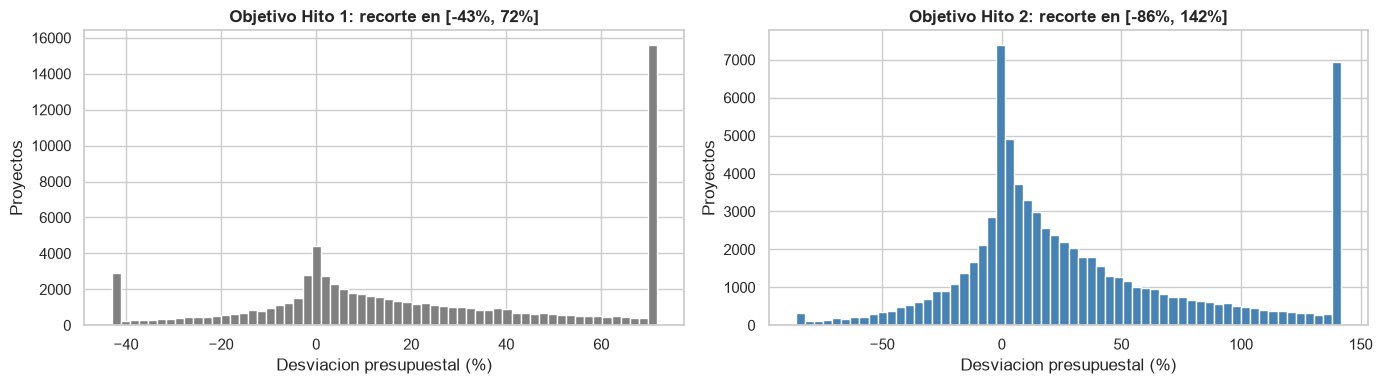

Estadisticas del nuevo objetivo (train): media 31.75 | mediana 16.1 | desv. estandar 51.76


In [ ]:
y_bruto = df_model['desviacion_pct']
idx_train, idx_test = X_train.index, X_test.index      # misma particion 80/20 de la seccion 5.6

q1_tr, q3_tr = y_bruto.loc[idx_train].quantile([0.25, 0.75])
iqr_tr = q3_tr - q1_tr
lim_inf, lim_sup = q1_tr - 1.5 * iqr_tr, q3_tr + 1.5 * iqr_tr

# Nueva variable objetivo para el modelado (los limites se aprenden SOLO de train)
y_tr = y_bruto.loc[idx_train].clip(lim_inf, lim_sup)
y_te = y_bruto.loc[idx_test].clip(lim_inf, lim_sup)

comparacion_cap = pd.DataFrame({
    'Hito 1 (df_valido completo)':  [lower_cap, upper_cap,
                                     (y_train != y_bruto.loc[idx_train]).mean() * 100],
    'Hito 2 (solo train de df_model)': [lim_inf, lim_sup,
                                     (y_tr != y_bruto.loc[idx_train]).mean() * 100],
}, index=['Limite inferior (%)', 'Limite superior (%)', '% de proyectos de train recortados']).round(2)
display(comparacion_cap)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(y_train, bins=60, color='gray')
axes[0].set_title('Objetivo Hito 1: recorte en [-43%, 72%]')
axes[1].hist(y_tr, bins=60, color='steelblue')
axes[1].set_title(f'Objetivo Hito 2: recorte en [{lim_inf:.0f}%, {lim_sup:.0f}%]')
for ax in axes:
    ax.set_xlabel('Desviacion presupuestal (%)'); ax.set_ylabel('Proyectos')
plt.tight_layout(); plt.show()

print('Estadisticas del nuevo objetivo (train): media', round(y_tr.mean(), 2),
      '| mediana', round(y_tr.median(), 2), '| desv. estandar', round(y_tr.std(), 2))

El histograma de la izquierda muestra la "pared" artificial en 71.69%: miles de proyectos con sobrecostos muy distintos quedaban con el mismo valor. Con los límites recalculados el recorte afecta a menos del 10% de los proyectos de entrenamiento y la distribución conserva la información de los sobrecostos altos, que son justamente los que interesa anticipar.

#### 6.1.2 ¿Por qué se trabaja con dos escenarios (B y C)?

El objetivo del proyecto es **preventivo** (sección 1.5): estimar el sobrecosto **antes de ejecutar la obra**, para priorizar la supervisión. Un modelo preventivo solo puede usar datos que **ya existan en el momento en que se hace la predicción**. Por eso la primera pregunta del modelado no es "¿qué algoritmo uso?", sino **"¿en qué momento se usará el modelo y qué información existe en ese momento?"**.

En el ciclo de inversión de Invierte.pe hay **dos momentos de decisión antes de construir**, y en cada uno se dispone de información distinta:

| | Momento 1: **declaración de viabilidad** | Momento 2: **aprobación del expediente técnico** |
|---|---|---|
| Fase de Invierte.pe | Formulación y Evaluación | Inicio de la Ejecución (Formato 8-A), antes de licitar |
| Qué se aprueba | La inversión, con su `MONTO_VIABLE` | El diseño detallado de la obra y su costo (`MONTO_ET_F8`) |
| Decisión que apoya el modelo | Priorizar qué obras requerirán seguimiento desde el inicio | Alertar qué obras revisar antes de licitar y construir |
| Escenario del modelo | **B — Viabilidad** | **C — Expediente técnico** (B + datos del expediente) |

- **Escenario B** responde: *¿qué tan bien se puede anticipar el sobrecosto en el momento más temprano posible?* Es el modelo preventivo puro.
- **Escenario C** responde: *¿cuánto mejora la predicción si se espera a tener el expediente técnico?* Sigue siendo preventivo, porque el expediente se aprueba **antes** de licitar y ejecutar.

Ambos escenarios usan **el mismo dataset, los mismos proyectos, la misma partición train/test y la misma variable objetivo**; lo único que cambia es el subconjunto de columnas disponible. Así, cualquier diferencia de desempeño entre B y C se debe solo a la información disponible en cada momento.

#### 6.1.3 Criterio de selección de variables para cada escenario

Las variables de cada escenario se eligieron aplicando **tres filtros en secuencia**:

1. **Filtro 1 — Influencia estadística (Hito 1, secciones 4.9 y 4.10).** Solo pasan las variables que mostraron relación con el sobrecosto: Spearman |r| ≥ 0.05 para numéricas y Kruskal-Wallis (p < 0.05) con η² ≥ 0.001 para categóricas. De aquí salen 33 variables candidatas (22 con pocos faltantes, 9 imputables, `FECHA_VIABILIDAD` y `MONTO_VIABLE`). Las 18 variables de fuga ya se habían excluido a priori.
2. **Filtro 2 — Disponibilidad temporal (nuevo en el Hito 2).** De las candidatas, solo se conservan las que **existen en el momento de uso del modelo**. Las que se conocen al declarar la viabilidad entran en B y en C; las del expediente técnico solo en C; las que se generan durante la ejecución no entran en ningún escenario. Una variable de ejecución puede pasar el Filtro 1 justamente porque **ya contiene parte del sobrecosto** (fuga de información): la estadística sola no basta.
3. **Filtro 3 — Calidad y cardinalidad.** Se descartan variables que, aunque estén disponibles, no permiten generalizar: texto libre o categorías con demasiados valores distintos.

La siguiente tabla aplica los tres filtros a cada una de las 33 variables candidatas:

In [ ]:
# (variable original, momento en que se conoce, decision B, decision C, motivo)
VIAB, ET, EJEC = 'Al declarar la viabilidad', 'Al aprobar el expediente tecnico', 'Durante / despues de la ejecucion'
criterio = [
    ('MONTO_VIABLE',       VIAB, 'Si', 'Si', 'Entra como monto_viable_log (tamano de la obra)'),
    ('FECHA_VIABILIDAD',   VIAB, 'Si', 'Si', 'Entra como anio_viabilidad'),
    ('FEC_INI_EJECUCION',  VIAB, 'Si', 'Si', 'Fecha PROGRAMADA; entra como plazo_dias'),
    ('FEC_FIN_EJECUCION',  VIAB, 'Si', 'Si', 'Fecha PROGRAMADA; entra como plazo_dias'),
    ('LATITUD',            VIAB, 'Si', 'Si', 'Ubicacion de la obra'),
    ('LONGITUD',           VIAB, 'Si', 'Si', 'Ubicacion de la obra'),
    ('NIVEL',              VIAB, 'Si', 'Si', 'Nivel de gobierno que ejecuta'),
    ('SECTOR',             VIAB, 'Si', 'Si', 'Sector responsable'),
    ('FUNCION',            VIAB, 'Si', 'Si', 'Funcion publica de la obra'),
    ('PROGRAMA',           VIAB, 'Si', 'Si', 'Clasificacion funcional'),
    ('SUBPROGRAMA',        VIAB, 'Si', 'Si', 'Clasificacion funcional'),
    ('DES_TIPOLOGIA',      VIAB, 'Si', 'Si', 'Tipo especifico de obra'),
    ('TIPO_INVERSION',     VIAB, 'Si', 'Si', 'PIP, IOARR, etc.'),
    ('MARCO',              VIAB, 'Si', 'Si', 'SNIP o Invierte.pe'),
    ('DEPARTAMENTO',       VIAB, 'Si', 'Si', 'Region de la obra'),
    ('DES_MODALIDAD',      VIAB, 'Si', 'Si', 'Modalidad de ejecucion prevista'),
    ('IND_IOARR_EMERG',    VIAB, 'Si', 'Si', 'Indicador de inversion de emergencia'),
    ('MONTO_ET_F8',        ET,   'No', 'Si', 'Existe recien con el expediente tecnico; en C tambien se usa como ratio_et_viable'),
    ('EXPEDIENTE_TECNICO', ET,   'No', 'Si', 'Indica si la obra cuenta con expediente tecnico'),
    ('MONTO_LAUDO',        EJEC, 'No', 'No', 'Fuga: monto de un arbitraje con el contratista'),
    ('CTRL_CONCURR',       EJEC, 'No', 'No', 'Fuga: control concurrente de Contraloria durante la obra'),
    ('PIM_ANIO_ACTUAL',    EJEC, 'No', 'No', 'Fuga: presupuesto modificado de 2026'),
    ('PIA_ANIO_ACTUAL',    EJEC, 'No', 'No', 'Fuga: presupuesto de 2026'),
    ('PMI_ANIO_1',         EJEC, 'No', 'No', 'Fuga: programacion de anios futuros'),
    ('PMI_ANIO_2',         EJEC, 'No', 'No', 'Fuga: programacion de anios futuros'),
    ('PMI_ANIO_4',         EJEC, 'No', 'No', 'Fuga: programacion de anios futuros'),
    ('REGISTRADO_PMI',     EJEC, 'No', 'No', 'Fuga: estado del proyecto a la fecha de descarga'),
    ('TIENE_F8',           EJEC, 'No', 'No', 'Fuga: estado del proyecto a la fecha de descarga'),
    ('TIENE_AVAN_FISICO',  EJEC, 'No', 'No', 'Fuga: indica que la obra ya avanza'),
    ('TIENE_F12B',         EJEC, 'No', 'No', 'Fuga: formato de seguimiento de la ejecucion'),
    ('ALTERNATIVA',        VIAB, 'No', 'No', 'Filtro 3: texto libre, casi un valor distinto por proyecto'),
    ('DISTRITO',           VIAB, 'No', 'No', 'Filtro 3: 1,738 categorias; se usa DEPARTAMENTO + LATITUD/LONGITUD'),
    ('PROVINCIA',          VIAB, 'No', 'No', 'Filtro 3: 197 categorias; se usa DEPARTAMENTO + LATITUD/LONGITUD'),
]
tabla_criterio = pd.DataFrame(criterio, columns=['Variable (Hito 1)', '¿Cuando se conoce? (Filtro 2)',
                                                 'Escenario B', 'Escenario C', 'Motivo'])

def _color_decision(v):
    return 'background-color: #d5f5e3' if v == 'Si' else 'background-color: #fadbd8' if v == 'No' else ''
display(tabla_criterio.style.map(_color_decision, subset=['Escenario B', 'Escenario C'])
        .hide(axis='index').set_caption('Tabla 6.1 — Aplicacion de los tres filtros a las 33 variables candidatas'))

print('Variables que pasan a B:', (tabla_criterio['Escenario B'] == 'Si').sum(),
      '| a C:', (tabla_criterio['Escenario C'] == 'Si').sum(),
      '| excluidas por fuga (Filtro 2):', tabla_criterio['Motivo'].str.startswith('Fuga').sum(),
      '| excluidas por calidad (Filtro 3):', tabla_criterio['Motivo'].str.startswith('Filtro 3').sum())

Variable (Hito 1),¿Cuando se conoce? (Filtro 2),Escenario B,Escenario C,Motivo
MONTO_VIABLE,Al declarar la viabilidad,Si,Si,Entra como monto_viable_log (tamano de la obra)
FECHA_VIABILIDAD,Al declarar la viabilidad,Si,Si,Entra como anio_viabilidad
FEC_INI_EJECUCION,Al declarar la viabilidad,Si,Si,Fecha PROGRAMADA; entra como plazo_dias
FEC_FIN_EJECUCION,Al declarar la viabilidad,Si,Si,Fecha PROGRAMADA; entra como plazo_dias
LATITUD,Al declarar la viabilidad,Si,Si,Ubicacion de la obra
LONGITUD,Al declarar la viabilidad,Si,Si,Ubicacion de la obra
NIVEL,Al declarar la viabilidad,Si,Si,Nivel de gobierno que ejecuta
SECTOR,Al declarar la viabilidad,Si,Si,Sector responsable
FUNCION,Al declarar la viabilidad,Si,Si,Funcion publica de la obra
PROGRAMA,Al declarar la viabilidad,Si,Si,Clasificacion funcional


Variables que pasan a B: 17 | a C: 19 | excluidas por fuga (Filtro 2): 11 | excluidas por calidad (Filtro 3): 3


*Nota:* B parte de 17 variables originales, pero `FEC_INI_EJECUCION` y `FEC_FIN_EJECUCION` se combinan en una sola (`plazo_dias`), así que el modelo B recibe **16 variables de entrada**. C agrega `MONTO_ET_F8`, `EXPEDIENTE_TECNICO` y la variable derivada `ratio_et_viable`: **19 variables de entrada**.

La siguiente celda respalda con datos dos de las decisiones de la tabla: por qué el expediente técnico merece un escenario propio y por qué el laudo y el control concurrente se tratan como fuga.

In [ ]:
et = pd.to_numeric(df_model['MONTO_ET_F8'], errors='coerce')
tiene_et = et > 0
igual_et = (df_model.loc[tiene_et, 'COSTO_ACTUALIZADO'] - et[tiene_et]).abs() < 1
desv_et = (et - df_model['MONTO_VIABLE']) / df_model['MONTO_VIABLE'] * 100
r_et, _ = stats.spearmanr(desv_et[tiene_et], y_bruto[tiene_et])

print('EVIDENCIA 1 — Expediente tecnico (MONTO_ET_F8): justifica el escenario C')
print(f'  Proyectos con expediente tecnico registrado: {tiene_et.mean()*100:.1f}%')
print(f'  ...cuyo COSTO_ACTUALIZADO es IDENTICO al monto del expediente: {igual_et.mean()*100:.1f}%')
print(f'  Spearman entre la desviacion del expediente (ET vs viable) y la desviacion final: {r_et:.3f}')
print('  -> Una gran parte del "sobrecosto" se origina al elaborar el expediente tecnico.\n')

print('EVIDENCIA 2 — Variables que se generan durante la ejecucion (Filtro 2)')
for c in ['MONTO_LAUDO', 'CTRL_CONCURR']:
    v = pd.to_numeric(df_model[c], errors='coerce').fillna(0)
    print(f'  {c}: {(v > 0).mean()*100:.1f}% de proyectos con monto > 0 | '
          f'desviacion mediana con monto > 0: {y_bruto[v > 0].median():.1f}% vs sin monto: {y_bruto[v == 0].median():.1f}%')
print('  -> Se asocian con mas sobrecosto porque SON parte del problema ya ocurrido, no porque lo anticipen.')

EVIDENCIA 1 — Expediente tecnico (MONTO_ET_F8): justifica el escenario C
  Proyectos con expediente tecnico registrado: 96.4%
  ...cuyo COSTO_ACTUALIZADO es IDENTICO al monto del expediente: 31.7%
  Spearman entre la desviacion del expediente (ET vs viable) y la desviacion final: 0.569
  -> Una gran parte del "sobrecosto" se origina al elaborar el expediente tecnico.

EVIDENCIA 2 — Variables que se generan durante la ejecucion (Filtro 2)
  MONTO_LAUDO: 1.5% de proyectos con monto > 0 | desviacion mediana con monto > 0: 52.3% vs sin monto: 15.7%
  CTRL_CONCURR: 11.8% de proyectos con monto > 0 | desviacion mediana con monto > 0: 31.2% vs sin monto: 15.2%
  -> Se asocian con mas sobrecosto porque SON parte del problema ya ocurrido, no porque lo anticipen.


Para el escenario C se crea una variable nueva: `ratio_et_viable = log(MONTO_ET_F8 / MONTO_VIABLE)`, que mide cuánto cambió el costo al pasar del perfil al expediente técnico (0 = sin cambio).

In [ ]:
# Variable nueva para el escenario C
df_model['ratio_et_viable'] = np.log(et.where(et > 0) / df_model['MONTO_VIABLE'])

num_B = ['monto_viable_log', 'plazo_dias', 'anio_viabilidad', 'LATITUD', 'LONGITUD']
cat_B = ['NIVEL', 'SECTOR', 'FUNCION', 'DES_MODALIDAD', 'TIPO_INVERSION', 'DEPARTAMENTO',
         'MARCO', 'PROGRAMA', 'SUBPROGRAMA', 'DES_TIPOLOGIA', 'IND_IOARR_EMERG']

ESCENARIOS = {
    'B - Viabilidad':         {'num': num_B, 'cat': cat_B},
    'C - Expediente tecnico': {'num': num_B + ['MONTO_ET_F8', 'ratio_et_viable'],
                               'cat': cat_B + ['EXPEDIENTE_TECNICO']},
}

def columnas(esc):
    return ESCENARIOS[esc]['num'] + ESCENARIOS[esc]['cat']

def crear_preprocesador(esc, denso=False):
    # Mismo esquema de la seccion 5.7 (mediana + escalado / moda + One-Hot con min_frequency=50).
    # Salida dispersa (sparse) para ahorrar memoria; HistGradientBoosting requiere matriz densa.
    e = ESCENARIOS[esc]
    return ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', StandardScaler())]), e['num']),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('encoding', OneHotEncoder(handle_unknown='ignore', min_frequency=50,
                                                     sparse_output=not denso))]), e['cat']),
    ])

# Matrices de entrada (columnas originales; el preprocesamiento va DENTRO de cada pipeline)
todas = sorted(set(sum([columnas(e) for e in ESCENARIOS], [])))
cats_todas = set(sum([ESCENARIOS[e]['cat'] for e in ESCENARIOS], []))
X_full = df_model[todas].copy()
for c in X_full.columns:
    if c not in cats_todas:
        X_full[c] = pd.to_numeric(X_full[c], errors='coerce')
X_tr, X_te = X_full.loc[idx_train], X_full.loc[idx_test]

resumen_esc = []
for esc in ESCENARIOS:
    n_cols = crear_preprocesador(esc).fit(X_tr[columnas(esc)]).transform(X_tr[columnas(esc)].head(5)).shape[1]
    resumen_esc.append({'Escenario': esc, 'Variables de entrada': len(columnas(esc)),
                        'Columnas tras One-Hot': n_cols})
print('Train:', X_tr.shape, '| Test:', X_te.shape)
pd.DataFrame(resumen_esc)

Train: (75575, 19) | Test: (18894, 19)


,Escenario,Variables de entrada,Columnas tras One-Hot
0,B - Viabilidad,16,280
1,C - Expediente tecnico,19,284


### 6.2 Modelos seleccionados y justificación

Se comparan **siete modelos más un baseline**, organizados como una escalera de complejidad: cada modelo debe superar al anterior para justificar su costo adicional. Además de los modelos de regresión y de los árboles, se incorporan **dos técnicas de ensamble (Ensemble Learning): Bagging y Stacking**.

| Modelo | Tipo | Por qué se incluye |
|---|---|---|
| **Baseline (media)** — `DummyRegressor` | Referencia | Predice siempre el promedio de train. Todo modelo debe superarlo para justificarse. |
| **Regresión Lineal** | Lineal (OLS) | Modelo base e interpretable: cada coeficiente es el efecto parcial de una variable. |
| **Ridge (L2)** | Lineal regularizado | Tras el One-Hot hay ~280 columnas *dummy* correlacionadas (p. ej. SECTOR y NIVEL); la penalización L2 estabiliza los coeficientes ante la multicolinealidad. |
| **Árbol de Decisión** | No lineal | Reglas si-entonces fáciles de explicar; captura interacciones (p. ej. función × región) sin suponer linealidad. |
| **Bagging** — `BaggingRegressor` | Ensamble en paralelo | Entrena muchos árboles sobre muestras *bootstrap* distintas y **promedia** sus predicciones. Según la clase, reduce la **varianza** y el sobreajuste de un modelo inestable como el árbol individual. |
| **Random Forest** | Ensamble en paralelo | Es Bagging de árboles más un sorteo aleatorio de variables en cada división, lo que hace a los árboles aún más diferentes entre sí (Breiman, 2001). |
| **Gradient Boosting** — `HistGradientBoostingRegressor` | Ensamble secuencial (boosting) | Árboles entrenados uno tras otro, donde cada uno corrige los errores del anterior. Según la clase, reduce el **sesgo** y es muy potente en datos tabulares (Friedman, 2001). |
| **Stacking** — `StackingRegressor` | Ensamble combinado | Combina modelos **distintos** (Ridge, Árbol y Gradient Boosting) y entrena un **meta-modelo** (regresión lineal) que aprende cuánto confiar en cada uno. Según la clase, combina fortalezas y suele mejorar el desempeño final. |

**¿Por qué no SVM ni KNN?** Trabajan con distancias entre puntos y su costo crece rápidamente con el número de filas (75 mil proyectos); además, las distancias pierden sentido con cientos de columnas *dummy*. **¿Por qué no Regresión Logística?** Es un modelo de clasificación; aquí se predice un valor continuo.

**Métricas de evaluación** (en puntos porcentuales de desviación, salvo R²):
- **RMSE**: castiga más los errores grandes (equivocarse mucho en una obra con sobrecosto alto). Es la métrica que se optimiza en el ajuste de hiperparámetros.
- **MAE**: error promedio absoluto, fácil de comunicar ("el modelo se equivoca en promedio X puntos porcentuales").
- **R²** y **R² ajustado**: proporción de la variabilidad del sobrecosto que explica el modelo.
- **No se usa MAPE**: la variable objetivo toma valores iguales o cercanos a 0, lo que hace que el error porcentual se dispare o quede indefinido.

#### 6.2.1 Criterios para elegir el mejor modelo (definidos antes de ver los resultados)

| # | Criterio | Cómo se mide | Por qué importa |
|---|---|---|---|
| 1 | **Precisión** (principal) | Menor **RMSE en prueba**; MAE y R² como apoyo | Es el desempeño honesto sobre obras nunca vistas |
| 2 | **Generalización** | Brecha de sobreajuste = R² train − R² prueba; y diferencia entre R² de validación cruzada y de prueba | Un modelo que memoriza no es confiable con obras nuevas |
| 3 | **Costo computacional** | Tiempo de entrenamiento y de predicción | El modelo debe poder reentrenarse cuando el MEF actualice los datos |
| 4 | **Interpretabilidad** | Cualitativo | Una entidad pública necesita explicar por qué prioriza una obra |

**Regla de decisión:** se ordena por RMSE en prueba. Si varios modelos quedan a menos de **1% del mejor RMSE** (empate práctico), entre ellos se elige el de **menor brecha de sobreajuste** y, si persiste el empate, el de **menor tiempo de entrenamiento** (principio de parsimonia).

In [ ]:
def crear_modelos(esc, params=None):
    # Hiperparametros iniciales razonables; 'params' (de la seccion 6.4) reemplaza los ajustados.
    params = params or {}
    m = {
        'Baseline (media)':  DummyRegressor(strategy='mean'),
        'Regresion Lineal':  LinearRegression(),
        'Ridge':             Ridge(alpha=1.0),
        'Arbol de Decision': DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SEMILLA),
        'Bagging':           BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=10, random_state=SEMILLA),
                                              n_estimators=30, max_samples=0.5, n_jobs=-1, random_state=SEMILLA),
        'Random Forest':     RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features='sqrt',
                                                   n_jobs=-1, random_state=SEMILLA),
        'Gradient Boosting': HistGradientBoostingRegressor(random_state=SEMILLA),
    }
    for nombre, p in params.items():
        if nombre in m:
            m[nombre] = clone(m[nombre]).set_params(**p)
    # Stacking: combina Ridge + Arbol + Gradient Boosting (con sus hiperparametros vigentes);
    # cada modelo base lleva su propio preprocesamiento y un meta-modelo lineal aprende a combinarlos.
    bases = [(clave, crear_pipeline(esc, m[nombre])) for clave, nombre in
             [('ridge', 'Ridge'), ('arbol', 'Arbol de Decision'), ('gboost', 'Gradient Boosting')]]
    m['Stacking'] = StackingRegressor(estimators=bases, final_estimator=LinearRegression(), cv=3)
    return m

def crear_pipeline(esc, modelo):
    if isinstance(modelo, StackingRegressor):          # ya incluye el preprocesamiento de cada base
        return clone(modelo)
    denso = isinstance(modelo, HistGradientBoostingRegressor)   # HGB no acepta matrices dispersas
    return Pipeline([('prep', crear_preprocesador(esc, denso=denso)), ('modelo', clone(modelo))])

orden_modelos = list(crear_modelos('B - Viabilidad').keys())
print('Modelos a comparar:', orden_modelos)

Modelos a comparar: ['Baseline (media)', 'Regresion Lineal', 'Ridge', 'Arbol de Decision', 'Bagging', 'Random Forest', 'Gradient Boosting', 'Stacking']


### 6.3 Comparación de modelos con validación cruzada (5 folds)

Cada modelo se evalúa con `KFold` de 5 pliegues sobre el conjunto de entrenamiento, en los dos escenarios. El preprocesamiento va **dentro** del pipeline, de modo que en cada pliegue la imputación, el escalado y el One-Hot se aprenden solo con los datos de entrenamiento de ese pliegue (sin fuga entre pliegues). Se registran también el **R² en entrenamiento** (para detectar sobreajuste) y el **tiempo de entrenamiento** de cada modelo.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

filas_cv = []
for esc in ESCENARIOS:
    for nombre, modelo in crear_modelos(esc).items():
        t0 = time.time()
        res = cross_validate(crear_pipeline(esc, modelo), X_tr[columnas(esc)], y_tr,
                             cv=cv, scoring=scoring, return_train_score=True)
        filas_cv.append({'Escenario': esc, 'Modelo': nombre,
                         'MAE_cv': -res['test_MAE'].mean(), 'RMSE_cv': -res['test_RMSE'].mean(),
                         'R2_cv': res['test_R2'].mean(), 'R2_cv_std': res['test_R2'].std(),
                         'R2_train': res['train_R2'].mean(),
                         'Tiempo fit por fold (s)': res['fit_time'].mean()})
        print(f'{esc:24s} | {nombre:18s} | R2_cv = {res["test_R2"].mean():.3f} | {time.time()-t0:5.0f} s')

df_cv = pd.DataFrame(filas_cv).round(3)

B - Viabilidad           | Baseline (media)   | R2_cv = -0.000 |     9 s


B - Viabilidad           | Regresion Lineal   | R2_cv = 0.102 |    16 s


B - Viabilidad           | Ridge              | R2_cv = 0.102 |     9 s


B - Viabilidad           | Arbol de Decision  | R2_cv = 0.125 |    15 s


B - Viabilidad           | Bagging            | R2_cv = 0.186 |   136 s


B - Viabilidad           | Random Forest      | R2_cv = 0.181 |    57 s


... (6 outputs left out)

C - Expediente tecnico   | Bagging            | R2_cv = 0.645 |   122 s


C - Expediente tecnico   | Random Forest      | R2_cv = 0.565 |    60 s


C - Expediente tecnico   | Gradient Boosting  | R2_cv = 0.652 |    38 s


C - Expediente tecnico   | Stacking           | R2_cv = 0.652 |   159 s



RMSE_cv por modelo y escenario (validacion cruzada, 5 folds):


Escenario,B - Viabilidad,C - Expediente tecnico
Modelo,,
Baseline (media),51.762,51.762
Regresion Lineal,49.053,43.703
Ridge,49.046,43.698
Arbol de Decision,48.419,32.233
Bagging,46.702,30.826
Random Forest,46.847,34.120
Gradient Boosting,46.568,30.527
Stacking,46.509,30.517



MAE_cv por modelo y escenario (validacion cruzada, 5 folds):


Escenario,B - Viabilidad,C - Expediente tecnico
Modelo,,
Baseline (media),40.835,40.835
Regresion Lineal,38.104,33.590
Ridge,38.102,33.593
Arbol de Decision,37.059,19.680
Bagging,35.630,18.648
Random Forest,36.076,24.040
Gradient Boosting,35.619,18.629
Stacking,35.491,18.558



R2_cv por modelo y escenario (validacion cruzada, 5 folds):


Escenario,B - Viabilidad,C - Expediente tecnico
Modelo,,
Baseline (media),-0.000,-0.000
Regresion Lineal,0.102,0.287
Ridge,0.102,0.287
Arbol de Decision,0.125,0.612
Bagging,0.186,0.645
Random Forest,0.181,0.565
Gradient Boosting,0.191,0.652
Stacking,0.193,0.652


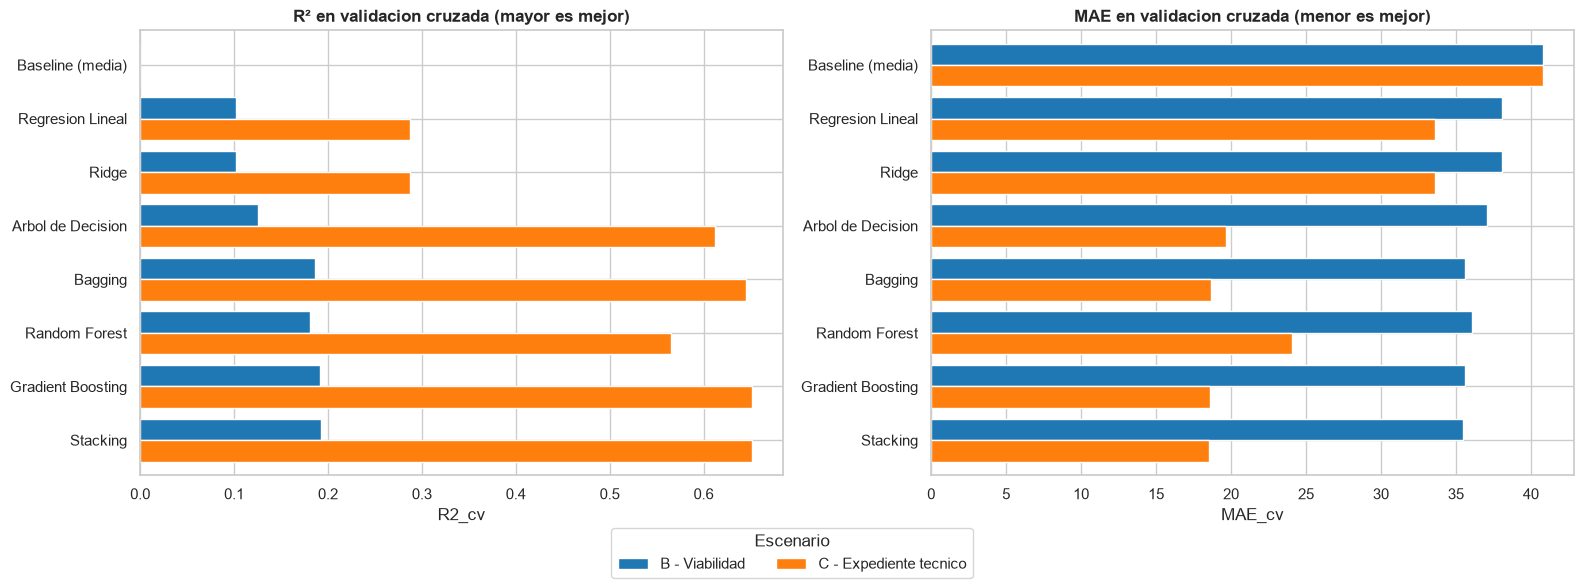

,Escenario,Modelo,R2_train,R2_cv,Tiempo fit por fold (s),Brecha (train - cv)
1,B - Viabilidad,Regresion Lineal,0.109,0.102,2.602,0.007
2,B - Viabilidad,Ridge,0.109,0.102,1.409,0.007
3,B - Viabilidad,Arbol de Decision,0.180,0.125,2.449,0.055
4,B - Viabilidad,Bagging,0.355,0.186,25.733,0.169
5,B - Viabilidad,Random Forest,0.295,0.181,10.322,0.114
6,B - Viabilidad,Gradient Boosting,0.233,0.191,7.055,0.042
7,B - Viabilidad,Stacking,0.239,0.193,31.724,0.046
9,C - Expediente tecnico,Regresion Lineal,0.294,0.287,1.816,0.007
10,C - Expediente tecnico,Ridge,0.294,0.287,1.332,0.007
11,C - Expediente tecnico,Arbol de Decision,0.644,0.612,2.727,0.032


In [ ]:
for met in ['RMSE_cv', 'MAE_cv', 'R2_cv']:
    print(f'\n{met} por modelo y escenario (validacion cruzada, 5 folds):')
    display(df_cv.pivot(index='Modelo', columns='Escenario', values=met).loc[orden_modelos])

colores_esc = {'B - Viabilidad': '#1f77b4', 'C - Expediente tecnico': '#ff7f0e'}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, met, titulo in zip(axes, ['R2_cv', 'MAE_cv'],
                           ['R² en validacion cruzada (mayor es mejor)', 'MAE en validacion cruzada (menor es mejor)']):
    piv = df_cv.pivot(index='Modelo', columns='Escenario', values=met).loc[orden_modelos]
    piv.plot.barh(ax=ax, color=[colores_esc[c] for c in piv.columns], width=0.8)
    ax.set_title(titulo); ax.set_xlabel(met); ax.set_ylabel('')
    ax.invert_yaxis()
h, l = axes[0].get_legend_handles_labels()
for ax in axes: ax.get_legend().remove()
fig.legend(h, l, title='Escenario', loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

# Sobreajuste: diferencia entre R2 de entrenamiento y R2 de validacion
sobreajuste = df_cv[df_cv['Modelo'] != 'Baseline (media)'][['Escenario', 'Modelo', 'R2_train', 'R2_cv', 'Tiempo fit por fold (s)']].copy()
sobreajuste['Brecha (train - cv)'] = (sobreajuste['R2_train'] - sobreajuste['R2_cv']).round(3)
sobreajuste

**Lectura de la validación cruzada:**

- **Todos los modelos superan al baseline** (R² ≈ 0) en ambos escenarios.
- **Los modelos lineales quedan claramente por debajo de los de árboles**: el sobrecosto depende de combinaciones de factores (función × región × tamaño × modalidad) que una relación lineal no captura. Ridge y la Lineal dan casi el mismo resultado; con 75 mil filas la regularización aporta poco.
- **Los cuatro ensambles (Bagging, Random Forest, Gradient Boosting y Stacking) quedan en la parte alta**, con diferencias pequeñas entre sí: R² entre 0.18 y 0.19 en B, y entre 0.57 y 0.65 en C.
- **Bagging cumple lo que dice la teoría**: frente al árbol individual reduce el error (R² 0.125 → 0.186 en B y 0.612 → 0.645 en C) porque promedia árboles entrenados con muestras distintas y así reduce la varianza. Pero tiene la **mayor brecha entre train y validación** (0.17 en B): sus árboles son profundos y memorizan.
- **Stacking empata con Gradient Boosting** (0.193 vs 0.191 en B; 0.652 en ambos en C). En 6.7 se verá por qué: el meta-modelo termina confiando casi solo en Gradient Boosting.
- **Random Forest rinde menos en C** (0.565): con `max_features='sqrt'` cada división ve solo ~5% de las columnas y muchas veces no "ve" juntas las dos variables clave (monto viable y monto del expediente). Se revisa en 6.4.
- **El salto entre escenarios es mucho mayor que el salto entre modelos**: agregar el expediente técnico (B → C) mejora el R² mucho más que cambiar de algoritmo.

### 6.4 Ajuste de hiperparámetros

- **Ridge, Árbol de Decisión, Bagging y Random Forest**: `GridSearchCV` (grilla pequeña de combinaciones).
- **Gradient Boosting**: `RandomizedSearchCV`. Tiene muchos hiperparámetros; probar combinaciones al azar encuentra buenas configuraciones a una fracción del costo de una grilla completa (Bergstra & Bengio, 2012).
- **Stacking** no se ajusta por separado: en la evaluación final se construye con los modelos base (Ridge, Árbol y Gradient Boosting) **ya ajustados**.

Como en clase, la búsqueda va **dentro** de la validación cruzada (3 folds) y solo usa el conjunto de entrenamiento. Se optimiza el RMSE (`neg_root_mean_squared_error`).

**Para acelerar la búsqueda se usa una muestra aleatoria del 40% de train** (~30 mil proyectos): cada combinación se entrena 3 veces, y con todo train la búsqueda tomaría mucho más tiempo. Es una práctica estándar: los hiperparámetros que funcionan bien en una muestra grande y representativa funcionan bien en el total. El modelo final (6.5) sí se entrena con todo el conjunto de entrenamiento. Para que la comparación sea justa, la configuración inicial de cada modelo se evalúa sobre la **misma muestra y los mismos folds**.

In [ ]:
espacios = {
    'Ridge': ('grid', {'modelo__alpha': [0.1, 1, 10, 100, 1000]}),
    'Arbol de Decision': ('grid', {'modelo__max_depth': [6, 10, 15, 20],
                                   'modelo__min_samples_leaf': [20, 50, 200]}),
    'Bagging': ('grid', {'modelo__max_samples': [0.5, 1.0],
                         'modelo__estimator__min_samples_leaf': [5, 20]}),
    'Random Forest': ('grid', {'modelo__max_features': ['sqrt', 0.2],
                               'modelo__min_samples_leaf': [5, 10]}),
    'Gradient Boosting': ('random', {'modelo__learning_rate': [0.03, 0.05, 0.1],
                                     'modelo__max_iter': [300, 600],
                                     'modelo__max_leaf_nodes': [31, 63, 127],
                                     'modelo__min_samples_leaf': [20, 50, 100],
                                     'modelo__l2_regularization': [0.0, 1.0, 10.0]}),
}
N_ITER_HGB = 8
cv3 = KFold(n_splits=3, shuffle=True, random_state=SEMILLA)

# Muestra del 40% de train para la busqueda
idx_busq = X_tr.sample(frac=0.4, random_state=SEMILLA).index
X_busq, y_busq = X_tr.loc[idx_busq], y_tr.loc[idx_busq]
print('Muestra para la busqueda de hiperparametros:', X_busq.shape)

# True: ejecuta la busqueda completa (~15 min en Colab).
# False: usa directamente los hiperparametros ya encontrados en nuestra corrida (mismos datos y semilla).
AJUSTAR_HIPERPARAMETROS = True
PARAMS_ENCONTRADOS = {
    ('B - Viabilidad', 'Ridge'): ({'alpha': 10}, 49.28, 49.262),
    ('B - Viabilidad', 'Arbol de Decision'): ({'max_depth': 10, 'min_samples_leaf': 200}, 49.654, 49.246),
    ('B - Viabilidad', 'Bagging'): ({'estimator__min_samples_leaf': 5, 'max_samples': 1.0}, 47.615, 47.592),
    ('B - Viabilidad', 'Random Forest'): ({'max_features': 0.2, 'min_samples_leaf': 5}, 47.531, 46.93),
    ('B - Viabilidad', 'Gradient Boosting'): ({'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 10.0}, 47.103, 46.894),
    ('C - Expediente tecnico', 'Ridge'): ({'alpha': 10}, 44.167, 44.154),
    ('C - Expediente tecnico', 'Arbol de Decision'): ({'max_depth': 10, 'min_samples_leaf': 50}, 32.654, 32.454),
    ('C - Expediente tecnico', 'Bagging'): ({'estimator__min_samples_leaf': 5, 'max_samples': 1.0}, 31.25, 31.223),
    ('C - Expediente tecnico', 'Random Forest'): ({'max_features': 0.2, 'min_samples_leaf': 5}, 34.878, 31.201),
    ('C - Expediente tecnico', 'Gradient Boosting'): ({'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 10.0}, 30.86, 30.791),
}

mejores_params, filas_tuning = {'B - Viabilidad': {}, 'C - Expediente tecnico': {}}, []
for esc in ESCENARIOS:
    Xb = X_busq[columnas(esc)]
    modelos_base = crear_modelos(esc)
    for nombre, (tipo, grilla) in espacios.items():
        if not AJUSTAR_HIPERPARAMETROS:
            params, rmse_ini, rmse_aj = PARAMS_ENCONTRADOS[(esc, nombre)]
            mejores_params[esc][nombre] = params
            filas_tuning.append({'Escenario': esc, 'Modelo': nombre, 'RMSE config. inicial': rmse_ini,
                                 'RMSE ajustado': rmse_aj, 'Mejores hiperparametros': params, 'Tiempo (s)': 0})
            continue
        t0 = time.time()
        pipe = crear_pipeline(esc, modelos_base[nombre])
        # configuracion inicial evaluada en la misma muestra y los mismos folds
        rmse_ini = -cross_validate(pipe, Xb, y_busq, cv=cv3,
                                   scoring='neg_root_mean_squared_error')['test_score'].mean()
        if tipo == 'grid':
            busq = GridSearchCV(pipe, grilla, cv=cv3, scoring='neg_root_mean_squared_error')
        else:
            busq = RandomizedSearchCV(pipe, grilla, n_iter=N_ITER_HGB, cv=cv3, random_state=SEMILLA,
                                      scoring='neg_root_mean_squared_error')
        busq.fit(Xb, y_busq)
        mejores_params[esc][nombre] = {k.replace('modelo__', ''): v for k, v in busq.best_params_.items()}
        filas_tuning.append({'Escenario': esc, 'Modelo': nombre,
                             'RMSE config. inicial': rmse_ini, 'RMSE ajustado': -busq.best_score_,
                             'Mejores hiperparametros': mejores_params[esc][nombre],
                             'Tiempo (s)': round(time.time() - t0)})
        print(f'{esc:24s} | {nombre:18s} | RMSE {rmse_ini:.2f} -> {-busq.best_score_:.2f} | {time.time()-t0:5.0f} s')

df_tuning = pd.DataFrame(filas_tuning).round(3)
pd.set_option('display.max_colwidth', None)
df_tuning

Muestra para la busqueda de hiperparametros: (30230, 19)


B - Viabilidad           | Ridge              | RMSE 49.28 -> 49.26 |     8 s


B - Viabilidad           | Arbol de Decision  | RMSE 49.65 -> 49.25 |    24 s


B - Viabilidad           | Bagging            | RMSE 47.62 -> 47.59 |    78 s


B - Viabilidad           | Random Forest      | RMSE 47.53 -> 46.93 |    50 s


B - Viabilidad           | Gradient Boosting  | RMSE 47.10 -> 46.89 |   104 s


... (2 outputs left out)

C - Expediente tecnico   | Bagging            | RMSE 31.25 -> 31.22 |    96 s


C - Expediente tecnico   | Random Forest      | RMSE 34.88 -> 31.20 |    59 s


C - Expediente tecnico   | Gradient Boosting  | RMSE 30.86 -> 30.79 |   104 s


,Escenario,Modelo,RMSE config. inicial,RMSE ajustado,Mejores hiperparametros,Tiempo (s)
0,B - Viabilidad,Ridge,49.280,49.262,{'alpha': 10},8
1,B - Viabilidad,Arbol de Decision,49.654,49.246,"{'max_depth': 10, 'min_samples_leaf': 200}",24
2,B - Viabilidad,Bagging,47.615,47.592,"{'estimator__min_samples_leaf': 5, 'max_samples': 1.0}",78
3,B - Viabilidad,Random Forest,47.531,46.930,"{'max_features': 0.2, 'min_samples_leaf': 5}",50
4,B - Viabilidad,Gradient Boosting,47.103,46.894,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 10.0}",104
5,C - Expediente tecnico,Ridge,44.167,44.154,{'alpha': 10},9
6,C - Expediente tecnico,Arbol de Decision,32.654,32.454,"{'max_depth': 10, 'min_samples_leaf': 50}",31
7,C - Expediente tecnico,Bagging,31.250,31.223,"{'estimator__min_samples_leaf': 5, 'max_samples': 1.0}",96
8,C - Expediente tecnico,Random Forest,34.878,31.201,"{'max_features': 0.2, 'min_samples_leaf': 5}",59
9,C - Expediente tecnico,Gradient Boosting,30.860,30.791,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 10.0}",104


**Lectura del ajuste de hiperparámetros:**
- En **Ridge, Árbol, Bagging y Gradient Boosting** la mejora es pequeña (menos de 0.5 puntos de RMSE): los valores iniciales ya eran razonables y el límite está en la información disponible, no en la configuración del modelo.
- La mejora más grande ocurre en **Random Forest del escenario C** (RMSE de 34.9 a 31.2): con `max_features=0.2` cada división evalúa más columnas y el bosque puede combinar el monto viable con el monto del expediente. Esto confirma la explicación de 6.3.
- **Bagging** prefiere árboles más profundos (`min_samples_leaf=5`) con muestras del 100% de los datos.
- **Gradient Boosting** mejora con una tasa de aprendizaje más baja (0.05), árboles algo más grandes (63 hojas) y regularización L2: aprende más despacio, pero generaliza mejor.

### 6.5 Evaluación final en prueba, tiempos de ejecución y elección del mejor modelo

Cada modelo se reentrena con **todo** el conjunto de entrenamiento (con los hiperparámetros ajustados en 6.4) y se evalúa una única vez sobre el conjunto de prueba (18,894 proyectos que no se usaron en ninguna decisión anterior). Para cada modelo se mide además el **tiempo de entrenamiento** (ajuste con los 75,575 proyectos de train) y el **tiempo de predicción** (los 18,894 proyectos de prueba).

In [ ]:
def r2_ajustado(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

pipes_finales, filas_test, preds_test = {}, [], {}
for esc in ESCENARIOS:
    for nombre, modelo in crear_modelos(esc, mejores_params[esc]).items():
        pipe = crear_pipeline(esc, modelo)
        t0 = time.time()
        pipe.fit(X_tr[columnas(esc)], y_tr)
        t_fit = time.time() - t0
        t0 = time.time()
        pred = pipe.predict(X_te[columnas(esc)])
        t_pred = time.time() - t0
        pred_tr = pipe.predict(X_tr[columnas(esc)])
        pipes_finales[(esc, nombre)] = pipe
        preds_test[(esc, nombre)] = pred
        p = crear_preprocesador(esc).fit(X_tr[columnas(esc)]).transform(X_te[columnas(esc)].head(2)).shape[1]
        r2 = r2_score(y_te, pred)
        filas_test.append({'Escenario': esc, 'Modelo': nombre,
                           'MAE_test': mean_absolute_error(y_te, pred),
                           'RMSE_test': mean_squared_error(y_te, pred) ** 0.5,
                           'R2_test': r2, 'R2_ajustado_test': r2_ajustado(r2, len(y_te), p),
                           'R2_train': r2_score(y_tr, pred_tr),
                           'Tiempo entrenamiento (s)': t_fit, 'Tiempo prediccion (s)': t_pred})
        print(f'{esc:24s} | {nombre:18s} | R2_test = {r2:.3f} | entrenamiento {t_fit:6.1f} s | prediccion {t_pred:5.2f} s')

df_test = pd.DataFrame(filas_test)
df_test['Brecha sobreajuste'] = df_test['R2_train'] - df_test['R2_test']
df_test = df_test.round(3)

B - Viabilidad           | Baseline (media)   | R2_test = -0.000 | entrenamiento    1.2 s | prediccion  0.11 s


B - Viabilidad           | Regresion Lineal   | R2_test = 0.107 | entrenamiento    2.1 s | prediccion  0.11 s


B - Viabilidad           | Ridge              | R2_test = 0.107 | entrenamiento    1.3 s | prediccion  0.09 s


B - Viabilidad           | Arbol de Decision  | R2_test = 0.132 | entrenamiento    1.9 s | prediccion  0.09 s


B - Viabilidad           | Bagging            | R2_test = 0.205 | entrenamiento   52.6 s | prediccion  0.38 s


B - Viabilidad           | Random Forest      | R2_test = 0.230 | entrenamiento   37.5 s | prediccion  0.21 s


... (6 outputs left out)

C - Expediente tecnico   | Bagging            | R2_test = 0.660 | entrenamiento   71.1 s | prediccion  0.47 s


C - Expediente tecnico   | Random Forest      | R2_test = 0.670 | entrenamiento   40.4 s | prediccion  0.21 s


C - Expediente tecnico   | Gradient Boosting  | R2_test = 0.671 | entrenamiento   26.1 s | prediccion  0.55 s


C - Expediente tecnico   | Stacking           | R2_test = 0.671 | entrenamiento   95.1 s | prediccion  0.73 s


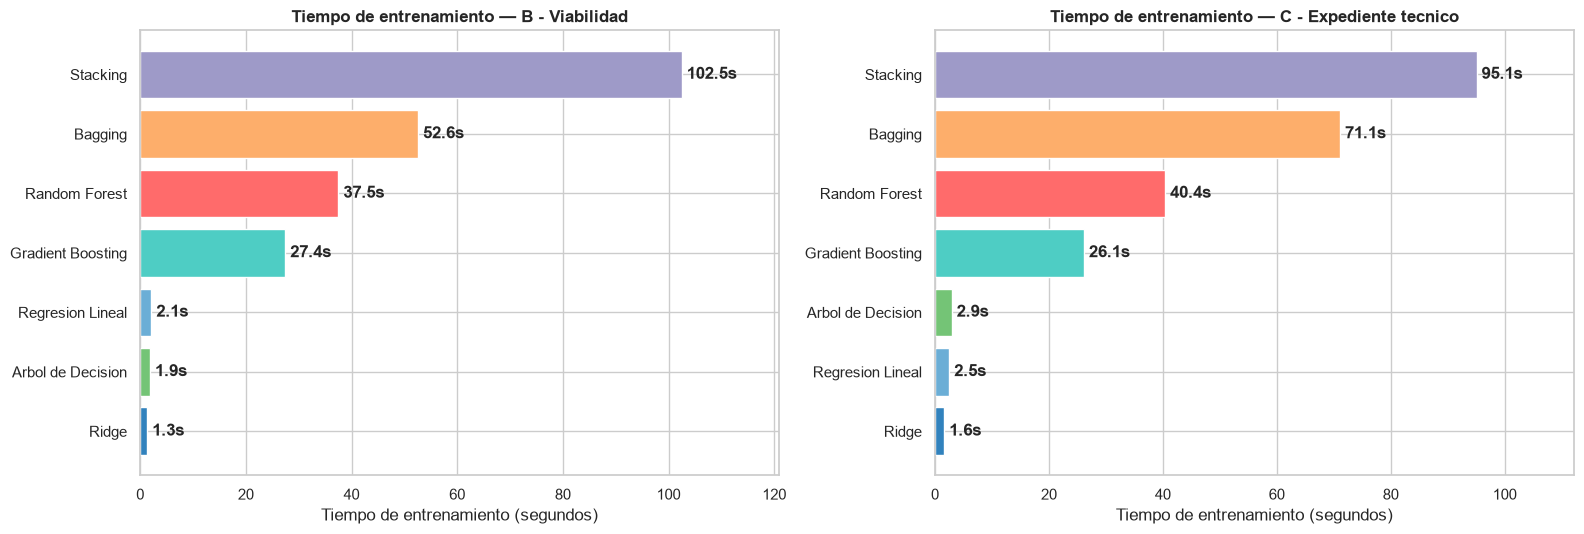

Tiempo entrenamiento (s)                         \
Escenario                   B - Viabilidad C - Expediente tecnico   
Modelo                                                              
Baseline (media)                     1.152                  1.104   
Regresion Lineal                     2.097                  2.483   
Ridge                                1.329                  1.623   
Arbol de Decision                    1.865                  2.919   
Bagging                             52.577                 71.074   
Random Forest                       37.501                 40.383   
Gradient Boosting                   27.438                 26.131   
Stacking                           102.492                 95.051   

                  Tiempo prediccion (s)                         
Escenario                B - Viabilidad C - Expediente tecnico  
Modelo                                                          
Baseline (media)                  0.113                  0.099  
Regresion Lineal                  0.107                  0.110  
Ridge                             0.091                  0.104  
Arbol de Decision                 0.086                  0.102  
Bagging                           0.377                  0.475  
Random Forest                     0.206                  0.212  
Gradient Boosting                 0.492                  0.548  
Stacking                          0.775                  0.735

In [ ]:
# Tiempos de ejecucion de cada modelo (entrenamiento con todo train)
paleta_modelos = dict(zip(orden_modelos, ['#9aa5a8', '#6baed6', '#3182bd', '#74c476', '#fdae6b',
                                          '#ff6b6b', '#4ecdc4', '#9e9ac8']))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, esc in zip(axes, ESCENARIOS):
    t = (df_test[(df_test['Escenario'] == esc) & (df_test['Modelo'] != 'Baseline (media)')]
         .sort_values('Tiempo entrenamiento (s)'))
    barras = ax.barh(t['Modelo'], t['Tiempo entrenamiento (s)'],
                     color=[paleta_modelos[m] for m in t['Modelo']])
    for b, v in zip(barras, t['Tiempo entrenamiento (s)']):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f' {v:.1f}s', va='center', fontweight='bold')
    ax.set_title(f'Tiempo de entrenamiento — {esc}', fontweight='bold')
    ax.set_xlabel('Tiempo de entrenamiento (segundos)')
    ax.set_xlim(0, t['Tiempo entrenamiento (s)'].max() * 1.18)
plt.tight_layout(); plt.show()

tabla_tiempos = df_test.pivot(index='Modelo', columns='Escenario',
                              values=['Tiempo entrenamiento (s)', 'Tiempo prediccion (s)']).loc[orden_modelos]
tabla_tiempos

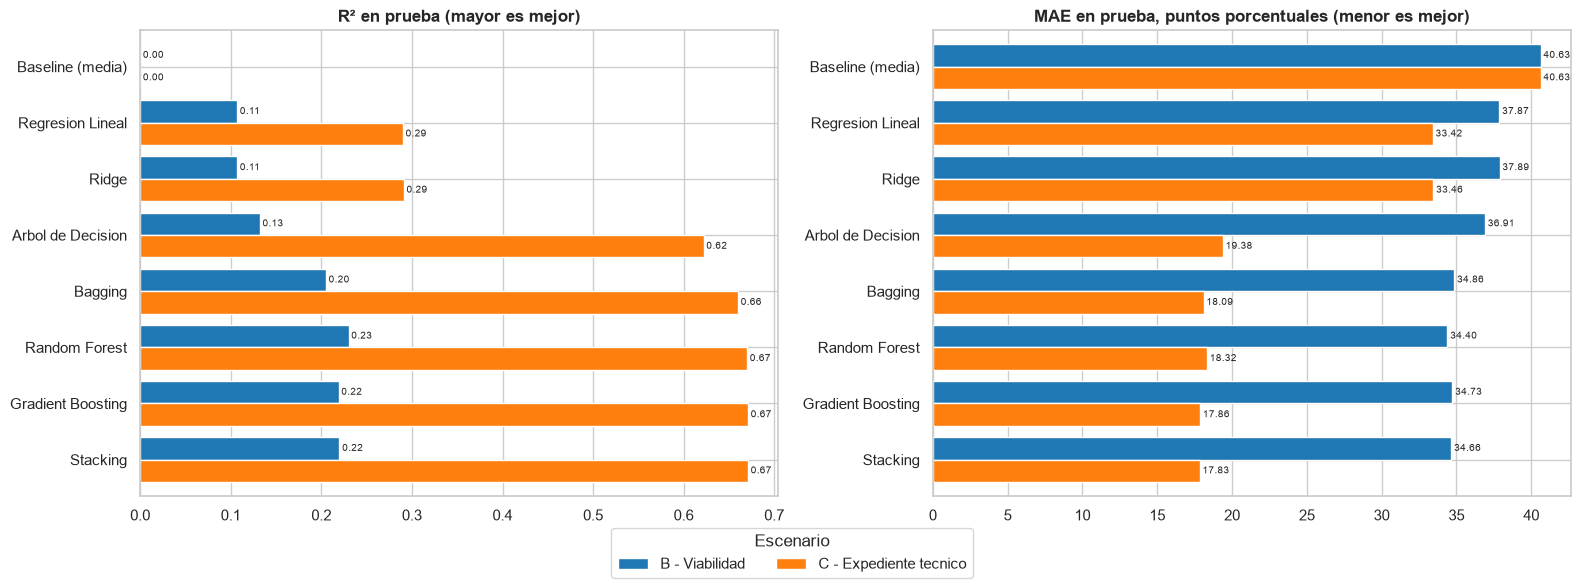

In [ ]:
# Desempeño en prueba de todos los modelos
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, met, titulo in zip(axes, ['R2_test', 'MAE_test'],
                           ['R² en prueba (mayor es mejor)', 'MAE en prueba, puntos porcentuales (menor es mejor)']):
    piv = df_test.pivot(index='Modelo', columns='Escenario', values=met).loc[orden_modelos]
    piv.plot.barh(ax=ax, color=[colores_esc[c] for c in piv.columns], width=0.8)
    ax.set_title(titulo); ax.set_ylabel('')
    ax.invert_yaxis()
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.2f', fontsize=7, padding=2)
h, l = axes[0].get_legend_handles_labels()
for ax in axes: ax.get_legend().remove()
fig.legend(h, l, title='Escenario', loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

comparacion_final = df_cv[['Escenario', 'Modelo', 'R2_cv']].merge(df_test, on=['Escenario', 'Modelo'])
comparacion_final['|R2_cv - R2_test|'] = (comparacion_final['R2_cv'] - comparacion_final['R2_test']).abs().round(3)

#### Error sobre la variable objetivo original (sin winsorizar)

*Respuesta a la observación del Hito 2:* "las métricas de test se calculan sobre el target winsorizado: los errores en los sobrecostos extremos (los que más importan) quedan recortados. Conviene reportar también el MAE sobre el target original".

Los modelos se siguen entrenando con el objetivo recortado (para que unos pocos valores de miles de por ciento no dominen el ajuste), pero aquí sus predicciones se comparan contra la **desviación real sin recortar**. Se reportan tres medidas:

- **MAE original:** error absoluto medio contra el valor real. Es muy sensible a los pocos proyectos con desviaciones enormes.
- **MedAE original:** mediana del error absoluto. Indica el error de la obra "típica" y no se deja arrastrar por los extremos.
- **MAE en obras recortadas:** error solo en las obras cuyo sobrecosto real superó el límite superior de la Winsorización, que son justamente los casos más graves.

In [ ]:
from sklearn.metrics import median_absolute_error

y_te_orig = y_bruto.loc[idx_test].to_numpy()
recortadas = y_te_orig > lim_sup
print(f'Obras de prueba con sobrecosto real mayor al limite superior ({lim_sup:.1f}%): '
      f'{recortadas.sum():,} ({recortadas.mean()*100:.1f}%)')

filas_orig = []
for (esc, nombre), pred in preds_test.items():
    filas_orig.append({'Escenario': esc, 'Modelo': nombre,
                       'MAE_original_test': mean_absolute_error(y_te_orig, pred),
                       'MedAE_original_test': median_absolute_error(y_te_orig, pred),
                       'MAE_obras_recortadas': mean_absolute_error(y_te_orig[recortadas], pred[recortadas])})
df_orig = pd.DataFrame(filas_orig).round(2)
df_test = df_test.merge(df_orig, on=['Escenario', 'Modelo'])
comparacion_final = comparacion_final.merge(df_orig, on=['Escenario', 'Modelo'])

tabla_orig = df_test.pivot(index='Modelo', columns='Escenario',
                           values=['MAE_test', 'MAE_original_test', 'MedAE_original_test', 'MAE_obras_recortadas'])
tabla_orig = tabla_orig.loc[orden_modelos].round(1)
tabla_orig

Obras de prueba con sobrecosto real mayor al limite superior (141.9%): 1,668 (8.8%)


MAE_test                        MAE_original_test  \
Escenario         B - Viabilidad C - Expediente tecnico    B - Viabilidad   
Modelo                                                                      
Baseline (media)            40.6                   40.6              84.6   
Regresion Lineal            37.9                   33.4              81.8   
Ridge                       37.9                   33.5              81.8   
Arbol de Decision           36.9                   19.4              80.8   
Bagging                     34.9                   18.1              78.8   
Random Forest               34.4                   18.3              78.3   
Gradient Boosting           34.7                   17.9              78.6   
Stacking                    34.7                   17.8              78.6   

                                         MedAE_original_test  \
Escenario         C - Expediente tecnico      B - Viabilidad   
Modelo                                                         
Baseline (media)                    84.6                31.8   
Regresion Lineal                    77.3                29.3   
Ridge                               77.3                29.4   
Arbol de Decision                   63.3                28.0   
Bagging                             62.0                26.4   
Random Forest                       62.2                25.9   
Gradient Boosting                   61.8                26.4   
Stacking                            61.7                26.3   

                                         MAE_obras_recortadas  \
Escenario         C - Expediente tecnico       B - Viabilidad   
Modelo                                                          
Baseline (media)                    31.8                607.5   
Regresion Lineal                    25.9                594.1   
Ridge                               26.0                594.5   
Arbol de Decision                   11.6                590.9   
Bagging                             10.6                581.6   
Random Forest                       10.9                583.4   
Gradient Boosting                   10.4                583.3   
Stacking                            10.4                582.2   

                                          
Escenario         C - Expediente tecnico  
Modelo                                    
Baseline (media)                   607.5  
Regresion Lineal                   573.5  
Ridge                              574.0  
Arbol de Decision                  536.6  
Bagging                            532.6  
Random Forest                      536.6  
Gradient Boosting                  532.9  
Stacking                           532.3

**Lectura del error sobre el target original:**
- El **8.8% de las obras de prueba (1,668)** tuvo un sobrecosto real mayor a 141.9%, el límite superior de la Winsorización. En esas obras está la diferencia entre las dos formas de medir el error.
- **El MAE original es mucho mayor que el winsorizado** (Gradient Boosting: 78.6 frente a 34.7 pp en B, y 61.8 frente a 17.9 pp en C), porque unas pocas obras con desviaciones de cientos o miles por ciento dominan el promedio. En esas obras extremas el error medio va de 532 a 594 pp en **todos** los modelos, apenas por debajo del baseline (607.5 pp): **ningún modelo anticipa la magnitud de los sobrecostos extremos**.
- **La mediana del error (MedAE) cuenta otra historia:** para la obra típica, el error de Gradient Boosting es de 26.4 pp en B y de **10.4 pp en C**, frente a 31.8 pp del baseline. El modelo C reduce a un tercio el error de la obra típica.
- **El orden de los modelos no cambia** con el target original: los ensambles de árboles siguen arriba en las tres medidas y Gradient Boosting y Stacking siguen empatados, así que la elección de 6.5.1 se mantiene.
- **Qué significa para el uso del modelo:** sirve para **ordenar** las obras por riesgo (sección 6.8), no para estimar cuánto se desviará exactamente una obra con sobrecosto extremo. Por eso el criterio principal sigue siendo el RMSE sobre el target recortado, y el error sobre el target original se reporta como complemento.

#### 6.5.1 Aplicación de los criterios para elegir el mejor modelo

Se aplican, en orden, los criterios definidos en 6.2.1. La siguiente celda calcula la regla de decisión de forma automática para cada escenario.

In [ ]:
TOLERANCIA = 0.01   # empate practico: RMSE dentro del 1% del mejor

def elegir_mejor(df_esc):
    d = df_esc[df_esc['Modelo'] != 'Baseline (media)'].sort_values('RMSE_test').copy()
    mejor_rmse = d['RMSE_test'].iloc[0]
    d['Dif. vs mejor RMSE (%)'] = ((d['RMSE_test'] / mejor_rmse - 1) * 100).round(2)
    d['Empate practico (C1)'] = d['RMSE_test'] <= mejor_rmse * (1 + TOLERANCIA)
    elegido = d[d['Empate practico (C1)']].sort_values(['Brecha sobreajuste', 'Tiempo entrenamiento (s)']).iloc[0]
    d['Elegido'] = np.where(d['Modelo'] == elegido['Modelo'], '<-- MEJOR', '')
    return elegido['Modelo'], d

mejor_por_esc, tablas_decision = {}, {}
for esc in ESCENARIOS:
    mejor, tabla = elegir_mejor(comparacion_final[comparacion_final['Escenario'] == esc])
    mejor_por_esc[esc] = mejor
    tablas_decision[esc] = tabla
    cols = ['Modelo', 'RMSE_test', 'Dif. vs mejor RMSE (%)', 'Empate practico (C1)', 'MAE_test', 'R2_test',
            'R2_ajustado_test', 'R2_cv', '|R2_cv - R2_test|', 'R2_train', 'Brecha sobreajuste',
            'Tiempo entrenamiento (s)', 'Elegido']
    display(tabla[cols].style.apply(lambda r: ['background-color: #d5f5e3; font-weight: bold' if r['Elegido']
                                               else '' for _ in r], axis=1)
            .format(precision=3).hide(axis='index')
            .set_caption(f'Tabla 6.5 — {esc}: modelos ordenados por RMSE en prueba (criterio 1)'))
    print(f'>>> Mejor modelo para {esc}: {mejor}\n')

# Para ahorrar memoria se conservan solo los pipelines que se usan en las secciones siguientes
necesarios = ({(e, m) for e, m in mejor_por_esc.items()} | {('B - Viabilidad', 'Ridge')}
              | {(e, 'Stacking') for e in ESCENARIOS})
pipes_finales = {k: v for k, v in pipes_finales.items() if k in necesarios}

Modelo,RMSE_test,Dif. vs mejor RMSE (%),Empate practico (C1),MAE_test,R2_test,R2_ajustado_test,R2_cv,|R2_cv - R2_test|,R2_train,Brecha sobreajuste,Tiempo entrenamiento (s),Elegido
Random Forest,45.219,0.000,True,34.399,0.230,0.219,0.181,0.049,0.479,0.249,37.501,
Stacking,45.508,0.640,True,34.659,0.220,0.209,0.193,0.027,0.304,0.084,102.492,
Gradient Boosting,45.547,0.730,True,34.731,0.219,0.207,0.191,0.028,0.295,0.076,27.438,<-- MEJOR
Bagging,45.958,1.630,False,34.857,0.205,0.193,0.186,0.019,0.604,0.399,52.577,
Arbol de Decision,48.022,6.200,False,36.909,0.132,0.119,0.125,0.007,0.143,0.011,1.865,
Regresion Lineal,48.695,7.690,False,37.867,0.107,0.094,0.102,0.005,0.109,0.002,2.097,
Ridge,48.697,7.690,False,37.887,0.107,0.094,0.102,0.005,0.108,0.001,1.329,


>>> Mejor modelo para B - Viabilidad: Gradient Boosting



Modelo,RMSE_test,Dif. vs mejor RMSE (%),Empate practico (C1),MAE_test,R2_test,R2_ajustado_test,R2_cv,|R2_cv - R2_test|,R2_train,Brecha sobreajuste,Tiempo entrenamiento (s),Elegido
Stacking,29.543,0.000,True,17.833,0.671,0.666,0.652,0.019,0.711,0.039,95.051,
Gradient Boosting,29.561,0.060,True,17.860,0.671,0.666,0.652,0.019,0.709,0.038,26.131,<-- MEJOR
Random Forest,29.590,0.160,True,18.325,0.670,0.665,0.565,0.105,0.785,0.114,40.383,
Bagging,30.039,1.680,False,18.093,0.660,0.655,0.645,0.015,0.822,0.161,71.074,
Arbol de Decision,31.672,7.210,False,19.382,0.622,0.617,0.612,0.010,0.637,0.014,2.919,
Ridge,43.399,46.900,False,33.458,0.291,0.280,0.287,0.004,0.293,0.002,1.623,
Regresion Lineal,43.419,46.970,False,33.419,0.290,0.280,0.287,0.003,0.294,0.003,2.483,


>>> Mejor modelo para C - Expediente tecnico: Gradient Boosting



**Aplicación de los criterios (tablas de arriba):**

| Criterio | Escenario B — Viabilidad | Escenario C — Expediente técnico |
|---|---|---|
| **1. Precisión** (RMSE en prueba) | Random Forest tiene el menor RMSE (45.22), pero Stacking (+0.64%) y Gradient Boosting (+0.73%) quedan **dentro del 1%**: empate práctico entre los tres | Stacking tiene el menor RMSE (29.54), pero Gradient Boosting (+0.06%) y Random Forest (+0.16%) quedan **dentro del 1%**: empate práctico entre los tres |
| **2. Generalización** (brecha R² train − prueba) | Random Forest: **0.25** (sobreajusta mucho) · Stacking: 0.08 · **Gradient Boosting: 0.08 (la menor)** | Random Forest: 0.11 · Stacking: 0.039 · **Gradient Boosting: 0.038 (la menor)** |
| **3. Tiempo de entrenamiento** | Gradient Boosting: **27.4 s** vs Random Forest 37.5 s y Stacking 102.5 s | Gradient Boosting: **26.1 s** vs Random Forest 40.4 s y Stacking 95.1 s |
| **4. Interpretabilidad** | Gradient Boosting es un solo modelo; Stacking combina tres | Igual |
| **Mejor modelo** | **Gradient Boosting** | **Gradient Boosting** |

- **Gradient Boosting es el mejor modelo en ambos escenarios.** Empata en precisión con los mejores (diferencias menores al 1% del RMSE, que no tienen relevancia práctica), pero es el que **menos sobreajusta** y el **más rápido** de los ensambles: entrena 1.4 veces más rápido que Random Forest, entre 1.9 y 2.7 veces más rápido que Bagging y casi 4 veces más rápido que Stacking.
- **Random Forest gana en RMSE en B, pero memoriza:** R² de 0.48 en train contra 0.23 en prueba, y en validación cruzada había quedado por debajo de Gradient Boosting.
- **Stacking no justifica su costo:** logra lo mismo que Gradient Boosting, pero tarda casi 4 veces más (102.5 s frente a 27.4 s en B), porque entrena tres modelos más el meta-modelo.
- **Resultados en prueba vs validación cruzada:** las diferencias son de 0.05 o menos, salvo Random Forest en C (0.10). Esa excepción se explica porque la validación cruzada usó su configuración inicial y la prueba usa la ajustada en 6.4.
- **Desempeño del mejor modelo:** en B, R² = 0.22 y MAE = 34.7 pp; en C, R² = 0.67 y MAE = 17.9 pp, menos de la mitad del error del baseline (40.6 pp).
- **Tiempos de predicción:** todos los modelos predicen las 18,894 obras de prueba en menos de un segundo (el más lento, Stacking, tarda 0.8 s), así que la diferencia práctica está en el tiempo de entrenamiento. Este tiempo importa porque el modelo debe reentrenarse cada vez que el MEF actualiza sus datos.

#### Vista comparativa multi-métrica (gráfico de radar)

*Respuesta a la observación del Hito 2:* "no hay gráfico de radar ni otra vista comparativa multi-métrica de los modelos (hay barras por métrica)".

El radar resume en una sola figura los criterios de elección de 6.2.1, con el modelo elegido en 6.5.1 resaltado. Cada eje es una métrica escalada entre 0 y 1 **dentro de cada escenario**, donde **1 = el mejor modelo en esa métrica** y 0 = el peor (para el error, la brecha y el tiempo se invierte la escala, de modo que más afuera siempre es mejor). El tiempo de entrenamiento se escala en logaritmo, porque va de segundos a minutos. El baseline no se incluye porque solo sirve de referencia.

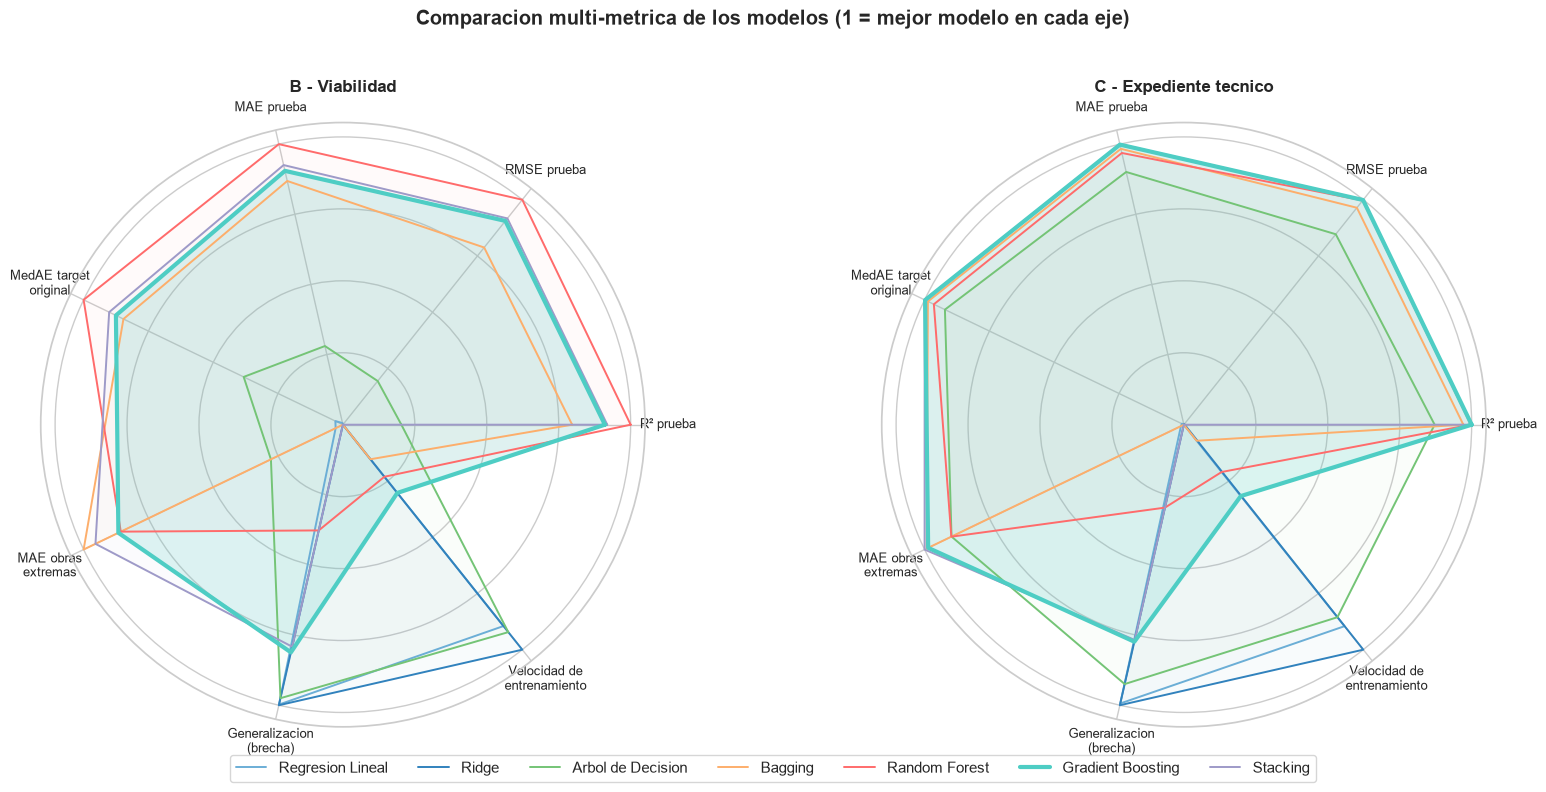

,Puntaje promedio — B - Viabilidad,Puntaje promedio — C - Expediente tecnico
Modelo,,
Gradient Boosting,0.797,0.867
Random Forest,0.781,0.761
Stacking,0.773,0.824
Bagging,0.636,0.710
Arbol de Decision,0.462,0.888
Ridge,0.286,0.286
Regresion Lineal,0.279,0.273


In [ ]:
ejes_radar = {
    'R² prueba':                     ('R2_test', True),
    'RMSE prueba':                   ('RMSE_test', False),
    'MAE prueba':                    ('MAE_test', False),
    'MedAE target\noriginal':        ('MedAE_original_test', False),
    'MAE obras\nextremas':           ('MAE_obras_recortadas', False),
    'Generalizacion\n(brecha)':      ('Brecha sobreajuste', False),
    'Velocidad de\nentrenamiento':   ('Tiempo entrenamiento (s)', False),
}

def escalar(serie, mayor_es_mejor, log=False):
    v = np.log10(serie) if log else serie
    rango = v.max() - v.min()
    if rango == 0:
        return pd.Series(1.0, index=serie.index)
    s = (v - v.min()) / rango
    return s if mayor_es_mejor else 1 - s

modelos_radar = [m for m in orden_modelos if m != 'Baseline (media)']
angulos = np.linspace(0, 2 * np.pi, len(ejes_radar), endpoint=False).tolist()
angulos += angulos[:1]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), subplot_kw={'polar': True})
puntajes_radar = {}
for ax, esc in zip(axes, ['B - Viabilidad', 'C - Expediente tecnico']):
    d = df_test[(df_test['Escenario'] == esc) & (df_test['Modelo'].isin(modelos_radar))].set_index('Modelo')
    esc_norm = pd.DataFrame({eje: escalar(d[col], mejor, log=(col == 'Tiempo entrenamiento (s)'))
                             for eje, (col, mejor) in ejes_radar.items()}).loc[modelos_radar]
    puntajes_radar[esc] = esc_norm
    for modelo in modelos_radar:
        valores = esc_norm.loc[modelo].tolist()
        valores += valores[:1]
        destacado = modelo == mejor_por_esc[esc]
        ax.plot(angulos, valores, color=paleta_modelos[modelo], lw=3 if destacado else 1.4,
                label=modelo, zorder=3 if destacado else 2)
        ax.fill(angulos, valores, color=paleta_modelos[modelo], alpha=0.18 if destacado else 0.03)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(list(ejes_radar.keys()), fontsize=9)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0]); ax.set_yticklabels(['', '', '', ''])
    ax.set_ylim(0, 1.05)
    ax.set_title(esc, fontweight='bold', pad=22)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=len(modelos_radar), bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Comparacion multi-metrica de los modelos (1 = mejor modelo en cada eje)', fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

# Area del poligono como resumen (promedio de los ejes escalados)
resumen_radar = pd.DataFrame({esc: p.mean(axis=1) for esc, p in puntajes_radar.items()}).round(3)
resumen_radar.columns = [f'Puntaje promedio — {c}' for c in resumen_radar.columns]
resumen_radar.sort_values(resumen_radar.columns[0], ascending=False)

**Lectura del radar:**
- **Escenario B:** Gradient Boosting tiene el polígono más amplio (puntaje promedio 0.80), seguido de Random Forest (0.78) y Stacking (0.77). Random Forest llega al borde en precisión pero cae a 0.38 en generalización (brecha de 0.25); Bagging cae a 0 en ese eje (es el que más sobreajusta) y Stacking cae a 0 en velocidad.
- **Escenario C:** el puntaje promedio más alto lo obtiene el **Árbol de Decisión** (0.89), apenas por delante de Gradient Boosting (0.87). El árbol entrena en 3 segundos y casi no sobreajusta, pero su RMSE es 7.2% peor que el del mejor modelo. El radar pondera todos los ejes por igual, mientras que la regla de 6.2.1 pone la **precisión primero**; por eso el elegido sigue siendo Gradient Boosting. Es un buen ejemplo de por qué la regla de decisión se fijó antes de ver los resultados: un promedio simple de métricas puede premiar a un modelo rápido aunque se equivoque más.
- **Modelos lineales:** sus polígonos son pequeños en todos los ejes de error y solo llegan al borde en velocidad y generalización (no sobreajustan porque no tienen capacidad para memorizar).
- **Lectura conjunta:** Gradient Boosting es el único ensamble que no se hunde en ningún eje: queda en 0.77 o más en todas las métricas de precisión y en generalización, y aunque en velocidad marca 0.30, es el ensamble más rápido (los demás quedan entre 0 y 0.23). No es el mejor en cada métrica por separado, pero es el más equilibrado entre los modelos precisos.

#### 6.5.2 Evidencia empírica: ¿qué pasaría si se incluyeran las 18 variables de fuga?

*Respuesta a la observación del Hito 1:* "convendría mostrar al menos una vez qué pasaría si se incluyeran, para reforzar con evidencia (no solo argumento) por qué se excluyen".

En la sección 4.9 se descartaron a priori 18 variables que solo existen durante o después de la ejecución de la obra (avances, devengados, saldos, certificaciones, etapas, fechas de ejecución física, etc.). Aquí se agregan al escenario preventivo **B** y se mide el efecto en dos variantes:

- **B + 17 variables de fuga**: todas excepto `COSTO_ACTUALIZADO`.
- **B + 18 variables de fuga**: incluye también `COSTO_ACTUALIZADO`, que junto con `MONTO_VIABLE` *es* la fórmula de la variable objetivo.

Se usa la misma validación cruzada de 5 folds **sobre el conjunto de entrenamiento** (el conjunto de prueba no se toca) con dos modelos: Regresión Lineal (referencia lineal) y Gradient Boosting.

In [ ]:
FUGA_NUM = ['AVANCE_FISICO', 'AVANCE_EJECUCION', 'DEV_ANIO_ACTUAL', 'SALDO_EJECUTAR', 'DEVEN_ACUMUL_ANIO_ANT',
            'CERTIF_ANIO_ACTUAL', 'COMPROM_ANUAL_ANIO_ACTUAL', 'ULTIMO_DEVENGADO', 'PRIMER_DEVENGADO',
            'FEC_REG_F9', 'FEC_FIN_EJEC_FISICA', 'FEC_INI_EJEC_FISICA', 'ULT_FEC_DECLA_ESTIM']
FUGA_CAT = ['SITUACION', 'ESTADO', 'ETAPA_F8', 'ETAPA_F9']
assert len(FUGA_NUM) + len(FUGA_CAT) + 1 == len(FUGA)   # 17 + COSTO_ACTUALIZADO = las 18 de la seccion 4.9

X_fuga = df_model[FUGA_NUM + FUGA_CAT + ['COSTO_ACTUALIZADO']].copy()
for c in ['AVANCE_FISICO', 'AVANCE_EJECUCION', 'DEV_ANIO_ACTUAL', 'SALDO_EJECUTAR', 'DEVEN_ACUMUL_ANIO_ANT',
          'CERTIF_ANIO_ACTUAL', 'COMPROM_ANUAL_ANIO_ACTUAL', 'COSTO_ACTUALIZADO']:
    X_fuga[c] = pd.to_numeric(X_fuga[c], errors='coerce')
for c in ['ULTIMO_DEVENGADO', 'PRIMER_DEVENGADO']:            # periodo AAAAMM -> numero de meses
    v = pd.to_numeric(X_fuga[c], errors='coerce')
    X_fuga[c] = (v // 100) * 12 + v % 100
for c in ['FEC_REG_F9', 'FEC_FIN_EJEC_FISICA', 'FEC_INI_EJEC_FISICA', 'ULT_FEC_DECLA_ESTIM']:   # fecha -> año decimal
    f = pd.to_datetime(X_fuga[c], errors='coerce')
    X_fuga[c] = f.dt.year + f.dt.dayofyear / 365

X_tr_fuga = pd.concat([X_tr, X_fuga.loc[idx_train]], axis=1)

# Escenarios temporales solo para este experimento (se retiran al final de la seccion)
ESCENARIOS['B + 17 fuga'] = {'num': num_B + FUGA_NUM, 'cat': cat_B + FUGA_CAT}
ESCENARIOS['B + 18 fuga'] = {'num': num_B + FUGA_NUM + ['COSTO_ACTUALIZADO'], 'cat': cat_B + FUGA_CAT}

modelos_fuga = {'Regresion Lineal': LinearRegression(), 'Gradient Boosting': HistGradientBoostingRegressor(random_state=SEMILLA)}
filas_fuga = []
for esc in ['B + 17 fuga', 'B + 18 fuga']:
    for nombre, modelo in modelos_fuga.items():
        t0 = time.time()
        res = cross_validate(crear_pipeline(esc, modelo), X_tr_fuga[columnas(esc)], y_tr, cv=cv, scoring=scoring)
        filas_fuga.append({'Escenario': esc, 'Modelo': nombre, 'MAE_cv': -res['test_MAE'].mean(),
                           'RMSE_cv': -res['test_RMSE'].mean(), 'R2_cv': res['test_R2'].mean()})
        print(f'{esc:12s} | {nombre:18s} | R2_cv = {res["test_R2"].mean():.3f} | {time.time()-t0:4.0f} s')

df_fuga = pd.concat([df_cv[(df_cv['Escenario'] == 'B - Viabilidad') &
                           (df_cv['Modelo'].isin(['Regresion Lineal', 'Gradient Boosting']))]
                     [['Escenario', 'Modelo', 'MAE_cv', 'RMSE_cv', 'R2_cv']],
                     pd.DataFrame(filas_fuga)]).round(3)
df_fuga

B + 17 fuga  | Regresion Lineal   | R2_cv = 0.141 |   17 s


B + 17 fuga  | Gradient Boosting  | R2_cv = 0.899 |   36 s


B + 18 fuga  | Regresion Lineal   | R2_cv = 0.141 |   16 s


B + 18 fuga  | Gradient Boosting  | R2_cv = 0.989 |   33 s


,Escenario,Modelo,MAE_cv,RMSE_cv,R2_cv
1,B - Viabilidad,Regresion Lineal,38.104,49.053,0.102
6,B - Viabilidad,Gradient Boosting,35.619,46.568,0.191
0,B + 17 fuga,Regresion Lineal,36.217,47.920,0.141
1,B + 17 fuga,Gradient Boosting,10.510,16.451,0.899
2,B + 18 fuga,Regresion Lineal,36.199,47.903,0.141
3,B + 18 fuga,Gradient Boosting,3.117,5.339,0.989


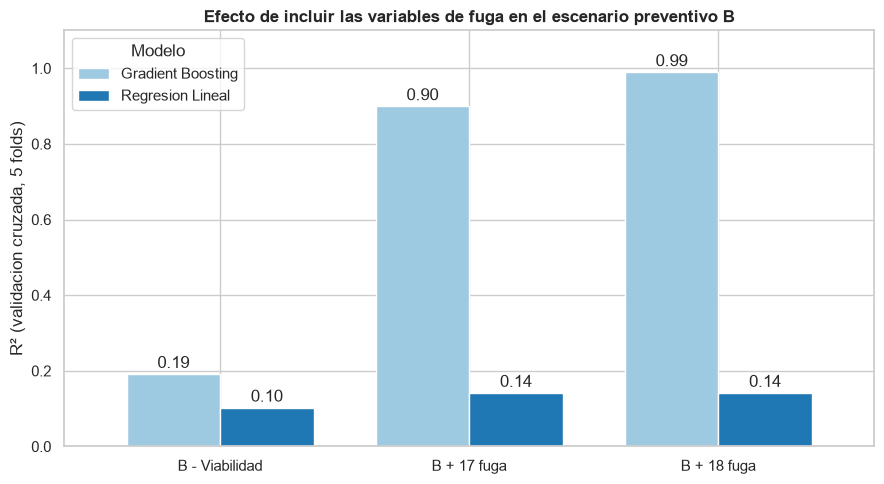

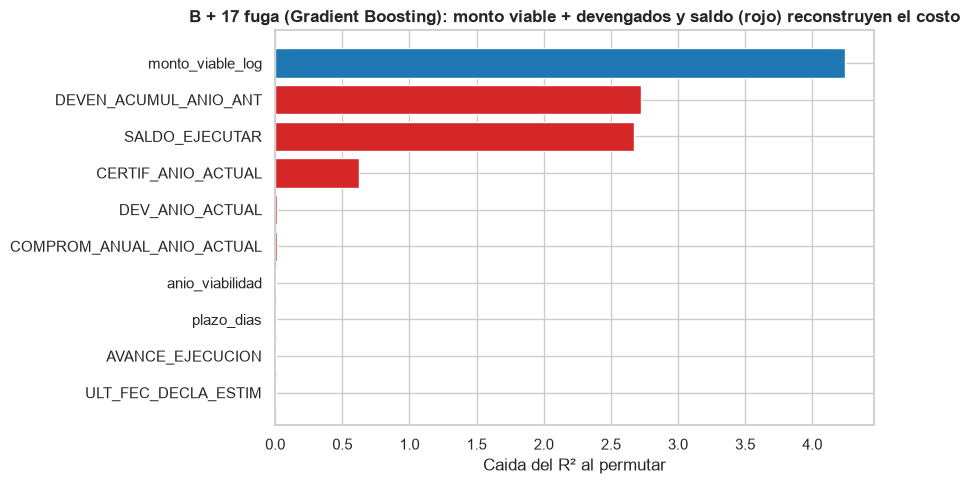

Proyectos donde DEVEN_ACUMUL_ANIO_ANT + DEV_ANIO_ACTUAL + SALDO_EJECUTAR = COSTO_ACTUALIZADO (±1%): 73.0%


In [ ]:
# Grafico: R2 en validacion cruzada con y sin variables de fuga
piv = df_fuga.pivot(index='Escenario', columns='Modelo', values='R2_cv').loc[['B - Viabilidad', 'B + 17 fuga', 'B + 18 fuga']]
ax = piv.plot.bar(figsize=(9, 5), color=['#9ecae1', '#1f77b4'], rot=0, width=0.75)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.2f', padding=2)
ax.set_ylim(0, 1.1); ax.set_ylabel('R² (validacion cruzada, 5 folds)'); ax.set_xlabel('')
ax.set_title('Efecto de incluir las variables de fuga en el escenario preventivo B')
plt.tight_layout(); plt.show()

# ¿Que variables usa el modelo con fuga? Permutation importance en una particion de validacion dentro de train
from sklearn.model_selection import train_test_split
esc = 'B + 17 fuga'
Xa, Xv, ya, yv = train_test_split(X_tr_fuga[columnas(esc)], y_tr, test_size=0.2, random_state=SEMILLA)
pipe_fuga = crear_pipeline(esc, modelos_fuga['Gradient Boosting']).fit(Xa, ya)
pi_f = permutation_importance(pipe_fuga, Xv.iloc[:5000], yv.iloc[:5000], scoring='r2', n_repeats=5,
                              random_state=SEMILLA)
imp_fuga = pd.Series(pi_f.importances_mean, index=columnas(esc)).sort_values(ascending=False).head(10)[::-1]
plt.figure(figsize=(9, 5))
plt.barh(imp_fuga.index, imp_fuga.values,
         color=['#d62728' if v in FUGA_NUM + FUGA_CAT else '#1f77b4' for v in imp_fuga.index])
plt.title('B + 17 fuga (Gradient Boosting): monto viable + devengados y saldo (rojo) reconstruyen el costo')
plt.xlabel('Caida del R² al permutar')
plt.tight_layout(); plt.show()

# ¿Por que? devengado acumulado + devengado del año + saldo por ejecutar = costo actualizado
suma = (X_fuga['DEVEN_ACUMUL_ANIO_ANT'].fillna(0) + X_fuga['DEV_ANIO_ACTUAL'].fillna(0)
        + X_fuga['SALDO_EJECUTAR'].fillna(0))
coincide = ((suma - X_fuga['COSTO_ACTUALIZADO']).abs() < 0.01 * X_fuga['COSTO_ACTUALIZADO']).mean()
print(f'Proyectos donde DEVEN_ACUMUL_ANIO_ANT + DEV_ANIO_ACTUAL + SALDO_EJECUTAR = COSTO_ACTUALIZADO (±1%): {coincide*100:.1f}%')

# Se retiran los escenarios del experimento para que las secciones siguientes trabajen solo con B y C
for k in ['B + 17 fuga', 'B + 18 fuga']:
    ESCENARIOS.pop(k)

**Conclusión de la evidencia:**

| Escenario | R² Gradient Boosting | MAE Gradient Boosting | R² Regresión Lineal |
|---|---|---|---|
| B — preventivo (sin fuga) | 0.19 | 35.6 pp | 0.10 |
| B + 17 variables de fuga | **0.90** | 10.5 pp | 0.14 |
| B + 18 variables de fuga (con COSTO_ACTUALIZADO) | **0.99** | 3.1 pp | 0.14 |

- **Con las variables de fuga, el R² de Gradient Boosting salta de 0.19 a 0.90**, y con `COSTO_ACTUALIZADO` llega a 0.99: el modelo "reconstruye" la fórmula de la variable objetivo.
- **La importancia de variables explica por qué:** el modelo combina el monto viable con el devengado acumulado y el saldo por ejecutar. En el 73% de los proyectos, **devengado acumulado + devengado del año + saldo por ejecutar = costo actualizado**; aun sin `COSTO_ACTUALIZADO`, las otras variables de fuga contienen el costo final de forma indirecta.
- **La Regresión Lineal casi no mejora** (0.10 → 0.14), porque el sobrecosto es un *cociente* entre esos montos y el monto viable, y una suma ponderada no puede reproducirlo. La fuga aparece con toda su fuerza en los modelos flexibles.
- Ese modelo **luce excelente pero es inútil para el objetivo del proyecto**: al aprobar una obra no existen devengados, saldos ni avances.
- Esto **confirma con datos** la exclusión a priori del Hito 1 y el Filtro 2 (disponibilidad temporal) de la sección 6.1.3: **las métricas altas no sirven si el modelo usa información que no existirá cuando se necesite la predicción.**

#### 6.5.3 ¿Se conoce `MONTO_ET_F8` antes de ejecutar la obra? (revisión del escenario C)

*Respuesta a la observación del Hito 2:* "el propio notebook excluye `TIENE_F8` por ser estado del proyecto a la fecha de descarga, pero conserva `MONTO_ET_F8`, que también viene del snapshot de descarga. Si ese monto se actualiza durante la ejecución (modificaciones del expediente), parte del R² de 0.67 sería fuga. El dato de que en el 31.7% de los proyectos el costo actualizado es idéntico al monto del expediente apunta en esa dirección. Hay que confirmar que es el monto original del expediente aprobado".

Con un único *snapshot* no se puede ver el historial de cambios del campo, así que se responde con **dos pruebas indirectas**:

1. **¿Cómo se comporta `MONTO_ET_F8` a medida que avanza la ejecución?** Se agrupan las obras según qué porcentaje de su costo ya se gastó (devengado acumulado / costo actualizado). Si el monto del expediente se actualizara con las modificaciones de obra, en las obras más avanzadas el costo actualizado y el monto del expediente deberían **coincidir cada vez más**. Si el monto es el original, deberían **separarse**, porque las modificaciones (adicionales, ampliaciones) se suman al costo actualizado pero no al expediente.
2. **¿El escenario C sigue funcionando donde la fuga no es posible?** Se evalúa el mismo modelo de C en subconjuntos del conjunto de prueba: sin los casos "espejo" (costo actualizado = expediente), en obras casi terminadas y en obras **sin ningún gasto ejecutado**, donde el expediente todavía no pudo modificarse durante la obra. Además, se reentrena C excluyendo los casos espejo de train y de prueba.

PRUEBA 1 — Relacion entre COSTO_ACTUALIZADO y MONTO_ET_F8 segun el avance financiero de la obra


,obras,pct_costo_igual_ET,pct_costo_mayor_ET,desviacion_final_mediana
etapa,,,,
0% (sin gasto),14216,40.3,54.5,3.7
0-25%,20782,48.9,42.9,24.0
25-50%,5100,38.2,48.7,22.7
50-75%,6627,30.7,55.5,21.8
75-95%,17035,22.8,65.7,20.3
> 95%,30709,16.6,65.3,15.3


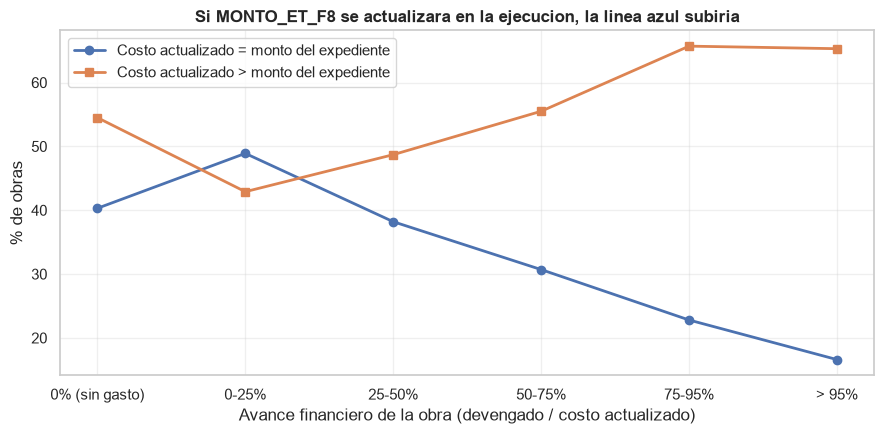

In [ ]:
et_num = pd.to_numeric(df_model['MONTO_ET_F8'], errors='coerce')
costo = df_model['COSTO_ACTUALIZADO']
gastado = (pd.to_numeric(df_model['DEVEN_ACUMUL_ANIO_ANT'], errors='coerce').fillna(0)
           + pd.to_numeric(df_model['DEV_ANIO_ACTUAL'], errors='coerce').fillna(0))
avance_fin = gastado / costo.replace(0, np.nan)
espejo = (costo - et_num).abs() < 1

etapas = pd.cut(avance_fin, [-0.01, 0.0001, 0.25, 0.5, 0.75, 0.95, np.inf],
                labels=['0% (sin gasto)', '0-25%', '25-50%', '50-75%', '75-95%', '> 95%'])
prueba1 = pd.DataFrame({'etapa': etapas, 'espejo': espejo,
                        'costo_mayor_que_ET': costo > et_num + 1,
                        'desv_final': y_bruto}).groupby('etapa', observed=True).agg(
    obras=('espejo', 'size'),
    pct_costo_igual_ET=('espejo', lambda s: s.mean() * 100),
    pct_costo_mayor_ET=('costo_mayor_que_ET', lambda s: s.mean() * 100),
    desviacion_final_mediana=('desv_final', 'median')).round(1)
print('PRUEBA 1 — Relacion entre COSTO_ACTUALIZADO y MONTO_ET_F8 segun el avance financiero de la obra')
display(prueba1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(prueba1.index.astype(str), prueba1['pct_costo_igual_ET'], 'o-', lw=2, label='Costo actualizado = monto del expediente')
ax.plot(prueba1.index.astype(str), prueba1['pct_costo_mayor_ET'], 's-', lw=2, label='Costo actualizado > monto del expediente')
ax.set(xlabel='Avance financiero de la obra (devengado / costo actualizado)', ylabel='% de obras',
       title='Si MONTO_ET_F8 se actualizara en la ejecucion, la linea azul subiria')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

PRUEBA 2 — Desempeno de Gradient Boosting en B y C segun el subconjunto de prueba


,Obras,R² B,R² C,MAE B,MAE C
Subconjunto de prueba,,,,,
Todo el conjunto de prueba,18894,0.219,0.671,34.731,17.860
Sin casos espejo (costo != expediente),13152,0.236,0.571,35.274,22.580
Obras casi terminadas (gasto > 95%),6090,0.202,0.638,34.294,19.363
Casi terminadas y sin espejo,5066,0.215,0.599,34.794,21.481
Sin ningun gasto ejecutado (gasto = 0),2842,0.145,0.635,26.395,12.759
Reentrenado y evaluado sin casos espejo,13152,0.241,0.576,35.230,23.234


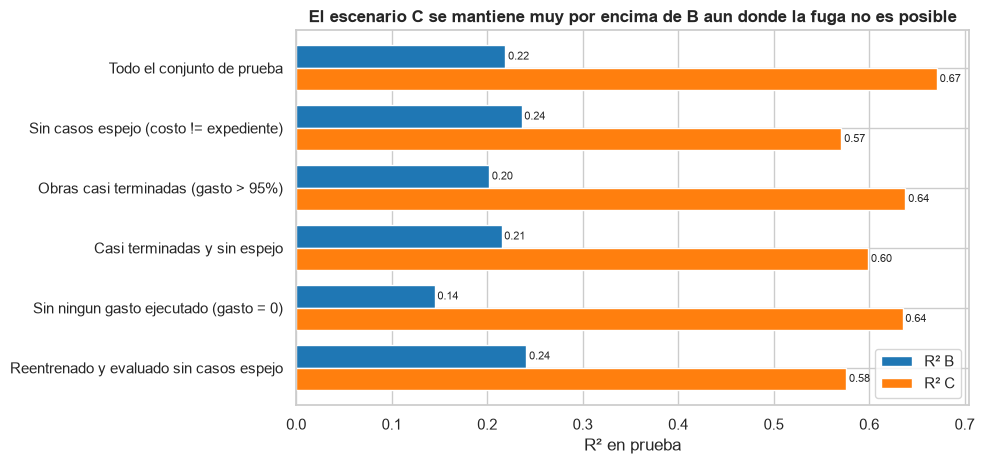

In [ ]:
# PRUEBA 2 — el mejor modelo de B y de C evaluado en subconjuntos del conjunto de prueba
pred_B = preds_test[('B - Viabilidad', mejor_por_esc['B - Viabilidad'])]
pred_C = preds_test[('C - Expediente tecnico', mejor_por_esc['C - Expediente tecnico'])]
av_te, esp_te = avance_fin.loc[idx_test], espejo.loc[idx_test]
subconjuntos = {
    'Todo el conjunto de prueba': np.ones(len(idx_test), bool),
    'Sin casos espejo (costo != expediente)': (~esp_te).to_numpy(),
    'Obras casi terminadas (gasto > 95%)': (av_te > 0.95).to_numpy(),
    'Casi terminadas y sin espejo': ((av_te > 0.95) & ~esp_te).to_numpy(),
    'Sin ningun gasto ejecutado (gasto = 0)': (av_te.fillna(0) == 0).to_numpy(),
}
filas_sub = []
for nombre, m in subconjuntos.items():
    filas_sub.append({'Subconjunto de prueba': nombre, 'Obras': int(m.sum()),
                      'R² B': r2_score(y_te[m], pred_B[m]), 'R² C': r2_score(y_te[m], pred_C[m]),
                      'MAE B': mean_absolute_error(y_te[m], pred_B[m]), 'MAE C': mean_absolute_error(y_te[m], pred_C[m])})

# Reentrenar B y C sin los casos espejo (en train y en prueba)
sin_esp_tr, sin_esp_te = (~espejo.loc[idx_train]).to_numpy(), (~esp_te).to_numpy()
for esc in ESCENARIOS:
    gb = crear_modelos(esc, mejores_params[esc])['Gradient Boosting']
    pipe_se = crear_pipeline(esc, gb).fit(X_tr[columnas(esc)][sin_esp_tr], y_tr[sin_esp_tr])
    pr = pipe_se.predict(X_te[columnas(esc)][sin_esp_te])
    filas_sub_se = {'R²': r2_score(y_te[sin_esp_te], pr), 'MAE': mean_absolute_error(y_te[sin_esp_te], pr)}
    if esc.startswith('B'):
        r2_B_se, mae_B_se = filas_sub_se['R²'], filas_sub_se['MAE']
    else:
        r2_C_se, mae_C_se = filas_sub_se['R²'], filas_sub_se['MAE']
filas_sub.append({'Subconjunto de prueba': 'Reentrenado y evaluado sin casos espejo', 'Obras': int(sin_esp_te.sum()),
                  'R² B': r2_B_se, 'R² C': r2_C_se, 'MAE B': mae_B_se, 'MAE C': mae_C_se})
prueba2 = pd.DataFrame(filas_sub).set_index('Subconjunto de prueba').round(3)
print('PRUEBA 2 — Desempeno de Gradient Boosting en B y C segun el subconjunto de prueba')
display(prueba2)

ax = prueba2[['R² B', 'R² C']].plot.barh(figsize=(10, 4.8), color=[colores_esc['B - Viabilidad'], colores_esc['C - Expediente tecnico']], width=0.75)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.2f', padding=2, fontsize=8)
ax.invert_yaxis(); ax.set_xlabel('R² en prueba'); ax.set_ylabel('')
ax.set_title('El escenario C se mantiene muy por encima de B aun donde la fuga no es posible')
plt.tight_layout(); plt.show()

**Conclusión de la revisión de `MONTO_ET_F8`:**
- **Prueba 1.** A medida que avanza la ejecución, la proporción de obras donde el costo actualizado es igual al monto del expediente **baja** de 49% (obras con 0–25% de avance financiero) a 17% (obras con más de 95%), y la proporción con costo actualizado **mayor** que el expediente **sube** de 43% a 65%. Si `MONTO_ET_F8` se actualizara con las modificaciones de la obra pasaría lo contrario. El comportamiento es consistente con que el campo guarda el **monto del expediente aprobado** y con que los adicionales y ampliaciones se registran en `COSTO_ACTUALIZADO`.
- **¿Por qué hay 31.7% de casos espejo?** Cuando se aprueba el expediente, el costo actualizado toma ese monto; mientras la obra no tenga modificaciones, ambos coinciden. Por eso los casos espejo se concentran en obras poco avanzadas.
- **Prueba 2.** Sin los casos espejo, el R² de C baja de 0.67 a **0.57** (0.58 si además se reentrena sin ellos). En obras casi terminadas y sin espejo es 0.60, y en obras **sin ningún gasto ejecutado**, donde el expediente no pudo haberse modificado durante la obra, es **0.64**. El modelo B, en cambio, queda entre 0.15 y 0.24 en todos los subconjuntos.
- **Conclusión:** los casos espejo aportan unos 0.10 puntos de R² (la parte "mecánica" ya señalada en el Hito 2), pero el escenario C mantiene un R² de 0.57 a 0.64 donde la fuga no es posible, más del doble que el de B en los mismos subconjuntos. **El escenario C se mantiene, y 0.57 se reporta como su estimación conservadora.**
- **Limitación:** con un solo *snapshot* no se puede ver el historial del campo. La confirmación definitiva sería comparar con un *snapshot* anterior del MEF o consultar la definición oficial del campo. En la práctica, al usar el modelo C se debe ingresar el monto del expediente **en el momento de su aprobación**.

#### 6.5.4 Validación temporal: entrenar con obras antiguas y probar con obras recientes

*Respuesta a la observación del Hito 2:* "la partición es aleatoria; ellos mismos proponen validación temporal (entrenar con años antiguos y probar con recientes). Es el siguiente paso natural".

La partición aleatoria mezcla obras de todos los años, así que el modelo "ve" obras contemporáneas a las que luego predice. En la práctica el modelo se usará con obras **nuevas**, viabilizadas después de los datos con que se entrenó. Para simular ese uso:

- **Entrenamiento:** obras con viabilidad declarada hasta **2021**.
- **Prueba principal:** obras viabilizadas en **2022** (un año "hacia adelante"). Se elige 2022 porque es la última cohorte con costos ya bastante actualizados (su mediana de sobrecosto es parecida a la de los años anteriores).
- **Prueba secundaria:** obras de **2023 a 2026**, que todavía están en curso. Sirve para ver qué pasa cuando el modelo se aplica a obras cuyo sobrecosto aún no termina de registrarse.

Los límites de Winsorización se recalculan solo con el nuevo conjunto de entrenamiento (≤ 2021), y se usan los hiperparámetros ajustados en 6.4. Se comparan Ridge (referencia lineal), Random Forest y Gradient Boosting.

In [ ]:
anio = df_model['anio_viabilidad']
tr_t = (anio <= 2021).to_numpy()
pruebas_t = {'2022 (un anio adelante)': (anio == 2022).to_numpy(),
             '2023-2026 (obras en curso)': (anio >= 2023).to_numpy()}

q1_t, q3_t = y_bruto[tr_t].quantile([0.25, 0.75])
lim_inf_t, lim_sup_t = q1_t - 1.5 * (q3_t - q1_t), q3_t + 1.5 * (q3_t - q1_t)
y_t = y_bruto.clip(lim_inf_t, lim_sup_t)
print(f'Train temporal (viabilidad <= 2021): {tr_t.sum():,} obras | limites de Winsorizacion: [{lim_inf_t:.1f}%, {lim_sup_t:.1f}%]')
for k, m in pruebas_t.items():
    print(f'Prueba {k}: {m.sum():,} obras | desviacion mediana real: {y_bruto[m].median():.1f}%')

filas_t = []
for esc in ESCENARIOS:
    cols = columnas(esc)
    modelos_t = crear_modelos(esc, mejores_params[esc])
    for nombre in ['Ridge', 'Random Forest', 'Gradient Boosting']:
        t0 = time.time()
        pipe_t = crear_pipeline(esc, modelos_t[nombre]).fit(X_full.loc[tr_t, cols], y_t[tr_t])
        for prueba, m in pruebas_t.items():
            pr = pipe_t.predict(X_full.loc[m, cols])
            filas_t.append({'Escenario': esc, 'Modelo': nombre, 'Prueba': prueba,
                            'R2': r2_score(y_t[m], pr), 'MAE': mean_absolute_error(y_t[m], pr),
                            'Sesgo medio (pred - real)': (pr - y_t[m]).mean()})
        print(f'{esc:24s} | {nombre:18s} | {time.time()-t0:5.0f} s')

df_temporal = pd.DataFrame(filas_t).round(3)
aleatoria = df_test[['Escenario', 'Modelo', 'R2_test']].rename(columns={'R2_test': 'R2 particion aleatoria'})
tabla_temporal = (df_temporal.pivot_table(index=['Escenario', 'Modelo'], columns='Prueba', values='R2')
                  .reset_index().merge(aleatoria, on=['Escenario', 'Modelo']))
display(tabla_temporal.round(3))
display(df_temporal.pivot_table(index=['Escenario', 'Modelo'], columns='Prueba',
                                values=['MAE', 'Sesgo medio (pred - real)']).round(1))

Train temporal (viabilidad <= 2021): 45,816 obras | limites de Winsorizacion: [-104.3%, 177.4%]
Prueba 2022 (un anio adelante): 7,537 obras | desviacion mediana real: 20.5%
Prueba 2023-2026 (obras en curso): 41,116 obras | desviacion mediana real: 9.3%


B - Viabilidad           | Ridge              |     1 s


B - Viabilidad           | Random Forest      |    14 s


B - Viabilidad           | Gradient Boosting  |    20 s


C - Expediente tecnico   | Ridge              |     1 s


C - Expediente tecnico   | Random Forest      |    18 s


C - Expediente tecnico   | Gradient Boosting  |    17 s


,Escenario,Modelo,2022 (un anio adelante),2023-2026 (obras en curso),R2 particion aleatoria
0,B - Viabilidad,Gradient Boosting,0.138,-0.041,0.219
1,B - Viabilidad,Random Forest,0.137,-0.055,0.230
2,B - Viabilidad,Ridge,0.079,-0.176,0.107
3,C - Expediente tecnico,Gradient Boosting,0.683,0.557,0.671
4,C - Expediente tecnico,Random Forest,0.665,0.535,0.670
5,C - Expediente tecnico,Ridge,0.280,-0.062,0.291


MAE  \
Prueba                                   2022 (un anio adelante)   
Escenario              Modelo                                      
B - Viabilidad         Gradient Boosting                    42.7   
                       Random Forest                        42.8   
                       Ridge                                45.1   
C - Expediente tecnico Gradient Boosting                    21.3   
                       Random Forest                        23.0   
                       Ridge                                38.4   

                                                                     \
Prueba                                   2023-2026 (obras en curso)   
Escenario              Modelo                                         
B - Viabilidad         Gradient Boosting                       39.4   
                       Random Forest                           40.3   
                       Ridge                                   44.2   
C - Expediente tecnico Gradient Boosting                       21.2   
                       Random Forest                           23.0   
                       Ridge                                   39.5   

                                         Sesgo medio (pred - real)  \
Prueba                                     2022 (un anio adelante)   
Escenario              Modelo                                        
B - Viabilidad         Gradient Boosting                       2.6   
                       Random Forest                           3.1   
                       Ridge                                   4.8   
C - Expediente tecnico Gradient Boosting                       3.7   
                       Random Forest                           4.4   
                       Ridge                                   3.7   

                                                                     
Prueba                                   2023-2026 (obras en curso)  
Escenario              Modelo                                        
B - Viabilidad         Gradient Boosting                       10.1  
                       Random Forest                           12.3  
                       Ridge                                   18.7  
C - Expediente tecnico Gradient Boosting                        6.1  
                       Random Forest                            7.7  
                       Ridge                                   12.0

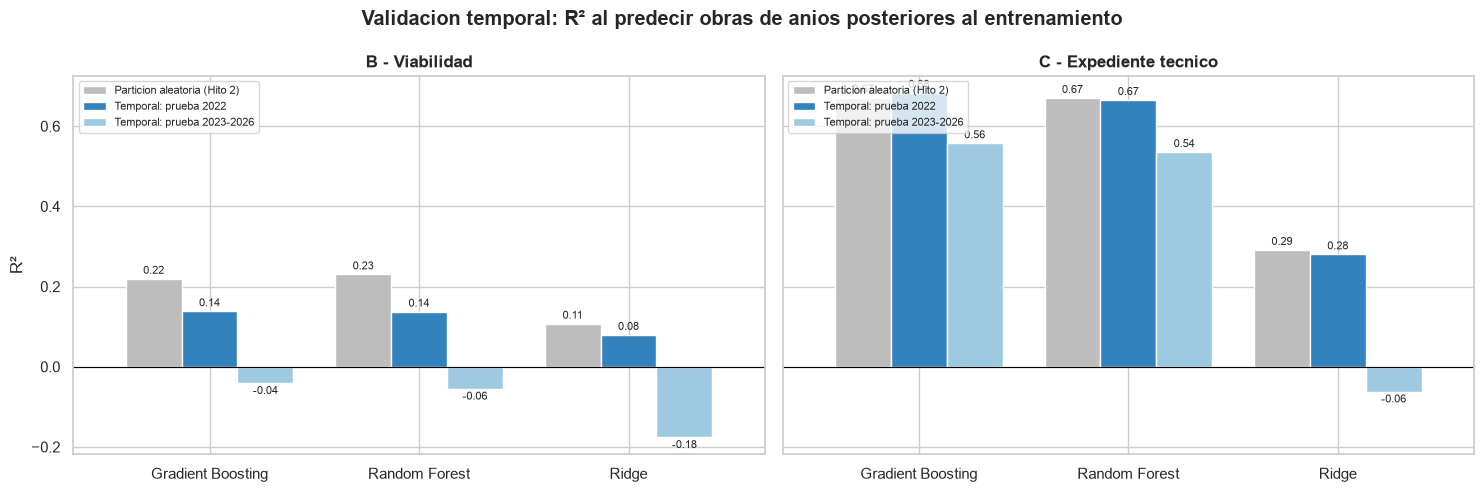

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
etiquetas_t = ['R2 particion aleatoria', '2022 (un anio adelante)', '2023-2026 (obras en curso)']
for ax, esc in zip(axes, ESCENARIOS):
    t = tabla_temporal[tabla_temporal['Escenario'] == esc].set_index('Modelo')[etiquetas_t]
    t.columns = ['Particion aleatoria (Hito 2)', 'Temporal: prueba 2022', 'Temporal: prueba 2023-2026']
    t.plot.bar(ax=ax, rot=0, width=0.8, color=['#bdbdbd', '#3182bd', '#9ecae1'])
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.2f', fontsize=8, padding=2)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(esc, fontweight='bold'); ax.set_xlabel(''); ax.set_ylabel('R²')
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('Validacion temporal: R² al predecir obras de anios posteriores al entrenamiento', fontweight='bold')
plt.tight_layout(); plt.show()

**Lectura de la validación temporal:**
- **Escenario C — robusto en el tiempo.** Entrenando solo con obras viabilizadas hasta 2021 (45,816 obras), Gradient Boosting predice las obras de **2022** con R² = **0.68**, igual que en la partición aleatoria (0.67). La relación entre el expediente técnico y el sobrecosto final es estable entre años.
- **Escenario B — más frágil.** Su R² baja de 0.22 (aleatoria) a **0.14** al predecir 2022. Parte de su desempeño con la partición aleatoria venía de "ver" en el entrenamiento obras contemporáneas (del mismo año, entidad y contexto de precios) a las que luego predecía. Con solo la información de la viabilidad es difícil anticipar las condiciones de los años siguientes.
- **Obras de 2023 a 2026 (41,116 obras aún en curso).** El R² de B es negativo (−0.04) y el sesgo medio es de **+10 pp**: el modelo predice más sobrecosto del que ya se registró. No es necesariamente un error: su mediana real hoy es de solo 9.3% porque muchas todavía no terminan, y el modelo anticipa sobrecostos que probablemente aparecerán. El modelo C se mantiene en R² = 0.56.
- **El orden de los modelos se mantiene:** Gradient Boosting ≥ Random Forest > Ridge en ambos escenarios y en ambas pruebas, así que la elección de 6.5.1 también vale en el escenario temporal.
- *Nota:* los MAE de esta sección no se comparan directamente con los de 6.5, porque los límites de Winsorización calculados con train ≤ 2021 son más amplios ([−104.3%, 177.4%]).
- **Implicancia práctica:** el modelo C se puede usar con confianza en obras nuevas; el modelo B debe usarse como **ordenador de riesgo** y reentrenarse cada año a medida que el MEF actualiza los costos.

### 6.6 Diagnóstico del mejor modelo

Se analiza el mejor modelo de cada escenario (elegido en 6.5.1). Como se vio en la Semana 4, el diagnóstico de residuos indica si el modelo tiene errores sistemáticos (por ejemplo, si subestima siempre los sobrecostos altos).

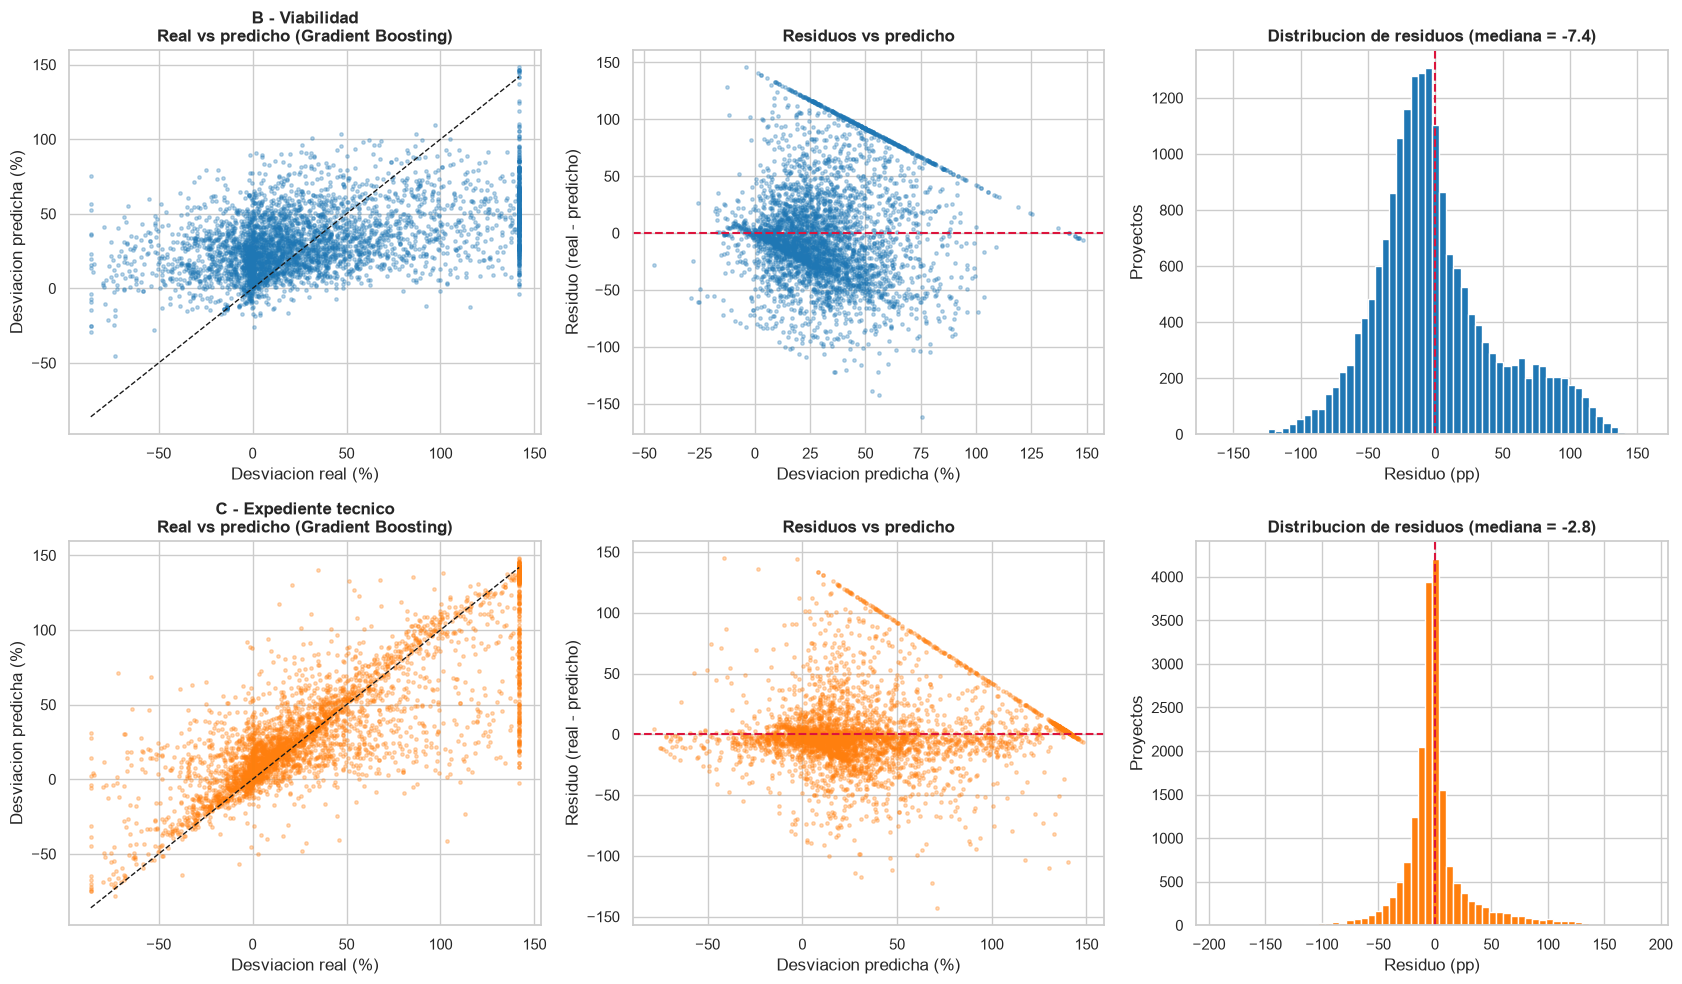

In [ ]:
rng = np.random.default_rng(SEMILLA)
muestra_idx = rng.choice(len(y_te), size=4000, replace=False)
y_real = y_te.to_numpy()

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for fila, esc in enumerate(ESCENARIOS):
    pred = preds_test[(esc, mejor_por_esc[esc])]
    resid = y_real - pred
    ax = axes[fila, 0]
    ax.scatter(y_real[muestra_idx], pred[muestra_idx], s=6, alpha=0.3, color=colores_esc[esc])
    ax.plot([lim_inf, lim_sup], [lim_inf, lim_sup], 'k--', lw=1)
    ax.set(title=f'{esc}\nReal vs predicho ({mejor_por_esc[esc]})', xlabel='Desviacion real (%)', ylabel='Desviacion predicha (%)')
    ax = axes[fila, 1]
    ax.scatter(pred[muestra_idx], resid[muestra_idx], s=6, alpha=0.3, color=colores_esc[esc])
    ax.axhline(0, color='crimson', ls='--')
    ax.set(title='Residuos vs predicho', xlabel='Desviacion predicha (%)', ylabel='Residuo (real - predicho)')
    ax = axes[fila, 2]
    ax.hist(resid, bins=60, color=colores_esc[esc])
    ax.axvline(0, color='crimson', ls='--')
    ax.set(title=f'Distribucion de residuos (mediana = {np.median(resid):.1f})', xlabel='Residuo (pp)', ylabel='Proyectos')
plt.tight_layout(); plt.show()

**Lectura de los residuos:**
- **B (Gradient Boosting):** las predicciones se mueven en un rango mucho más estrecho que los valores reales (casi todas entre −20% y 100%). Con la información disponible al aprobar la viabilidad, el modelo distingue obras "más riesgosas" de "menos riesgosas", pero **no logra anticipar los sobrecostos extremos**: las obras con desviación real ≥ 142% (la columna de la derecha) reciben predicciones de entre 0% y 100%. La mediana del residuo (−7.4 pp) indica que en la obra típica el modelo sobreestima levemente, un efecto de minimizar el error cuadrático en una variable con cola larga a la derecha.
- **C (Gradient Boosting):** la nube se alinea con la diagonal y los residuos se concentran alrededor de 0 (mediana −2.8 pp). El monto del expediente técnico permite estimar con bastante precisión la desviación final.
- **La línea diagonal de puntos en los gráficos de residuos** corresponde a las obras recortadas en el límite superior (141.9%): su valor real es fijo y el residuo depende solo de la predicción. Es un efecto de la Winsorización, no un error del modelo.
- En ambos casos el error crece con el tamaño de la desviación (heterocedasticidad): **el error es mayor justo en los casos más graves**.

In [ ]:
# Error por segmento: ¿en que tipo de obras se equivoca mas el modelo?
seg = df_model.loc[idx_test, ['FUNCION', 'NIVEL']].copy()
seg['real'] = y_real
for esc in ESCENARIOS:
    seg[f'err_{esc[0]}'] = np.abs(y_real - preds_test[(esc, mejor_por_esc[esc])])

err_funcion = (seg.groupby('FUNCION')
               .agg(n=('real', 'size'), desviacion_media=('real', 'mean'),
                    MAE_B=('err_B', 'mean'), MAE_C=('err_C', 'mean'))
               .query('n >= 300').sort_values('MAE_B', ascending=False).round(1))
err_nivel = (seg.groupby('NIVEL')
             .agg(n=('real', 'size'), desviacion_media=('real', 'mean'),
                  MAE_B=('err_B', 'mean'), MAE_C=('err_C', 'mean')).round(1))
print('Error absoluto medio (pp) por FUNCION en el conjunto de prueba (funciones con >= 300 proyectos):')
display(err_funcion)
print('Por NIVEL de gobierno:')
display(err_nivel)

Error absoluto medio (pp) por FUNCION en el conjunto de prueba (funciones con >= 300 proyectos):


,n,desviacion_media,MAE_B,MAE_C
FUNCION,,,,
CULTURA Y DEPORTE,1781,32.9,36.8,18.4
VIVIENDA Y DESARROLLO URBANO,1180,28.6,35.7,15.3
TRANSPORTE,4529,28.2,35.6,18.1
EDUCACIÓN,2500,40.5,35.1,18.6
SANEAMIENTO,2438,33.3,35.1,18.6
ENERGÍA,406,37.2,33.9,16.2
AGROPECUARIA,1372,32.2,33.7,16.0
ORDEN PÚBLICO Y SEGURIDAD,642,28.7,33.6,16.4
"PLANEAMIENTO, GESTIÓN Y RESERVA DE CONTINGENCIA",1692,26.4,33.0,17.2


Por NIVEL de gobierno:


,n,desviacion_media,MAE_B,MAE_C
NIVEL,,,,
GL,15451,29.5,35.2,17.4
GN,1730,38.4,30.7,19.5
GR,1713,41.3,34.8,20.6


**Error por segmento:** en el escenario C el error es parejo entre funciones (15–19 pp), así que el modelo no falla de forma sistemática en ningún tipo de obra. En B el error es mayor en Cultura y Deporte, Vivienda y Transporte (≈36 pp) y menor en Salud (29 pp). Por nivel de gobierno, en B los gobiernos locales (82% de las obras de prueba) y regionales tienen errores similares (≈35 pp) y el nivel nacional el menor (≈31 pp), aunque los gobiernos regionales y el nivel nacional tienen sobrecostos promedio más altos (≈40%).

### 6.7 Importancia de variables (permutation importance)

Para saber **qué variables usa cada modelo** se aplica *permutation importance* (Breiman, 2001) sobre el conjunto de prueba: se desordena al azar una variable a la vez y se mide cuánto empeora el R². Si el R² cae mucho, el modelo depende de esa variable. Se trabaja sobre las variables originales (antes del One-Hot), por lo que el resultado es directamente interpretable.

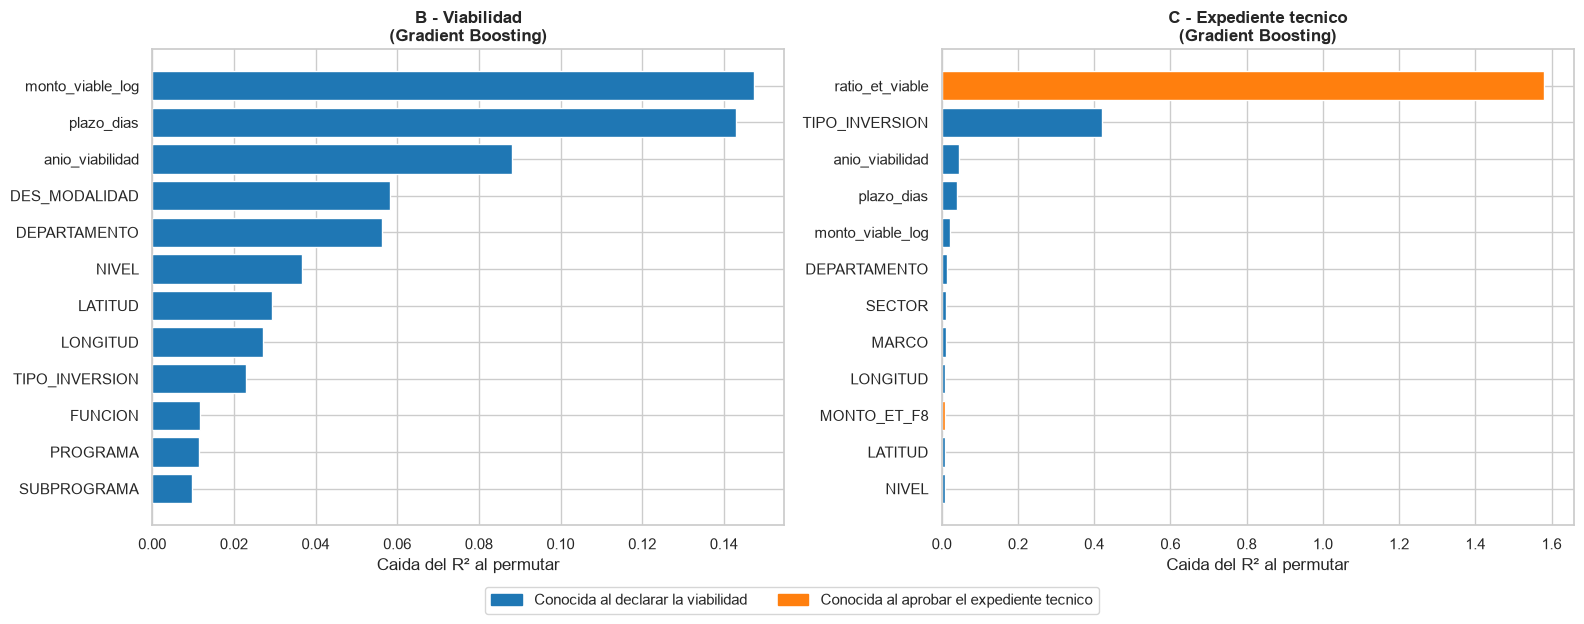

,B - Viabilidad,C - Expediente tecnico
Top 1,monto_viable_log,ratio_et_viable
Top 2,plazo_dias,TIPO_INVERSION
Top 3,anio_viabilidad,anio_viabilidad
Top 4,DES_MODALIDAD,plazo_dias
Top 5,DEPARTAMENTO,monto_viable_log
Top 6,NIVEL,DEPARTAMENTO
Top 7,LATITUD,SECTOR
Top 8,LONGITUD,MARCO


In [ ]:
muestra_pi = rng.choice(len(y_te), size=5000, replace=False)
importancias = {}
for esc in ESCENARIOS:
    cols = columnas(esc)
    pi = permutation_importance(pipes_finales[(esc, mejor_por_esc[esc])], X_te[cols].iloc[muestra_pi],
                                y_te.iloc[muestra_pi], scoring='r2', n_repeats=5, random_state=SEMILLA, n_jobs=1)
    importancias[esc] = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

expediente = {'MONTO_ET_F8', 'ratio_et_viable', 'EXPEDIENTE_TECNICO'}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, esc in zip(axes, ESCENARIOS):
    top = importancias[esc].head(12)[::-1]
    ax.barh(top.index, top.values, color=['#ff7f0e' if v in expediente else '#1f77b4' for v in top.index])
    ax.set_title(f'{esc}\n({mejor_por_esc[esc]})')
    ax.set_xlabel('Caida del R² al permutar')
leyenda = [Patch(color='#1f77b4', label='Conocida al declarar la viabilidad'),
           Patch(color='#ff7f0e', label='Conocida al aprobar el expediente tecnico')]
fig.legend(handles=leyenda, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(); plt.show()

pd.DataFrame({esc: importancias[esc].head(8).index.tolist() for esc in ESCENARIOS},
             index=[f'Top {i}' for i in range(1, 9)])

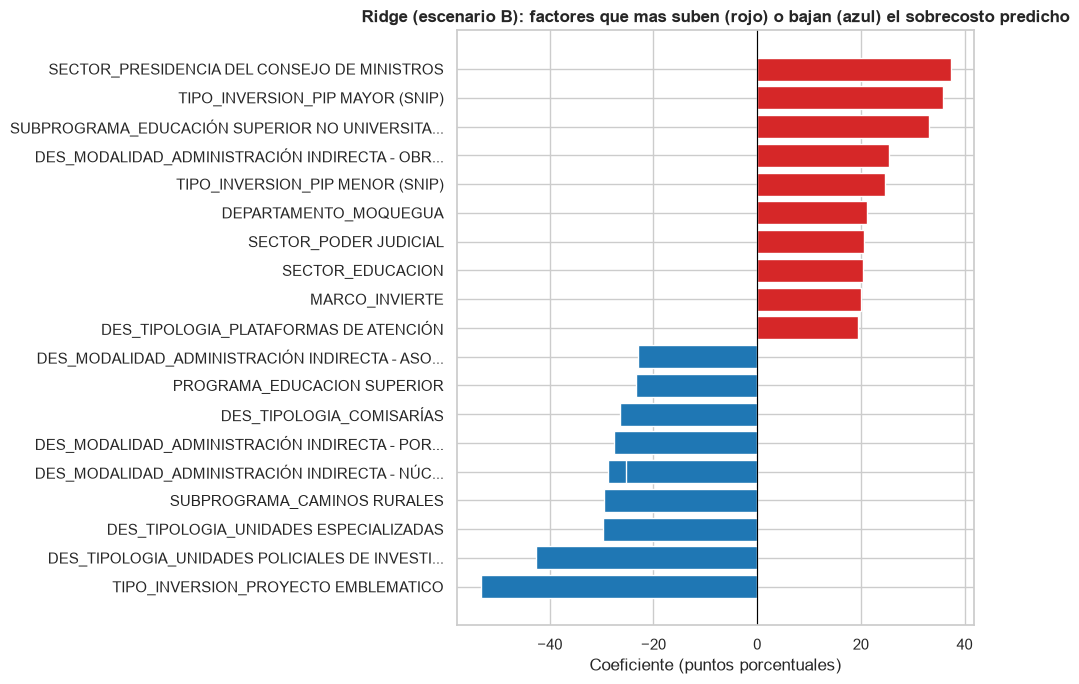

Pesos que el meta-modelo del Stacking asigna a cada modelo base:


,B - Viabilidad,C - Expediente tecnico
Ridge,-0.020,0.013
Arbol de Decision,-0.093,-0.039
Gradient Boosting,1.122,1.039


In [ ]:
# Interpretacion de direccion del efecto: coeficientes del modelo Ridge (escenario B).
# Las variables estan escaladas / codificadas, asi que el coeficiente indica cuantos puntos porcentuales
# sube (+) o baja (-) la desviacion predicha, manteniendo lo demas constante.
ridge_B = pipes_finales[('B - Viabilidad', 'Ridge')]
nombres = ridge_B.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(ridge_B.named_steps['modelo'].coef_, index=nombres)
coefs.index = coefs.index.str.replace('cat__', '').str.replace('num__', '')
top_coefs = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()

plt.figure(figsize=(10, 7))
plt.barh([etiqueta_corta(i, 45) for i in top_coefs.index], top_coefs.values,
         color=['#d62728' if v > 0 else '#1f77b4' for v in top_coefs.values])
plt.axvline(0, color='black', lw=0.8)
plt.title('Ridge (escenario B): factores que mas suben (rojo) o bajan (azul) el sobrecosto predicho')
plt.xlabel('Coeficiente (puntos porcentuales)')
plt.tight_layout(); plt.show()

# ¿Cuanto confia el Stacking en cada modelo base? (pregunta guia de la Semana 5)
pesos_stacking = pd.DataFrame({esc: pd.Series(pipes_finales[(esc, 'Stacking')].final_estimator_.coef_,
                                              index=['Ridge', 'Arbol de Decision', 'Gradient Boosting'])
                               for esc in ESCENARIOS}).round(3)
print('Pesos que el meta-modelo del Stacking asigna a cada modelo base:')
pesos_stacking

**Lectura de la importancia de variables:**
- **Escenario B:** la importancia está repartida. Las más útiles son el **tamaño de la obra** (`monto_viable_log`), el **plazo programado** (`plazo_dias`) y el **año de viabilidad**, seguidas por la modalidad de ejecución, el departamento y el nivel de gobierno. Ninguna variable explica por sí sola el sobrecosto, lo que es coherente con un R² moderado. En el EDA (sección 4.8) la correlación de Spearman del monto con el sobrecosto era casi nula; que aquí sea la más importante muestra que su efecto es **no lineal** y depende de otras variables, justo lo que capturan los modelos de árboles.
- **Escenario C:** `ratio_et_viable` (la desviación del expediente técnico) concentra casi todo el poder predictivo, seguida de `TIPO_INVERSION`. **El punto crítico donde se origina el sobrecosto es la elaboración del expediente técnico.**
- **Ridge (B)** indica la dirección de los efectos: los proyectos del antiguo SNIP (PIP mayor y PIP menor), los de Educación y la modalidad de Obras por Impuestos tienden a mayores sobrecostos; los proyectos emblemáticos, las tipologías policiales y los caminos rurales tienden a menores. Son asociaciones, no relaciones causales.
- **Stacking (pregunta guía de la Semana 5: ¿qué modelo aporta más información al meta-modelo?):** el meta-modelo asigna un peso cercano a **1.1 a Gradient Boosting** y pesos casi nulos a Ridge y al Árbol. Es decir, Stacking aprendió que Gradient Boosting ya contiene la información útil de los otros modelos, y por eso no lo supera.

### 6.8 Utilidad para el negocio: priorizar obras para supervisión

Un R² moderado no significa que el modelo no sirva. En la práctica, la Contraloría o la OPMI no necesitan el valor exacto del sobrecosto, sino **saber qué obras revisar primero** con recursos de supervisión limitados. Se evalúa entonces la capacidad del modelo de **ordenar** las obras por riesgo:

- Se define como **sobrecosto severo** una desviación real mayor a 50% (sobre la variable original, sin recortar).
- Se ordenan las obras del conjunto de prueba de mayor a menor sobrecosto predicho y se mide qué porcentaje de los casos severos se captura al revisar el 10%, 20% o 30% de obras con mayor riesgo predicho.
- Una revisión al azar capturaría, en promedio, el mismo porcentaje que se revisa (la diagonal del gráfico).

Obras con sobrecosto severo (> 50%) en prueba: 5,136 de 18,894 (27.2%)



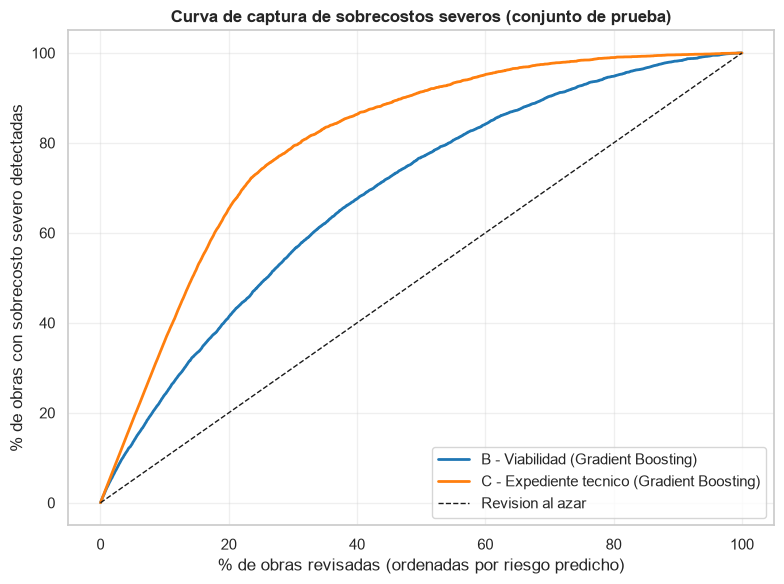

,Captura revisando el 10%,Captura revisando el 20%,Captura revisando el 30%
Escenario,,,
B - Viabilidad,24.0,41.3,56.0
C - Expediente tecnico,35.9,65.3,79.2


In [ ]:
severo = (y_bruto.loc[idx_test] > 50).to_numpy()
print(f'Obras con sobrecosto severo (> 50%) en prueba: {severo.sum():,} de {len(severo):,} ({severo.mean()*100:.1f}%)\n')

def curva_captura(pred, severo):
    orden = np.argsort(-pred)
    capturados = np.cumsum(severo[orden]) / severo.sum()
    revisados = np.arange(1, len(pred) + 1) / len(pred)
    return revisados, capturados

plt.figure(figsize=(8, 6))
filas_captura = []
for esc in ESCENARIOS:
    pred = preds_test[(esc, mejor_por_esc[esc])]
    rev, cap = curva_captura(pred, severo)
    plt.plot(rev * 100, cap * 100, '-', color=colores_esc[esc], lw=2, label=f'{esc} ({mejor_por_esc[esc]})')
    fila = {'Escenario': esc}
    for k in [0.10, 0.20, 0.30]:
        fila[f'Captura revisando el {int(k*100)}%'] = round(cap[int(k * len(cap)) - 1] * 100, 1)
    filas_captura.append(fila)
plt.plot([0, 100], [0, 100], 'k--', lw=1, label='Revision al azar')
plt.xlabel('% de obras revisadas (ordenadas por riesgo predicho)')
plt.ylabel('% de obras con sobrecosto severo detectadas')
plt.title('Curva de captura de sobrecostos severos (conjunto de prueba)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

df_captura = pd.DataFrame(filas_captura).set_index('Escenario')
df_captura

**Lectura de la curva de captura:** el 27.2% de las obras de prueba tuvo un sobrecosto severo (más de 50%). Si se revisa el 20% de obras con mayor riesgo predicho:
- con el **modelo B** (al declarar la viabilidad) se detecta el **41.3%** de los sobrecostos severos, **2.1 veces más** que revisando al azar (20%);
- con el **modelo C** (al aprobar el expediente técnico) se detecta el **65.3%**, **3.3 veces más** que al azar.

Así, aunque el R² de B sea moderado (0.22), el modelo sí es útil para **ordenar** las obras por riesgo y enfocar la supervisión.

### 6.9 Complemento no supervisado: segmentación de obras con K-Means y PCA

Los modelos anteriores son **supervisados** (aprenden a partir del sobrecosto conocido). Como complemento, se aplican técnicas **no supervisadas** de la clase (*Modelling — No Supervisado*) para responder otra pregunta de negocio: **¿existen grupos naturales de obras con perfiles parecidos, y alguno concentra más sobrecosto?**

- **K-Means** agrupa las obras según sus características iniciales, **sin usar el sobrecosto** para formar los grupos.
- El número de grupos K se elige con el **método del codo** (inercia) y el **Silhouette Score** (métricas vistas en clase), y se reporta también el **Davies–Bouldin Index** (menor es mejor).
- **PCA** reduce las variables a 2 componentes para **visualizar** los grupos.
- Al final se prueba si el grupo asignado por K-Means, usado como variable adicional, mejora al modelo supervisado del escenario B.

Se usan las 5 variables numéricas del escenario B (tamaño, plazo, año de viabilidad y ubicación), escaladas, y **solo el conjunto de entrenamiento**.

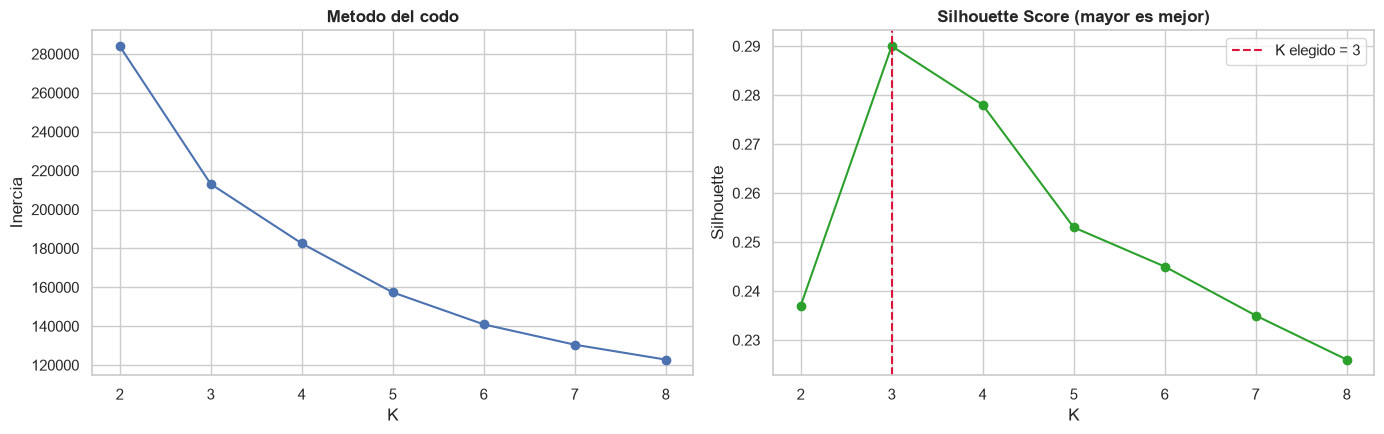

K elegido (maximo Silhouette): 3


,K,Inercia,Silhouette,Davies-Bouldin
0,2,284034.459,0.237,1.552
1,3,213138.619,0.290,1.274
2,4,182576.889,0.278,1.182
3,5,157385.900,0.253,1.249
4,6,140926.062,0.245,1.253
5,7,130478.236,0.235,1.257
6,8,122802.716,0.226,1.310


In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

vars_seg = ['monto_viable_log', 'plazo_dias', 'anio_viabilidad', 'LATITUD', 'LONGITUD']
prep_seg = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())])
Z_tr = prep_seg.fit_transform(X_tr[vars_seg])

muestra_sil = rng.choice(len(Z_tr), size=8000, replace=False)
filas_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_tr)
    filas_k.append({'K': k, 'Inercia': km.inertia_,
                    'Silhouette': silhouette_score(Z_tr[muestra_sil], km.labels_[muestra_sil]),
                    'Davies-Bouldin': davies_bouldin_score(Z_tr[muestra_sil], km.labels_[muestra_sil])})
df_k = pd.DataFrame(filas_k).round(3)
K_ELEGIDO = int(df_k.loc[df_k['Silhouette'].idxmax(), 'K'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(df_k['K'], df_k['Inercia'], 'o-'); axes[0].set(title='Metodo del codo', xlabel='K', ylabel='Inercia')
axes[1].plot(df_k['K'], df_k['Silhouette'], 'o-', color='#2ca02c')
axes[1].axvline(K_ELEGIDO, color='crimson', ls='--', label=f'K elegido = {K_ELEGIDO}')
axes[1].set(title='Silhouette Score (mayor es mejor)', xlabel='K', ylabel='Silhouette'); axes[1].legend()
plt.tight_layout(); plt.show()
print('K elegido (maximo Silhouette):', K_ELEGIDO)
df_k

,obras,monto_mediano_millones,plazo_mediano_dias,anio_mediano,departamento_mas_frecuente,desviacion_mediana,pct_sobrecosto_severo,% de obras
grupo,,,,,,,,
0,24507,0.8,765.0,2023.0,CUSCO,15.6,26.7,32.4
1,30776,0.8,525.0,2023.0,ANCASH,11.4,24.7,40.7
2,20292,3.0,2628.0,2016.0,LIMA,25.1,32.7,26.9


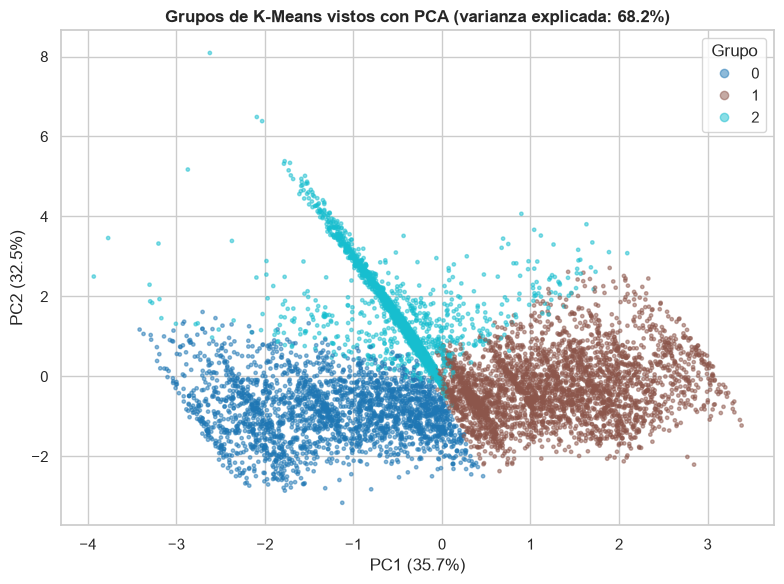

Cargas de PCA (como se construye cada componente):


,PC1,PC2
monto_viable_log,-0.12,0.51
plazo_dias,-0.21,0.62
anio_viabilidad,0.16,-0.51
LATITUD,0.69,0.17
LONGITUD,-0.66,-0.25


In [ ]:
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA).fit(Z_tr)
grupo_tr = kmeans.labels_

# Perfil de cada grupo (el sobrecosto se usa solo para DESCRIBIR los grupos, no para formarlos)
perfil = pd.DataFrame({'grupo': grupo_tr,
                       'monto_viable_mill': np.expm1(X_tr['monto_viable_log']) / 1e6,
                       'plazo_dias': X_tr['plazo_dias'], 'anio_viabilidad': X_tr['anio_viabilidad'],
                       'departamento': df_model.loc[idx_train, 'DEPARTAMENTO'],
                       'desviacion': y_bruto.loc[idx_train]})
perfil_grupos = perfil.groupby('grupo').agg(
    obras=('desviacion', 'size'),
    monto_mediano_millones=('monto_viable_mill', 'median'),
    plazo_mediano_dias=('plazo_dias', 'median'),
    anio_mediano=('anio_viabilidad', 'median'),
    departamento_mas_frecuente=('departamento', lambda s: s.mode().iloc[0]),
    desviacion_mediana=('desviacion', 'median'),
    pct_sobrecosto_severo=('desviacion', lambda s: (s > 50).mean() * 100)).round(1)
perfil_grupos['% de obras'] = (perfil_grupos['obras'] / perfil_grupos['obras'].sum() * 100).round(1)
display(perfil_grupos)

# Visualizacion con PCA (2 componentes)
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z_tr)
P = pca.transform(Z_tr[muestra_sil])
plt.figure(figsize=(8, 6))
sc = plt.scatter(P[:, 0], P[:, 1], c=grupo_tr[muestra_sil], cmap='tab10', s=6, alpha=0.5)
plt.legend(*sc.legend_elements(), title='Grupo', loc='best')
plt.title(f'Grupos de K-Means vistos con PCA (varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.tight_layout(); plt.show()

print('Cargas de PCA (como se construye cada componente):')
pd.DataFrame(pca.components_.T, index=vars_seg, columns=['PC1', 'PC2']).round(2)

In [ ]:
# ¿El grupo de K-Means mejora al modelo supervisado del escenario B?
X_tr_seg = X_tr.copy()
X_tr_seg['grupo_kmeans'] = grupo_tr.astype(str)
ESCENARIOS['B + grupo K-Means'] = {'num': num_B, 'cat': cat_B + ['grupo_kmeans']}
# Se usa Gradient Boosting ajustado (rapido y entre los mejores) con la misma validacion cruzada de 5 folds
gb_B = crear_modelos('B - Viabilidad', mejores_params['B - Viabilidad'])['Gradient Boosting']
res_seg = cross_validate(crear_pipeline('B + grupo K-Means', gb_B), X_tr_seg[columnas('B + grupo K-Means')],
                         y_tr, cv=cv, scoring=scoring)
res_sin = cross_validate(crear_pipeline('B - Viabilidad', gb_B), X_tr[columnas('B - Viabilidad')],
                         y_tr, cv=cv, scoring=scoring)
ESCENARIOS.pop('B + grupo K-Means')
pd.DataFrame({'Escenario B (sin grupo)': [-res_sin['test_RMSE'].mean(), res_sin['test_R2'].mean()],
              'Escenario B + grupo K-Means': [-res_seg['test_RMSE'].mean(), res_seg['test_R2'].mean()]},
             index=['RMSE_cv (Gradient Boosting)', 'R2_cv (Gradient Boosting)']).round(3)

,Escenario B (sin grupo),Escenario B + grupo K-Means
RMSE_cv (Gradient Boosting),46.040,46.046
R2_cv (Gradient Boosting),0.209,0.209


**Lectura del análisis no supervisado:**
- **K = 3** maximiza el Silhouette (0.29) y tiene un Davies–Bouldin bajo (1.27). El valor de Silhouette indica grupos **moderadamente separados**: hay estructura, pero las obras no forman grupos muy definidos.
- **PCA** con 2 componentes conserva el 68% de la varianza. PC1 está dominada por la **ubicación** (latitud y longitud), y PC2 por el **tamaño, el plazo y la antigüedad** de la obra.
- **Perfiles de los grupos** (el sobrecosto se usó solo para describirlos, no para formarlos):
  - **Grupo 2 (27% de las obras): obras grandes, de largo plazo y más antiguas** (mediana S/ 3 millones, ~7 años de plazo programado, viabilidad hacia 2016; Lima es el departamento más frecuente). Es el grupo con **más sobrecosto**: mediana 25.1% y 32.7% de obras con sobrecosto severo.
  - **Grupos 0 y 1 (73%): obras pequeñas y recientes** (mediana S/ 0.8 millones, viabilidad hacia 2023), separadas sobre todo por ubicación (Cusco y Áncash son los departamentos más frecuentes). Tienen medianas de 15.6% y 11.4%, y 25–27% de obras con sobrecosto severo.
- **¿Mejora al modelo supervisado?** No: agregar el grupo de K-Means como variable deja el R² de Gradient Boosting igual (0.209 → 0.209). Es lo esperable, porque los grupos se forman con las mismas variables que el modelo ya usa, y los árboles capturan esas combinaciones por sí solos.
- **Aporte:** K-Means no mejora la predicción, pero sí entrega una **segmentación fácil de comunicar** (obras grandes y antiguas vs. obras pequeñas y recientes por zona) que puede usarse en el Hito 3 para la visualización y la priorización.

### 6.10 Conclusiones del modelamiento

1. **Dos escenarios con justificación de negocio.** El modelo es preventivo, así que solo puede usar información que exista al momento de decidir. Por eso se modelaron los dos momentos de decisión de Invierte.pe: **B, al declarar la viabilidad**, y **C, al aprobar el expediente técnico**. Las variables se eligieron con tres filtros: influencia estadística (Hito 1), disponibilidad temporal y calidad/cardinalidad. B usa 16 variables de entrada y C, 19.

2. **Se compararon 7 modelos más un baseline**, incluidos dos ensambles de la Semana 5 (**Bagging** y **Stacking**), con validación cruzada de 5 folds, ajuste de hiperparámetros, una única evaluación en prueba y medición de tiempos. Todos superan al baseline, y los **ensambles de árboles superan claramente a los lineales**, porque el sobrecosto depende de combinaciones no lineales de factores.

3. **El mejor modelo es Gradient Boosting (`HistGradientBoostingRegressor`) en ambos escenarios**, según criterios definidos antes de ver los resultados. Empata en precisión con Random Forest y Stacking (diferencias menores al 1% del RMSE), pero es el que **menos sobreajusta** y el **más rápido** de los ensambles (~27 s de entrenamiento frente a 38–103 s de Random Forest, Bagging y Stacking). Bagging confirmó que reduce la varianza del árbol individual, y Stacking mostró que el meta-modelo confía casi solo en Gradient Boosting.

4. **La información disponible pesa más que el algoritmo.** Cambiar de modelo mejora el R² en centésimas; incorporar el expediente técnico lo triplica:
   - **B — al declarar la viabilidad:** R² = 0.22, MAE = 34.7 pp (baseline: 40.6 pp).
   - **C — al aprobar el expediente técnico:** R² = 0.67, MAE = 17.9 pp, menos de la mitad del error del baseline.

5. **Fuga de información demostrada con evidencia (observación del Hito 1).** Si se agregan las 18 variables excluidas a priori, el R² sube de 0.19 a 0.90 (0.99 con `COSTO_ACTUALIZADO`), porque devengados y saldos reconstruyen el costo final. Un modelo así luce excelente, pero no sirve para prevenir.

6. **Hallazgo de negocio: el sobrecosto se origina principalmente al elaborar el expediente técnico.** En el 31.7% de los proyectos el costo actualizado es idéntico al monto del expediente, y la desviación del expediente es la variable más importante del escenario C. La supervisión preventiva debería concentrarse en la revisión del expediente técnico, antes de licitar.

7. **Propuesta de uso en dos puntos de control:**
   - *Al declarar la viabilidad (modelo B):* revisando el 20% de obras de mayor riesgo se detecta el 41% de los sobrecostos severos (2.1 veces más que al azar).
   - *Al aprobar el expediente técnico (modelo C):* revisando el 20% de mayor riesgo se detecta el 65% (3.3 veces más que al azar).

8. **Complemento no supervisado.** K-Means identificó 3 segmentos de obras. El de obras grandes, de largo plazo y más antiguas concentra más sobrecosto (32.7% con sobrecosto severo). No mejora la predicción, pero aporta una segmentación útil para comunicar resultados.

9. **Limitaciones:**
   - Con la información inicial (B) el modelo no anticipa bien los sobrecostos extremos; el error crece en los casos más graves.
   - En C, parte del poder predictivo es "mecánico": en un tercio de los proyectos el costo actualizado copia el monto del expediente. Sin esos casos el R² baja de 0.67 a 0.57 (sección 6.5.3).
   - Con la partición aleatoria el modelo B se ve mejor de lo que rinde al predecir años futuros (R² 0.22 frente a 0.14 en la validación temporal de 6.5.4).
   - Los proyectos recientes (2022 en adelante) aún pueden actualizar su costo.

**Hito 3:** las observaciones del Hito 2 se levantaron en las secciones 6.5 (radar y error sobre el target original), 6.5.3 (revisión de `MONTO_ET_F8`) y 6.5.4 (validación temporal). La visualización y comunicación de resultados está en la sección 7.

## 7. Visualización y comunicación de resultados — Hito 3

En esta última etapa de CRISP-DM los resultados se llevan a un formato que puedan usar quienes toman decisiones (OPMI, Contraloría, gobiernos regionales y locales). La sección tiene tres partes:

| Sección | Contenido |
|---|---|
| 7.1 | Ejemplos concretos: obras de prueba priorizadas por el modelo |
| 7.2 | Exportación de modelos y resultados para la plataforma web |
| 7.3 | Plataforma web interactiva (Streamlit) |
| 7.4 | Conclusiones finales del proyecto |

### 7.1 Ejemplos concretos: ¿qué obras habría priorizado el modelo?

Se toman las obras del conjunto de prueba (nunca vistas en el entrenamiento) y se ordenan por el sobrecosto que predice el modelo C. Se muestran las 10 de mayor riesgo predicho y las 10 de menor riesgo, junto con lo que realmente pasó.

In [ ]:
ej = df_model.loc[idx_test, ['CODIGO_UNICO', 'NOMBRE_INVERSION', 'DEPARTAMENTO', 'FUNCION', 'NIVEL',
                             'MONTO_VIABLE', 'anio_viabilidad']].copy()
ej['pred_B'] = preds_test[('B - Viabilidad', mejor_por_esc['B - Viabilidad'])]
ej['pred_C'] = preds_test[('C - Expediente tecnico', mejor_por_esc['C - Expediente tecnico'])]
ej['desviacion_real'] = y_bruto.loc[idx_test]
ej['nombre'] = ej['NOMBRE_INVERSION'].str.slice(0, 70)
ej['monto_viable_mill'] = (ej['MONTO_VIABLE'] / 1e6).round(2)
cols_ej = ['CODIGO_UNICO', 'nombre', 'DEPARTAMENTO', 'FUNCION', 'monto_viable_mill', 'pred_B', 'pred_C', 'desviacion_real']

top_riesgo = ej.sort_values('pred_C', ascending=False).head(10)[cols_ej].round(1)
bajo_riesgo = ej.sort_values('pred_C').head(10)[cols_ej].round(1)
print('10 obras de prueba con MAYOR sobrecosto predicho por el modelo C:')
display(top_riesgo)
print(f"-> {(top_riesgo['desviacion_real'] > 50).sum()} de 10 tuvieron realmente un sobrecosto severo (> 50%).\n")
print('10 obras de prueba con MENOR sobrecosto predicho por el modelo C:')
display(bajo_riesgo)
print(f"-> {(bajo_riesgo['desviacion_real'] > 50).sum()} de 10 tuvieron realmente un sobrecosto severo (> 50%).")

10 obras de prueba con MAYOR sobrecosto predicho por el modelo C:


,CODIGO_UNICO,nombre,DEPARTAMENTO,FUNCION,monto_viable_mill,pred_B,pred_C,desviacion_real
82140,2195346,MEJORAMIENTO ADECUADO ACCESO DE LOS PESCADORES A LOS SERVICIOS PRESTAD,AREQUIPA,PESCA,21.9,80.1,164.4,221.7
143110,2430708,MEJORAMIENTO DEL SERVICIO EDUCATIVO DEL NIVEL INICIAL DE LA I.E.I N° 2,AMAZONAS,EDUCACIÓN,1.3,97.8,157.8,473.3
23653,2541186,CREACION DEL LOCAL COMUNAL COMERCIAL EN LA LOCALIDAD DE ZARUMILLA DEL,AMAZONAS,COMERCIO,0.2,43.7,154.2,336.2
127924,2460165,CREACION DE LA TROCHA CARROZABLE EN EL SECTOR COPLAY ANTIGUO DEL C.P.,MOQUEGUA,TRANSPORTE,0.9,90.2,153.9,791.6
145626,2419959,CREACION CARRETERA COROISE-UNIDAD AGRICOLA CHARILAQUE DEL DISTRITO DE,MOQUEGUA,TRANSPORTE,0.9,79.7,151.7,600.9
23590,2079052,MEJORAMIENTO Y AMPLIACION DE LOS SERVICIOS DE SALUD DEL CENTRO DE SA,MOQUEGUA,SALUD Y SANEAMIENTO,9.2,93.0,150.9,566.3
53724,2521484,CREACION DEL SERVICIO DEL SISTEMA DE ALERTA TEMPRANA FRENTE A PELIGROS,ANCASH,ORDEN PÚBLICO Y SEGURIDAD,3.6,84.1,150.5,581.9
94419,2566195,MEJORAMIENTO DEL SERVICIO DE TRANSITABILIDAD PEATONAL EN LA LOCALIDAD,TACNA,TRANSPORTE,1.2,85.1,149.7,271.8
147725,2434037,IRI EN LOCAL EDUCATIVO CON CÓDIGO DE LOCAL 731343,PIURA,EDUCACIÓN,0.0,153.1,149.4,3423.9
49243,2359309,MEJORAMIENTO SERVICIOS DEL DESEMBARCADERO PESQUERO ARTESANAL PUERTO HU,ANCASH,PESCA,26.8,58.7,149.3,122.4


-> 10 de 10 tuvieron realmente un sobrecosto severo (> 50%).

10 obras de prueba con MENOR sobrecosto predicho por el modelo C:


,CODIGO_UNICO,nombre,DEPARTAMENTO,FUNCION,monto_viable_mill,pred_B,pred_C,desviacion_real
113714,2566290,CREACION DEL SERVICIO DEPORTIVO EN EL CASERIO EL MILAGRO DEL DISTRITO,LA LIBERTAD,CULTURA Y DEPORTE,0.6,-18.4,-78.1,-73.4
32899,2461548,MEJORAMIENTO Y AMPLIACION DE MURO DE CONTENCION DEL CENTRO POBLADO PAJ,TUMBES,ORDEN PÚBLICO Y SEGURIDAD,2.5,-28.6,-77.4,-93.2
110450,2612893,CREACION DEL SERVICIO DE TRANSITABILIDAD VIAL INTERURBANA EN LA TROCHA,LA LIBERTAD,TRANSPORTE,1.9,-31.8,-76.3,-78.9
131426,2558843,CREACION DEL CAMINO VECINAL EMP. LI-127 (ANKALLARA) - ALTO EL PLOMO DE,LA LIBERTAD,TRANSPORTE,2.2,20.6,-76.0,-89.6
22182,2691027,MEJORAMIENTO Y AMPLIACION DE LOS SERVICIOS DE ESPACIOS PÚBLICOS URBANO,HUANCAVELICA,AMBIENTE,1.6,4.1,-75.7,-83.2
56982,2388369,MEJORAMIENTO DEL PUESTO DE SALUD AUSANTA EN LA COMUNIDAD CAMPESINA DE,CUSCO,SALUD,5.6,18.0,-75.6,-100.0
52180,2531945,CREACION DEL CAMINO VECINAL TRAMO: HATUN UJU - PACCHAPATA DEL DISTRIT,JUNIN,TRANSPORTE,2.4,-6.8,-75.0,-86.7
10677,2581113,CREACION DEL SERVICIO DE PROVISIÓN DE AGUA PARA RIEGO EN SECTOR PURKUR,LIMA,AGROPECUARIA,3.0,20.0,-74.5,-88.9
63981,2625153,MEJORAMIENTO DE LOS SERVICIOS DE APOYO AL DESARROLLO PRODUCTIVO EN EL,LORETO,"PLANEAMIENTO, GESTIÓN Y RESERVA DE CONTINGENCIA",8.0,-5.5,-74.1,-80.4
64430,2679003,MEJORAMIENTO DE LOS SERVICIOS OPERATIVOS O MISIONALES INSTITUCIONALES,PUNO,"PLANEAMIENTO, GESTIÓN Y RESERVA DE CONTINGENCIA",6.7,-8.6,-74.0,-90.5


-> 0 de 10 tuvieron realmente un sobrecosto severo (> 50%).


**Lectura de los ejemplos:** las 10 obras con mayor riesgo predicho por el modelo C tuvieron **todas** un sobrecosto severo real (entre 122% y 3,424%), y las 10 de menor riesgo predicho **ninguna** (todas terminaron por debajo de su monto viable, entre −73% y −100%). Los ejemplos también muestran la limitación vista en 6.5: el modelo identifica bien **qué** obras van a tener sobrecosto, pero subestima su **magnitud** en los casos extremos. Por ejemplo, la intervención en el local educativo de Piura recibió una predicción de 149% y su desviación real fue de 3,424%.

### 7.2 Exportación de modelos y resultados para la plataforma web

La plataforma no puede cargar el dataset completo (216 MB), así que esta celda guarda en la carpeta `app/datos/` solo lo necesario:

- Los dos modelos finales (Gradient Boosting de B y de C) entrenados con todo el conjunto de entrenamiento, con su preprocesamiento incluido (`joblib`).
- Las obras del conjunto de prueba con sus predicciones, para el ranking de priorización.
- Tablas resumidas: métricas de todos los modelos, validación cruzada, radar, validación temporal, fuga, revisión de `MONTO_ET_F8`, curva de captura, importancia de variables y segmentos de K-Means.
- Un catálogo de categorías válidas para el simulador.

In [ ]:
import json, joblib
from pathlib import Path

CARPETA_APP = Path('app') / 'datos'
CARPETA_APP.mkdir(parents=True, exist_ok=True)

def guardar_json(nombre, objeto):
    (CARPETA_APP / f'{nombre}.json').write_text(json.dumps(objeto, ensure_ascii=False, indent=1, default=float),
                                                 encoding='utf-8')

def registros(df):
    return json.loads(df.to_json(orient='records', force_ascii=False))

# 1. Modelos finales
for esc, archivo in [('B - Viabilidad', 'modelo_B'), ('C - Expediente tecnico', 'modelo_C')]:
    joblib.dump(pipes_finales[(esc, mejor_por_esc[esc])], CARPETA_APP / f'{archivo}.joblib', compress=3)

# 2. Obras de prueba con predicciones
obras = df_model.loc[idx_test, ['CODIGO_UNICO', 'NOMBRE_INVERSION', 'DEPARTAMENTO', 'PROVINCIA', 'FUNCION', 'NIVEL',
                                'TIPO_INVERSION', 'DES_MODALIDAD', 'anio_viabilidad', 'MONTO_VIABLE',
                                'LATITUD', 'LONGITUD']].copy()
obras['MONTO_ET_F8'] = pd.to_numeric(df_model.loc[idx_test, 'MONTO_ET_F8'], errors='coerce')
obras['COSTO_ACTUALIZADO'] = df_model.loc[idx_test, 'COSTO_ACTUALIZADO']
obras['pred_B'] = preds_test[('B - Viabilidad', mejor_por_esc['B - Viabilidad'])]
obras['pred_C'] = preds_test[('C - Expediente tecnico', mejor_por_esc['C - Expediente tecnico'])]
obras['desviacion_real'] = y_bruto.loc[idx_test]
obras.reset_index(drop=True).to_parquet(CARPETA_APP / 'obras_prueba.parquet', index=False)

# 3. Resumen del dataset completo de modelado (para la pagina de exploracion)
base = df_model[['DEPARTAMENTO', 'FUNCION', 'NIVEL', 'DES_MODALIDAD', 'TIPO_INVERSION', 'anio_viabilidad',
                 'MONTO_VIABLE', 'LATITUD', 'LONGITUD']].copy()
base['desviacion'] = y_bruto
base.reset_index(drop=True).to_parquet(CARPETA_APP / 'obras_modelo.parquet', index=False)

# 4. Catalogo de valores para el simulador
cat_C = ESCENARIOS['C - Expediente tecnico']['cat']
catalogo = {c: sorted(X_tr[c].dropna().astype(str).unique().tolist()) for c in cat_C}
jerarquia = (X_tr[['FUNCION', 'PROGRAMA', 'SUBPROGRAMA', 'DES_TIPOLOGIA', 'SECTOR']].dropna()
             .value_counts().reset_index(name='obras'))
jerarquia.to_parquet(CARPETA_APP / 'jerarquia.parquet', index=False)
centroides = X_tr.groupby('DEPARTAMENTO')[['LATITUD', 'LONGITUD']].median()
guardar_json('catalogo', {'categorias': catalogo,
                          'centroides': registros(centroides.reset_index()),
                          'tope_monto_viable_log': float(tope_sup),
                          'mediana_plazo_dias': float(X_tr['plazo_dias'].median())})

# 5. Resultados de la modelizacion
cortes = {esc: {'p50': float(np.percentile(preds_test[(esc, mejor_por_esc[esc])], 50)),
                'p80': float(np.percentile(preds_test[(esc, mejor_por_esc[esc])], 80))} for esc in ESCENARIOS}
ultimo = pd.to_numeric(df['ULTIMO_DEVENGADO'], errors='coerce').max()
guardar_json('meta', {'obras_total': int(len(df)), 'obras_modelo': int(len(df_model)),
                      'obras_train': int(len(idx_train)), 'obras_test': int(len(idx_test)),
                      'fecha_snapshot': f'{int(ultimo) // 100}-{int(ultimo) % 100:02d}',
                      'lim_inf': float(lim_inf), 'lim_sup': float(lim_sup),
                      'mejor_modelo': mejor_por_esc, 'cortes_riesgo': cortes})
guardar_json('metricas_test', registros(df_test))
guardar_json('metricas_cv', registros(df_cv))
guardar_json('radar', {esc: registros(p.reset_index().rename(columns={'index': 'Modelo'}))
                       for esc, p in puntajes_radar.items()})
guardar_json('temporal', {'detalle': registros(df_temporal), 'resumen': registros(tabla_temporal)})
guardar_json('fuga', registros(df_fuga))
guardar_json('revision_et', {'prueba1': registros(prueba1.reset_index().astype({'etapa': str})),
                             'prueba2': registros(prueba2.reset_index())})
curvas = {}
for esc in ESCENARIOS:
    rev, cap = curva_captura(preds_test[(esc, mejor_por_esc[esc])], severo)
    pasos = np.linspace(0, len(rev) - 1, 101).astype(int)
    curvas[esc] = {'revisado': (rev[pasos] * 100).round(2).tolist(), 'capturado': (cap[pasos] * 100).round(2).tolist()}
guardar_json('captura', {'curvas': curvas, 'tabla': registros(df_captura.reset_index()),
                         'pct_severo': float(severo.mean() * 100)})
guardar_json('importancias', {esc: registros(s.rename('importancia').reset_index().rename(columns={'index': 'variable'}))
                              for esc, s in importancias.items()})
guardar_json('kmeans', registros(perfil_grupos.reset_index()))

for f in sorted(CARPETA_APP.iterdir()):
    print(f'{f.name:28s} {f.stat().st_size / 1024:8.1f} KB')

captura.json                      5.0 KB
catalogo.json                    31.6 KB
fuga.json                         0.8 KB
importancias.json                 2.6 KB
jerarquia.parquet                15.3 KB
kmeans.json                       0.8 KB
meta.json                         0.5 KB
metricas_cv.json                  3.4 KB
metricas_test.json                6.2 KB
modelo_B.joblib                 946.4 KB
modelo_C.joblib                 952.4 KB
obras_modelo.parquet           3270.8 KB
obras_prueba.parquet           3005.1 KB
radar.json                        4.1 KB
revision_et.json                  2.0 KB
temporal.json                     3.5 KB


### 7.3 Plataforma web interactiva

Con los archivos exportados se construyó una aplicación web en **Streamlit** (carpeta `app/` del repositorio), publicada en Streamlit Community Cloud:

### 🔗 [https://sobrecostos-mef-peru.streamlit.app/](https://sobrecostos-mef-peru.streamlit.app/)

Tiene cinco páginas:

| Página | Para qué sirve |
|---|---|
| **Inicio** | Problema, cifras clave y cómo se usa el modelo en los dos momentos de decisión |
| **Explorar sobrecostos** | Mapa del Perú y gráficos interactivos de sobrecosto por departamento, función, nivel de gobierno y año |
| **Comparar modelos** | Radar multi-métrica, métricas en prueba y validación cruzada, validación temporal, fuga y revisión de `MONTO_ET_F8` |
| **Priorizar obras** | Ranking de obras por riesgo predicho con filtros, curva de captura y ejemplos |
| **Simulador** | Se ingresan los datos de una obra nueva y la app predice su sobrecosto con los modelos B y C |

Para correrla localmente: `pip install -r app/requirements.txt` y luego `streamlit run app/Inicio.py`.

### 7.4 Conclusiones finales del proyecto

**1. El problema y la respuesta.** El Estado peruano no tiene una herramienta para anticipar, al aprobar una obra, cuánto podría desviarse su costo. Con los datos abiertos del MEF (94,469 obras con costo actualizado) se construyeron modelos que estiman ese sobrecosto en los dos momentos de decisión de Invierte.pe, **antes de ejecutar la obra**:

| Momento de decisión | Mejor modelo | R² prueba | MAE (pp) | MedAE target original (pp) | Detecta revisando el 20% de obras |
|---|---|---|---|---|---|
| **B — Al declarar la viabilidad** | Gradient Boosting | 0.22 (0.14 en validación temporal) | 34.7 | 26.4 | 41% de los sobrecostos severos (2.1× al azar) |
| **C — Al aprobar el expediente técnico** | Gradient Boosting | 0.67 (0.57 sin casos espejo; 0.68 temporal) | 17.9 | 10.4 | 65% de los sobrecostos severos (3.3× al azar) |

**2. Comparación de modelos y modelo elegido.** Se compararon 7 modelos más un baseline (Regresión Lineal, Ridge, Árbol de Decisión, Bagging, Random Forest, Gradient Boosting y Stacking) con validación cruzada, ajuste de hiperparámetros, una evaluación única en prueba y una validación temporal. **Gradient Boosting (`HistGradientBoostingRegressor`) es el modelo que más ayudó a resolver el problema**, en los dos escenarios:
- Empata en precisión con Random Forest y Stacking (diferencias menores al 1% del RMSE).
- Es el que menos sobreajusta entre los ensambles y el más rápido de entrenar, lo que importa porque el modelo debe reentrenarse cada vez que el MEF actualiza los datos.
- En el radar es el ensamble más equilibrado (no se hunde en ningún eje) y mantiene su posición en la validación temporal.
- Stacking no lo supera porque su meta-modelo confía casi solo en él; Random Forest gana en RMSE en B pero memoriza (brecha de 0.25).

**3. Hallazgos principales.**
- **El sobrecosto se origina sobre todo al elaborar el expediente técnico.** La diferencia entre el expediente y el monto viable es la variable más importante del modelo C, y su incorporación triplica el R² (de 0.22 a 0.67). La información disponible pesa mucho más que el algoritmo.
- **La revisión de fuga en `MONTO_ET_F8` (observación del Hito 2)** indica que el campo es el monto del expediente aprobado: a medida que avanza la obra, el costo se separa del expediente en lugar de acercarse. Los casos espejo aportan unos 0.10 puntos de R², pero C mantiene 0.57–0.64 donde la fuga no es posible.
- **Las variables de ejecución "engañan":** con devengados y saldos el R² sube a 0.90 (0.99 con el costo actualizado), pero ese modelo no sirve para prevenir.
- **Con la información de la viabilidad (B) el modelo ordena bien pero predice poco:** distingue obras más y menos riesgosas, pero no anticipa la magnitud de los sobrecostos extremos, y pierde desempeño al predecir años futuros.
- **Segmentos de riesgo:** las obras grandes, de plazo largo y más antiguas concentran más sobrecosto (32.7% con sobrecosto severo frente a 25–27% en las obras pequeñas y recientes).

**4. Recomendación de uso.** Un esquema de supervisión en dos filtros:
1. Al declarar la viabilidad, el **modelo B** marca el 20% de obras de mayor riesgo para darles seguimiento desde el inicio.
2. Al aprobar el expediente técnico, el **modelo C** vuelve a ordenar las obras; las de mayor riesgo deberían pasar por una revisión del expediente **antes de licitar**, que es cuando todavía se puede corregir el diseño o el presupuesto.

La plataforma web ([https://sobrecostos-mef-peru.streamlit.app/](https://sobrecostos-mef-peru.streamlit.app/), sección 7.3) permite aplicar este esquema: explorar el sobrecosto por región y tipo de obra, comparar los modelos, priorizar obras y simular obras nuevas.

**5. Limitaciones.**
- La variable objetivo de las obras recientes (2023 en adelante) todavía no es definitiva: muchas no terminan y su sobrecosto puede seguir creciendo.
- Con un único *snapshot* no se puede verificar el historial de `MONTO_ET_F8` ni medir cómo cambia el sobrecosto de una misma obra en el tiempo.
- El modelo no anticipa la magnitud de los sobrecostos extremos (más de 142%), aunque sí los ubica entre las obras de mayor riesgo.
- Faltan variables que probablemente explican parte del sobrecosto y no están en el dataset: características del contratista, número de postores, precios de insumos o condiciones geográficas detalladas.

**6. Trabajo futuro.** Cruzar los datos con el SEACE (contrataciones) e INFOBRAS (Contraloría); construir un *snapshot* histórico para validar el modelo con obras ya cerradas; reentrenar el modelo cada año; y, para el escenario B, probar un enfoque de clasificación (sobrecosto severo sí/no) optimizado para la priorización.

## Referencias bibliográficas

### Sobrecostos en inversión pública

- Flyvbjerg, B., Holm, M. K. S., & Buhl, S. L. (2002). Underestimating costs in public works projects: Error or lie? *Journal of the American Planning Association, 68*(3), 279–295. https://doi.org/10.1080/01944360208976273

- Flyvbjerg, B. (2009). Survival of the unfittest: Why the worst infrastructure gets built—and what we can do about it. *Oxford Review of Economic Policy, 25*(3), 344–367.

- Cantarelli, C. C., Flyvbjerg, B., Molin, E. J. E., & van Wee, B. (2010). Cost overruns in large-scale transportation infrastructure projects: Explanations and their theoretical embeddedness. *European Journal of Transport and Infrastructure Research, 10*(1), 5–18.

- Love, P. E. D., Edwards, D. J., & Irani, Z. (2012). Moving beyond optimism bias and strategic misrepresentation: An explanation for social infrastructure project cost overruns. *IEEE Transactions on Engineering Management, 59*(4), 560–571.

### Machine Learning aplicado a estimación de costos

- Ahiaga-Dagbui, D. D., & Smith, S. D. (2014). Dealing with construction cost overruns using artificial neural networks. *Construction Management and Economics, 32*(11), 1060–1077.

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.

- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.

- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67.

- Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.

- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140.

- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.

- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the 5th Berkeley Symposium on Mathematical Statistics and Probability, 1*, 281–297.

- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65.

### Metodología

- Wirth, R., & Hipp, J. (2000). CRISP-DM: Towards a standard process model for data mining. *Proceedings of the 4th International Conference on the Practical Applications of Knowledge Discovery and Data Mining*, 29–39.

- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21.

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.

- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.

- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

### Fuente de datos

- Ministerio de Economía y Finanzas del Perú (MEF). (2024). *Detalle de Inversiones — Sistema Invierte.pe*. Portal de Datos Abiertos. https://datosabiertos.mef.gob.pe

- Ministerio de Economía y Finanzas del Perú (MEF). (2022). *Guía del Sistema Nacional de Programación Multianual y Gestión de Inversiones (Invierte.pe)*. Lima: MEF.